<a href="https://colab.research.google.com/github/contactvarun2002/-Multimodal-Deep-Learning-Based-Skin-Cancer-ClassificationThis-project-proposes/blob/main/Derm7pt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Mounted at /content/drive
DERM7PT - MULTIMODAL DATA PREPROCESSING
Dataset: /content/drive/MyDrive/Derm7pt/release_v0
Output: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed

Original metadata shape: (1011, 20)

Columns:
['case_num', 'diagnosis', 'seven_point_score', 'pigment_network', 'streaks', 'pigmentation', 'regression_structures', 'dots_and_globules', 'blue_whitish_veil', 'vascular_structures', 'level_of_diagnostic_difficulty', 'elevation', 'location', 'sex', 'management', 'clinic', 'derm', 'case_id', 'notes', 'Original_Row']

Discovered image files: 2013

Image availability:
Has_Clinical_Image     True
Has_Dermoscopic_Image      
True                   1011

Original split counts:
Split
train         413
test          395
validation    203
Name: count, dtype: int64

Original diagnosis categories:
Diagnosis_Normalized
clark nevus                     399
melanoma (less than 0.76 mm)    102
reed or spitz nevus              79
melanoma (in situ)               64
melanoma (0.76 to

Validating image pairs:   0%|          | 0/96 [00:00<?, ?it/s]

Hashing dermoscopic images:   0%|          | 0/96 [00:00<?, ?it/s]

Hashing clinical images:   0%|          | 0/96 [00:00<?, ?it/s]


Exact duplicate image pairs: 0

Overlapping lesion IDs: 0

Leakage verification passed.


...


Processed DataFrame created successfully.
Shape: (96, 8)
  Lesion_ID  Original_Row       Split             Diagnosis  Diagnosis_Code  \
0         1             0       train  Basal Cell Carcinoma               4   
1         2             1  validation  Basal Cell Carcinoma               4   
2         3             2       train  Basal Cell Carcinoma               4   
3         4             3        test  Basal Cell Carcinoma               4   
4         5             4       train  Basal Cell Carcinoma               4   

                                   Dermoscopic_Image  \
0  /content/drive/MyDrive/Derm7pt/Derm7pt_Preproc...   
1  /content/drive/MyDrive/Derm7pt/Derm7pt_Preproc...   
2  /content/drive/MyDrive/Derm7pt/Derm7pt_Preproc...   
3  /content/drive/MyDrive/Derm7pt/Derm7pt_Preproc...   
4  /content/drive/MyDrive/Derm7pt/Derm7pt_Preproc...   

                                      Clinical_Image  Is_Augmented  
0  /content/drive/MyDrive/Derm7pt/Derm7pt_Preproc...         

Augmenting training image pairs:   0%|          | 0/38 [00:00<?, ?it/s]

Checking saved dermoscopic images:   0%|          | 0/134 [00:00<?, ?it/s]

Checking saved clinical images:   0%|          | 0/134 [00:00<?, ?it/s]


All output validation checks passed.

FINAL DERM7PT PREPROCESSING SUMMARY

Original processed pairs: 96
Augmented pairs: 38
Total saved pairs: 134

Split distribution:
Split
test          38
train         38
validation    20
dtype: int64

Class distribution:
Split                 test  train  validation
Diagnosis                                    
Basal Cell Carcinoma    16     19           7
Melanoma                 1      0           0
Miscellaneous            2      3           3
Seborrheic Keratosis    19     16          10

Metadata feature count: 39


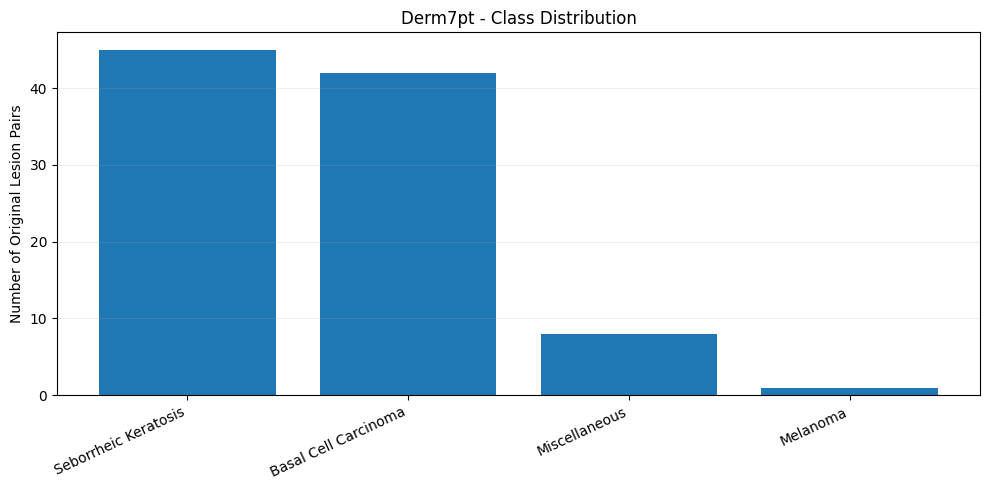

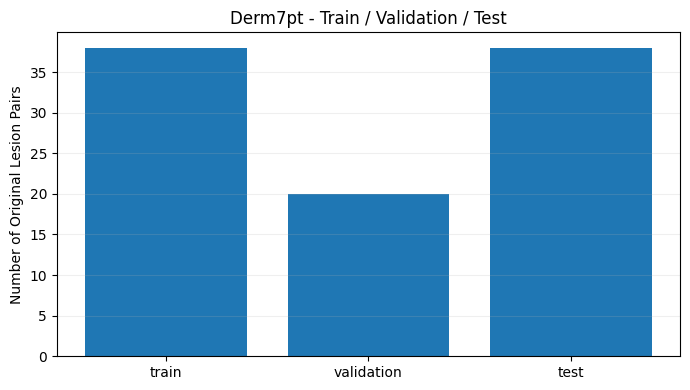

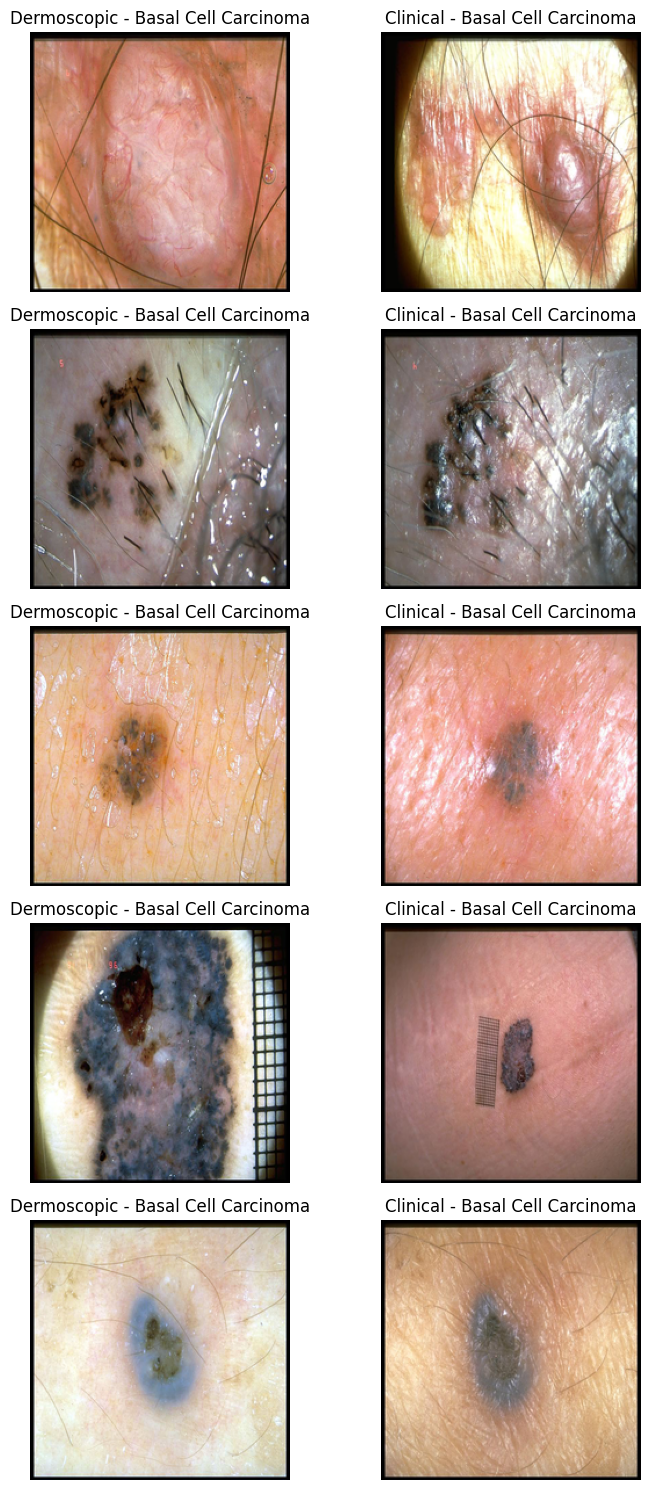


DERM7PT PREPROCESSING COMPLETED SUCCESSFULLY
Original image pairs: 96
Augmented pairs: 38
Total saved pairs: 134
Encoded metadata features: 39

SAVED FOLDERS:
Dermoscopic: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Dermoscopic
Clinical: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Clinical
Manifests: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Manifests
Metadata: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Metadata
Visualizations: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Visualizations
Reports: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Reports

NEXT PROCESS:
STEP 3 - LCTS-Net Lesion Segmentation


In [ ]:

# ================================================================
# DERM7PT - COMPLETE CORRECTED MULTIMODAL PREPROCESSING
# ================================================================
# PROJECT:
# Context-Aware Multimodal Skin Lesion Intelligence
#
# INPUT:
# /content/drive/MyDrive/Derm7pt/release_v0/
#     images/
#     meta/
#         meta.csv
#         train_indexes.csv
#         valid_indexes.csv
#         test_indexes.csv
#
# OUTPUT:
# /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/
#
# FIXES:
# - processed DataFrame created explicitly
# - Original_Row naming fixed
# - robust split index loading
# - lesion-level leakage prevention
# - case_num excluded from predictive features
# - no use of diagnosis-derived metadata as predictors
# - training-only metadata fitting
# - paired image preprocessing
# - training-only augmentation
# - output validation and visualization
# ================================================================

!pip -q install numpy pandas pillow matplotlib scikit-learn tqdm joblib

import os
import re
import json
import random
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from PIL import Image, ImageOps, ImageEnhance, ImageFile
from tqdm.auto import tqdm

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from google.colab import drive

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True

# ================================================================
# STEP 1 - CONFIGURATION
# ================================================================

SEED = 42
IMG_SIZE = (224, 224)
AUGMENT_COPIES = 1

# The project uses three aligned modalities.
REQUIRE_BOTH_IMAGES = True

# Use the five-class grouping specified in the concept.
FIVE_CLASS_MODE = True

random.seed(SEED)
np.random.seed(SEED)

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Derm7pt/release_v0")
META_DIR = ROOT / "meta"
IMAGE_DIR = ROOT / "images"

OUTPUT = Path(
    "/content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed"
)

DERM_OUT = OUTPUT / "Dermoscopic"
CLINICAL_OUT = OUTPUT / "Clinical"
MANIFEST_OUT = OUTPUT / "Manifests"
META_OUT = OUTPUT / "Metadata"
VIS_OUT = OUTPUT / "Visualizations"
REPORT_OUT = OUTPUT / "Reports"

for folder in [
    DERM_OUT, CLINICAL_OUT, MANIFEST_OUT,
    META_OUT, VIS_OUT, REPORT_OUT
]:
    folder.mkdir(parents=True, exist_ok=True)

assert META_DIR.is_dir(), f"Missing folder: {META_DIR}"
assert IMAGE_DIR.is_dir(), f"Missing folder: {IMAGE_DIR}"
assert (META_DIR / "meta.csv").is_file(), "meta.csv missing"

print("=" * 75)
print("DERM7PT - MULTIMODAL DATA PREPROCESSING")
print("=" * 75)
print("Dataset:", ROOT)
print("Output:", OUTPUT)

# ================================================================
# STEP 2 - LOAD ORIGINAL METADATA
# ================================================================

meta = pd.read_csv(META_DIR / "meta.csv")

# Preserve exact original row positions.
meta["Original_Row"] = np.arange(len(meta), dtype=int)

print("\nOriginal metadata shape:", meta.shape)
print("\nColumns:")
print(meta.columns.tolist())

# ================================================================
# STEP 3 - IDENTIFY REQUIRED COLUMNS
# ================================================================

def find_col(df, candidates, required=True):
    lookup = {
        str(c).strip().lower(): c
        for c in df.columns
    }

    for name in candidates:
        if name.lower() in lookup:
            return lookup[name.lower()]

    if required:
        raise ValueError(
            f"Missing column. Tried: {candidates}\n"
            f"Available: {df.columns.tolist()}"
        )

    return None

DERM_COL = find_col(
    meta,
    ["derm", "dermoscopic_image", "dermoscopic"]
)

CLINICAL_COL = find_col(
    meta,
    ["clinic", "clinical_image", "clinical"]
)

DIAG_COL = find_col(
    meta,
    ["diagnosis", "diagnostic", "label"]
)

# case_num is typically a case identifier.
ID_COL = find_col(
    meta,
    ["case_num", "case_id", "lesion_id", "patient_id"],
    required=False
)

if ID_COL:
    meta["Lesion_ID"] = meta[ID_COL].astype("string")
else:
    meta["Lesion_ID"] = meta["Original_Row"].astype("string")

# Missing IDs are replaced by unique original-row IDs.
missing_ids = (
    meta["Lesion_ID"].isna() |
    meta["Lesion_ID"].str.strip().eq("")
)

meta.loc[missing_ids, "Lesion_ID"] = (
    "row_" +
    meta.loc[missing_ids, "Original_Row"].astype(str)
)

meta["Lesion_ID"] = meta["Lesion_ID"].str.strip()

# ================================================================
# STEP 4 - RESOLVE IMAGE PATHS
# ================================================================

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("\nDiscovered image files:", len(image_files))

name_lookup = {}
stem_lookup = {}

for p in image_files:
    name_lookup.setdefault(p.name.lower(), []).append(p)
    stem_lookup.setdefault(p.stem.lower(), []).append(p)

def resolve_image(value):
    if pd.isna(value):
        return None

    name = str(value).strip()

    if not name or name.lower() in ("nan", "none"):
        return None

    p = Path(name)

    candidates = [
        p,
        IMAGE_DIR / p,
        ROOT / p
    ]

    for candidate in candidates:
        if candidate.is_file():
            return str(candidate)

    matches = name_lookup.get(p.name.lower(), [])

    if len(matches) == 1:
        return str(matches[0])

    matches = stem_lookup.get(p.stem.lower(), [])

    if len(matches) == 1:
        return str(matches[0])

    return None

meta["Dermoscopic_Original"] = (
    meta[DERM_COL].apply(resolve_image)
)

meta["Clinical_Original"] = (
    meta[CLINICAL_COL].apply(resolve_image)
)

meta["Has_Dermoscopic_Image"] = (
    meta["Dermoscopic_Original"].notna()
)

meta["Has_Clinical_Image"] = (
    meta["Clinical_Original"].notna()
)

print("\nImage availability:")
print(pd.crosstab(
    meta["Has_Dermoscopic_Image"],
    meta["Has_Clinical_Image"]
))

# ================================================================
# STEP 5 - LOAD ORIGINAL SPLIT INDICES
# ================================================================
# Supports:
# - one-column CSV without a header
# - one-column CSV with a header
# - pandas-exported CSV with an unnamed index column
#
# Ambiguous formats are rejected rather than guessed.
# ================================================================

def load_indices(path, n_rows):

    if not path.is_file():
        raise FileNotFoundError(path)

    raw = pd.read_csv(path, header=None, dtype=str)

    # Strip an optional header row.
    first = str(raw.iloc[0, 0]).strip().lower()

    if first in ("index", "indices", "idx", "row"):
        raw = raw.iloc[1:].copy()

    candidate_columns = []

    for col in raw.columns:

        numeric = pd.to_numeric(
            raw[col], errors="coerce"
        )

        valid = numeric.dropna()

        if valid.empty:
            continue

        if not np.all(
            np.equal(valid, np.floor(valid))
        ):
            continue

        valid = valid.astype(int)

        if not valid.between(0, n_rows - 1).all():
            continue

        candidate_columns.append(
            (col, valid.tolist())
        )

    if len(candidate_columns) == 0:
        raise ValueError(
            f"No valid row-index column in {path}"
        )

    if len(candidate_columns) == 1:
        return candidate_columns[0][1]

    # If multiple columns are present, a common export
    # format is: exported row number + actual index.
    # Prefer a column explicitly labeled as index.
    with_header = pd.read_csv(path)

    explicit = [
        c for c in with_header.columns
        if str(c).lower().strip() in (
            "index", "indices", "idx", "row"
        )
    ]

    if len(explicit) == 1:
        values = pd.to_numeric(
            with_header[explicit[0]],
            errors="raise"
        ).astype(int).tolist()

        if all(0 <= x < n_rows for x in values):
            return values

    raise ValueError(
        f"Ambiguous split-index CSV: {path}\n"
        "Inspect its columns and specify which column "
        "contains the original metadata row indices."
    )

split_files = {
    "train": META_DIR / "train_indexes.csv",
    "validation": META_DIR / "valid_indexes.csv",
    "test": META_DIR / "test_indexes.csv"
}

split_indices = {
    name: load_indices(path, len(meta))
    for name, path in split_files.items()
}

for name, indices in split_indices.items():
    if len(indices) != len(set(indices)):
        raise ValueError(
            f"Duplicate indices within {name} split"
        )

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = (
        set(split_indices[a]) &
        set(split_indices[b])
    )

    if overlap:
        raise ValueError(
            f"Original row-index overlap: {a} / {b}: "
            f"{len(overlap)}"
        )

meta["Split"] = "unassigned"

for split, indices in split_indices.items():
    meta.loc[
        meta["Original_Row"].isin(indices),
        "Split"
    ] = split

print("\nOriginal split counts:")
print(meta["Split"].value_counts())

# ================================================================
# STEP 6 - DIAGNOSIS LABEL MAPPING
# ================================================================

def normalize_label(value):
    if pd.isna(value):
        return ""

    text = str(value).lower().strip()
    text = re.sub(r"[_\-/]+", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text

meta["Diagnosis_Raw"] = meta[DIAG_COL]

meta["Diagnosis_Normalized"] = (
    meta[DIAG_COL].apply(normalize_label)
)

print("\nOriginal diagnosis categories:")
print(meta["Diagnosis_Normalized"].value_counts())

# Explicit five-class mapping.
# These categories must be checked against meta.csv.
LABEL_MAP = {
    "nevus": 0,
    "melanocytic nevus": 0,
    "melanoma": 1,
    "miscellaneous": 2,
    "miscellaneous lesions": 2,
    "seborrheic keratosis": 3,
    "basal cell carcinoma": 4
}

CLASS_NAMES = {
    0: "Nevus",
    1: "Melanoma",
    2: "Miscellaneous",
    3: "Seborrheic Keratosis",
    4: "Basal Cell Carcinoma"
}

meta["Diagnosis_Code"] = (
    meta["Diagnosis_Normalized"].map(LABEL_MAP)
)

meta[
    meta["Diagnosis_Code"].isna()
].to_csv(
    REPORT_OUT / "Unmapped_Diagnoses.csv",
    index=False
)

meta = meta[
    meta["Diagnosis_Code"].notna()
].copy()

meta["Diagnosis_Code"] = (
    meta["Diagnosis_Code"].astype(int)
)

meta["Diagnosis"] = (
    meta["Diagnosis_Code"].map(CLASS_NAMES)
)

# ================================================================
# STEP 7 - FILTER MISSING IMAGE PAIRS
# ================================================================

before = len(meta)

if REQUIRE_BOTH_IMAGES:
    meta = meta[
        meta["Has_Dermoscopic_Image"] &
        meta["Has_Clinical_Image"]
    ].copy()

meta = meta[
    meta["Split"].isin(
        ["train", "validation", "test"]
    )
].copy()

print("\nRows before pair filtering:", before)
print("Rows after pair filtering:", len(meta))

# ================================================================
# STEP 8 - VALIDATE IMAGE FILES
# ================================================================

def valid_image(path):
    try:
        with Image.open(path) as image:
            image.verify()
        return True
    except Exception:
        return False

valid_pairs = []

for row in tqdm(
    meta.itertuples(index=False),
    total=len(meta),
    desc="Validating image pairs"
):
    valid_pairs.append(
        valid_image(row.Dermoscopic_Original)
        and valid_image(row.Clinical_Original)
    )

meta["Valid_Pair"] = valid_pairs

meta[
    ~meta["Valid_Pair"]
].to_csv(
    REPORT_OUT / "Invalid_Image_Pairs.csv",
    index=False
)

meta = meta[
    meta["Valid_Pair"]
].copy()

if meta.empty:
    raise RuntimeError(
        "No valid paired images remain."
    )

# ================================================================
# STEP 9 - EXACT DUPLICATE PAIR DETECTION
# ================================================================

def md5_file(path):
    digest = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

meta["Derm_MD5"] = [
    md5_file(p)
    for p in tqdm(
        meta["Dermoscopic_Original"],
        desc="Hashing dermoscopic images"
    )
]

meta["Clinical_MD5"] = [
    md5_file(p)
    for p in tqdm(
        meta["Clinical_Original"],
        desc="Hashing clinical images"
    )
]

meta["Pair_Hash"] = (
    meta["Derm_MD5"] + "|" +
    meta["Clinical_MD5"]
)

# Check whether exact duplicates have conflicting labels.
conflicting_hashes = (
    meta.groupby("Pair_Hash")["Diagnosis_Code"]
    .nunique()
)

conflicting_hashes = set(
    conflicting_hashes[
        conflicting_hashes > 1
    ].index
)

if conflicting_hashes:
    raise ValueError(
        f"{len(conflicting_hashes)} exact image pairs "
        "have conflicting diagnosis labels."
    )

# Keep the first occurrence of an exact duplicate pair.
duplicates = meta.duplicated(
    subset=["Pair_Hash"],
    keep="first"
)

meta[duplicates].to_csv(
    REPORT_OUT / "Duplicate_Image_Pairs.csv",
    index=False
)

print("\nExact duplicate image pairs:", duplicates.sum())

meta = meta[
    ~duplicates
].copy()

# ================================================================
# STEP 10 - RESOLVE LESION SPLIT OVERLAP
# ================================================================
# If the same lesion ID occurs across partitions,
# assign all its remaining rows to the split in which
# it first appeared, with train > validation > test.
#
# Save all changes for audit.
# ================================================================

priority = {
    "train": 0,
    "validation": 1,
    "test": 2
}

meta["Split_Priority"] = (
    meta["Split"].map(priority)
)

overlap_counts = (
    meta.groupby("Lesion_ID")["Split"]
    .nunique()
)

leaked_ids = overlap_counts[
    overlap_counts > 1
].index.tolist()

print("\nOverlapping lesion IDs:", len(leaked_ids))

if leaked_ids:
    meta[
        meta["Lesion_ID"].isin(leaked_ids)
    ].to_csv(
        REPORT_OUT / "Leakage_Before_Fix.csv",
        index=False
    )

    chosen = (
        meta.sort_values("Split_Priority")
        .drop_duplicates("Lesion_ID")
        .set_index("Lesion_ID")["Split"]
        .to_dict()
    )

    meta["Split"] = (
        meta["Lesion_ID"].map(chosen)
    )

meta = meta.drop(
    columns=["Split_Priority"]
)

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:

    ids_a = set(
        meta.loc[
            meta["Split"] == a,
            "Lesion_ID"
        ]
    )

    ids_b = set(
        meta.loc[
            meta["Split"] == b,
            "Lesion_ID"
        ]
    )

    overlap = ids_a & ids_b

    if overlap:
        raise RuntimeError(
            f"Leakage remains between {a} and {b}"
        )

print("\nLeakage verification passed.")

meta[
    [
        "Lesion_ID",
        "Original_Row",
        "Split",
        "Diagnosis",
        "Diagnosis_Code"
    ]
].to_csv(
    REPORT_OUT / "Final_Split_Assignments.csv",
    index=False
)

# ================================================================
# STEP 11 - PREPROCESS AND SAVE IMAGE PAIRS
# ================================================================

def save_resized_rgb(source, destination):
    with Image.open(source) as image:
        image = ImageOps.exif_transpose(image)
        image = image.convert("RGB")
        image = image.resize(
            IMG_SIZE,
            Image.Resampling.LANCZOS
        )
        image.save(destination, format="PNG")

processed_records = []

for row in tqdm(
    meta.itertuples(index=False),
    total=len(meta),
    desc="Resizing paired images"
):

    # Original_Row now works reliably.
    uid = hashlib.sha1(
        (
            str(row.Lesion_ID) + "|" +
            str(row.Original_Row)
        ).encode("utf-8")
    ).hexdigest()[:12]

    filename = f"lesion_{uid}.png"

    class_folder = row.Diagnosis.replace(
        " ", "_"
    )

    derm_folder = (
        DERM_OUT / row.Split / class_folder
    )

    clinical_folder = (
        CLINICAL_OUT / row.Split / class_folder
    )

    derm_folder.mkdir(
        parents=True, exist_ok=True
    )

    clinical_folder.mkdir(
        parents=True, exist_ok=True
    )

    derm_path = derm_folder / filename
    clinical_path = clinical_folder / filename

    save_resized_rgb(
        row.Dermoscopic_Original,
        derm_path
    )

    save_resized_rgb(
        row.Clinical_Original,
        clinical_path
    )

    processed_records.append({
        "Lesion_ID": str(row.Lesion_ID),
        "Original_Row": int(row.Original_Row),
        "Split": row.Split,
        "Diagnosis": row.Diagnosis,
        "Diagnosis_Code": int(row.Diagnosis_Code),
        "Dermoscopic_Image": str(derm_path),
        "Clinical_Image": str(clinical_path),
        "Is_Augmented": False
    })

# Explicitly create the variable before augmentation.
processed = pd.DataFrame(processed_records)

if processed.empty:
    raise RuntimeError(
        "No processed image pairs were created."
    )

print("\nProcessed DataFrame created successfully.")
print("Shape:", processed.shape)
print(processed.head())

# ================================================================
# STEP 12 - METADATA FEATURE SELECTION
# ================================================================
# Exclude identifiers and fields that may encode diagnosis
# or clinical management decisions.
#
# seven_point_score is excluded by default because it is
# derived from diagnostic criteria and can create an
# overly optimistic evaluation in some study designs.
# ================================================================

EXCLUDE_METADATA = {
    DERM_COL,
    CLINICAL_COL,
    DIAG_COL,
    ID_COL,
    "Original_Row",
    "Lesion_ID",
    "Split",
    "Diagnosis",
    "Diagnosis_Code",
    "Diagnosis_Raw",
    "Diagnosis_Normalized",
    "Dermoscopic_Original",
    "Clinical_Original",
    "Has_Dermoscopic_Image",
    "Has_Clinical_Image",
    "Valid_Pair",
    "Derm_MD5",
    "Clinical_MD5",
    "Pair_Hash",
    "case_num",
    "seven_point_score",
    "management",
    "notes"
}

metadata_columns = [
    col for col in meta.columns
    if col not in EXCLUDE_METADATA
]

numeric_cols = [
    c for c in metadata_columns
    if pd.api.types.is_numeric_dtype(meta[c])
]

categorical_cols = [
    c for c in metadata_columns
    if c not in numeric_cols
]

print("\nNumerical metadata:", numeric_cols)
print("Categorical metadata:", categorical_cols)

if not metadata_columns:
    raise ValueError(
        "No metadata predictors remain after exclusions."
    )

# ================================================================
# STEP 13 - TRAIN-ONLY METADATA ENCODING
# ================================================================

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

transformers = []

if numeric_cols:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_cols)
    )

if categorical_cols:
    transformers.append(
        (
            "categorical",
            categorical_pipeline,
            categorical_cols
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    verbose_feature_names_out=True
)

train_meta = meta[
    meta["Split"] == "train"
]

if train_meta.empty:
    raise RuntimeError(
        "Training split is empty."
    )

preprocessor.fit(train_meta[metadata_columns])

encoded_array = preprocessor.transform(
    meta[metadata_columns]
)

feature_names = (
    preprocessor.get_feature_names_out()
)

encoded_df = pd.DataFrame(
    encoded_array,
    columns=feature_names,
    index=meta.index
)

encoded_df.insert(
    0, "Lesion_ID",
    meta["Lesion_ID"].astype(str)
)

encoded_df.insert(
    1, "Original_Row",
    meta["Original_Row"].astype(int)
)

encoded_df.insert(
    2, "Split",
    meta["Split"]
)

encoded_df.insert(
    3, "Diagnosis_Code",
    meta["Diagnosis_Code"].astype(int)
)

encoded_df.to_csv(
    META_OUT / "Encoded_Metadata.csv",
    index=False
)

joblib.dump(
    preprocessor,
    META_OUT / "Metadata_Preprocessor.joblib"
)

# Keep unencoded categorical features for FT-Transformer.
raw_metadata = meta[
    [
        "Lesion_ID",
        "Original_Row",
        "Split",
        "Diagnosis_Code"
    ] + metadata_columns
].copy()

raw_metadata.to_csv(
    META_OUT / "FTTransformer_Raw_Metadata.csv",
    index=False
)

print("\nEncoded metadata dimension:",
      encoded_array.shape[1])

# ================================================================
# STEP 14 - TRAINING-ONLY IMAGE AUGMENTATION
# ================================================================

def augment_pair(derm_path, clinical_path, seed):

    rng = random.Random(seed)

    with Image.open(derm_path) as img:
        derm = img.convert("RGB").copy()

    with Image.open(clinical_path) as img:
        clinical = img.convert("RGB").copy()

    angle = rng.choice([0, 90, 180, 270])
    flip_h = rng.choice([True, False])
    flip_v = rng.choice([True, False])

    outputs = []

    for image in [derm, clinical]:

        if flip_h:
            image = ImageOps.mirror(image)

        if flip_v:
            image = ImageOps.flip(image)

        image = image.rotate(angle)

        brightness = rng.uniform(0.90, 1.10)

        image = ImageEnhance.Brightness(
            image
        ).enhance(brightness)

        outputs.append(image)

    return outputs

augmented_records = []

train_processed = processed[
    processed["Split"] == "train"
].copy()

print("\nTraining samples before augmentation:",
      len(train_processed))

for row in tqdm(
    train_processed.itertuples(index=False),
    total=len(train_processed),
    desc="Augmenting training image pairs"
):

    for copy_num in range(AUGMENT_COPIES):

        seed_text = (
            str(row.Lesion_ID) + "|" +
            str(row.Original_Row) + "|" +
            str(copy_num)
        )

        augmentation_seed = int(
            hashlib.sha1(
                seed_text.encode("utf-8")
            ).hexdigest()[:8],
            16
        ) + SEED

        derm_aug, clinical_aug = augment_pair(
            row.Dermoscopic_Image,
            row.Clinical_Image,
            augmentation_seed
        )

        derm_path = Path(row.Dermoscopic_Image)
        clinical_path = Path(row.Clinical_Image)

        filename = (
            derm_path.stem +
            f"_aug_{copy_num + 1}.png"
        )

        derm_aug_path = (
            derm_path.parent / filename
        )

        clinical_aug_path = (
            clinical_path.parent / filename
        )

        derm_aug.save(derm_aug_path)
        clinical_aug.save(clinical_aug_path)

        augmented_records.append({
            "Lesion_ID": row.Lesion_ID,
            "Original_Row": row.Original_Row,
            "Split": "train",
            "Diagnosis": row.Diagnosis,
            "Diagnosis_Code": row.Diagnosis_Code,
            "Dermoscopic_Image": str(derm_aug_path),
            "Clinical_Image": str(clinical_aug_path),
            "Is_Augmented": True
        })

if augmented_records:
    processed_all = pd.concat(
        [
            processed,
            pd.DataFrame(augmented_records)
        ],
        ignore_index=True
    )
else:
    processed_all = processed.copy()

# ================================================================
# STEP 15 - SAVE MANIFESTS
# ================================================================

manifest_names = {
    "train": "09_Train_Image_Manifest.csv",
    "validation": "09_Validation_Image_Manifest.csv",
    "test": "09_Test_Image_Manifest.csv"
}

for split, filename in manifest_names.items():

    subset = processed_all[
        processed_all["Split"] == split
    ].copy()

    subset.to_csv(
        MANIFEST_OUT / filename,
        index=False
    )

processed.to_csv(
    MANIFEST_OUT / "Original_Image_Pairs.csv",
    index=False
)

processed_all.to_csv(
    MANIFEST_OUT / "All_Processed_Images.csv",
    index=False
)

# ================================================================
# STEP 16 - FINAL VALIDATION
# ================================================================

assert len(processed) > 0
assert processed["Dermoscopic_Image"].notna().all()
assert processed["Clinical_Image"].notna().all()

for path in tqdm(
    processed_all["Dermoscopic_Image"],
    desc="Checking saved dermoscopic images"
):
    if not Path(path).is_file():
        raise FileNotFoundError(path)

for path in tqdm(
    processed_all["Clinical_Image"],
    desc="Checking saved clinical images"
):
    if not Path(path).is_file():
        raise FileNotFoundError(path)

# Verify no lesion appears in multiple splits.
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:

    ids_a = set(
        processed_all.loc[
            processed_all["Split"] == a,
            "Lesion_ID"
        ]
    )

    ids_b = set(
        processed_all.loc[
            processed_all["Split"] == b,
            "Lesion_ID"
        ]
    )

    assert not (ids_a & ids_b), (
        f"Lesion leakage between {a} and {b}"
    )

# Verify metadata can be joined to image pairs.
metadata_keys = set(
    zip(
        encoded_df["Lesion_ID"].astype(str),
        encoded_df["Original_Row"].astype(int)
    )
)

image_keys = set(
    zip(
        processed["Lesion_ID"].astype(str),
        processed["Original_Row"].astype(int)
    )
)

missing_metadata = image_keys - metadata_keys

if missing_metadata:
    raise RuntimeError(
        f"{len(missing_metadata)} image pairs "
        "have no matching metadata row."
    )

print("\nAll output validation checks passed.")

# ================================================================
# STEP 17 - DATASET STATISTICS
# ================================================================

print("\n" + "=" * 75)
print("FINAL DERM7PT PREPROCESSING SUMMARY")
print("=" * 75)

print("\nOriginal processed pairs:", len(processed))
print("Augmented pairs:", len(augmented_records))
print("Total saved pairs:", len(processed_all))

print("\nSplit distribution:")
print(
    processed.groupby("Split").size()
)

print("\nClass distribution:")
print(
    pd.crosstab(
        processed["Diagnosis"],
        processed["Split"]
    )
)

print("\nMetadata feature count:",
      encoded_array.shape[1])

# ================================================================
# STEP 18 - VISUALIZATIONS
# ================================================================

# 18A: Class distribution
class_counts = (
    processed["Diagnosis"].value_counts()
)

plt.figure(figsize=(10, 5))
plt.bar(
    class_counts.index,
    class_counts.values
)
plt.title("Derm7pt - Class Distribution")
plt.ylabel("Number of Original Lesion Pairs")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    VIS_OUT / "Class_Distribution.png",
    dpi=200
)
plt.show()

# 18B: Split distribution
split_counts = (
    processed["Split"]
    .value_counts()
    .reindex(
        ["train", "validation", "test"],
        fill_value=0
    )
)

plt.figure(figsize=(7, 4))
plt.bar(
    split_counts.index,
    split_counts.values
)
plt.title("Derm7pt - Train / Validation / Test")
plt.ylabel("Number of Original Lesion Pairs")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    VIS_OUT / "Dataset_Splits.png",
    dpi=200
)
plt.show()

# 18C: Paired image samples
samples = processed.head(5)

fig, axes = plt.subplots(
    len(samples),
    2,
    figsize=(8, 3 * len(samples)),
    squeeze=False
)

for i, row in enumerate(samples.itertuples(index=False)):

    with Image.open(row.Dermoscopic_Image) as img:
        axes[i, 0].imshow(img)

    with Image.open(row.Clinical_Image) as img:
        axes[i, 1].imshow(img)

    axes[i, 0].set_title(
        f"Dermoscopic - {row.Diagnosis}"
    )

    axes[i, 1].set_title(
        f"Clinical - {row.Diagnosis}"
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(
    VIS_OUT / "Paired_Image_Samples.png",
    dpi=200
)
plt.show()

# ================================================================
# STEP 19 - SAVE FINAL REPORT
# ================================================================

summary = {
    "Dataset": "Derm7pt",
    "Input_Path": str(ROOT),
    "Output_Path": str(OUTPUT),
    "Image_Size": list(IMG_SIZE),
    "Original_Processed_Pairs": int(len(processed)),
    "Augmented_Training_Pairs": int(
        len(augmented_records)
    ),
    "Total_Saved_Pairs": int(
        len(processed_all)
    ),
    "Train_Original": int(
        (processed["Split"] == "train").sum()
    ),
    "Validation_Original": int(
        (processed["Split"] == "validation").sum()
    ),
    "Test_Original": int(
        (processed["Split"] == "test").sum()
    ),
    "Metadata_Feature_Count": int(
        encoded_array.shape[1]
    ),
    "Class_Names": CLASS_NAMES,
    "Leakage_Check": "Passed"
}

with open(
    REPORT_OUT / "Preprocessing_Summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 75)
print("DERM7PT PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Original image pairs:", len(processed))
print("Augmented pairs:", len(augmented_records))
print("Total saved pairs:", len(processed_all))
print("Encoded metadata features:",
      encoded_array.shape[1])

print("\nSAVED FOLDERS:")
print("Dermoscopic:", DERM_OUT)
print("Clinical:", CLINICAL_OUT)
print("Manifests:", MANIFEST_OUT)
print("Metadata:", META_OUT)
print("Visualizations:", VIS_OUT)
print("Reports:", REPORT_OUT)

print("\nNEXT PROCESS:")
print("STEP 3 - LCTS-Net Lesion Segmentation")


In [ ]:
# STEP 3 — LCTS-Net-inspired segmentation (Colab, TensorFlow)
# Train only on matched ISIC images/masks; infer masks on Derm7pt.
# In Colab: %run /content/Derm7pt_Step3_LCTSNet_Inspired.py
import os, random, json, gc
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except ImportError:
    pass

BASE=Path('/content/drive/MyDrive/Derm7pt')
ROOT=BASE/'release_v0'
MASK_DIR=ROOT/'ISIC2018_Task1_Training_GroundTruth'
IMAGE_DIR=ROOT/'ISIC2018_Task1-2_Training_Input'
PREP=BASE/'Derm7pt_Preprocessed'
OUT=BASE/'Step3_LCTSNet'
MODEL_DIR=OUT/'Models'; REPORT_DIR=OUT/'Reports'; VIS_DIR=OUT/'Visualizations'; PRED_DIR=OUT/'Predicted_Masks'; FOCUS_DIR=OUT/'Lesion_Focused_Images'; MANIFEST_DIR=OUT/'Manifests'
for d in [MODEL_DIR, REPORT_DIR, VIS_DIR, PRED_DIR, FOCUS_DIR, MANIFEST_DIR]: d.mkdir(parents=True,exist_ok=True)
SIZE=128                 # Increase to 192/256 if GPU memory allows
BATCH=16
EPOCHS=25
LR=2e-4
THRESHOLD=0.5
RUN_TRAINING=True        # Set False only when a trained checkpoint already exists
RUN_DERM7PT_INFERENCE=True
MODEL_PATH=MODEL_DIR/'LCTSNet_Inspired_Best.keras'

# 1. Strict ISIC matching; never pair ISIC masks with Derm7pt images.
if not MASK_DIR.is_dir(): raise FileNotFoundError(f'Missing ground-truth mask folder: {MASK_DIR}')
if not IMAGE_DIR.is_dir(): raise FileNotFoundError(f'Missing matching ISIC image folder: {IMAGE_DIR}')
images={p.stem:p for p in IMAGE_DIR.rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png'} and p.stem.startswith('ISIC_')}
masks={p.stem.removesuffix('_segmentation'):p for p in MASK_DIR.rglob('*_segmentation.png')}
keys=sorted(images.keys() & masks.keys())
print(f'ISIC images={len(images)} | masks={len(masks)} | matched={len(keys)}')
if len(keys)<100: raise RuntimeError('Too few matched ISIC image-mask pairs; inspect image and mask folders.')
if len(keys)!=len(masks): print(f'WARNING: {len(masks)-len(keys)} masks have no matching image.')
pairs=pd.DataFrame({'Image_ID':keys,'Image_Path':[str(images[k]) for k in keys], 'Mask_Path':[str(masks[k]) for k in keys]})
trainval,test=train_test_split(pairs,test_size=.15,random_state=SEED,shuffle=True)
train,val=train_test_split(trainval,test_size=.15/.85,random_state=SEED,shuffle=True)
for name,df in [('Train',train),('Validation',val),('Test',test)]:
    df.to_csv(REPORT_DIR/f'ISIC_{name}_Pairs.csv',index=False)
    print(f'{name}: {len(df)}')

# 2. tf.data pipeline; paired geometric augmentation for train only.
def load_pair(image_path,mask_path):
    def read(im_p,ma_p):
        with Image.open(im_p.decode()) as im:
            im=ImageOps.exif_transpose(im).convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR)
            x=np.asarray(im,dtype=np.float32)/255.0
        with Image.open(ma_p.decode()) as m:
            m=m.convert('L').resize((SIZE,SIZE),Image.Resampling.NEAREST)
            y=(np.asarray(m,dtype=np.uint8)>127).astype(np.float32)[...,None]
        return x,y
    x,y=tf.numpy_function(read,[image_path,mask_path],[tf.float32,tf.float32])
    x.set_shape((SIZE,SIZE,3)); y.set_shape((SIZE,SIZE,1))
    return x,y

def augment(x,y):
    if tf.random.uniform(())>.5:
        x=tf.image.flip_left_right(x); y=tf.image.flip_left_right(y)
    if tf.random.uniform(())>.5:
        x=tf.image.flip_up_down(x); y=tf.image.flip_up_down(y)
    k=tf.random.uniform((),minval=0,maxval=4,dtype=tf.int32)
    x=tf.image.rot90(x,k); y=tf.image.rot90(y,k)
    x=tf.image.random_brightness(x,max_delta=.08)
    x=tf.image.random_contrast(x,lower=.9,upper=1.1)
    return tf.clip_by_value(x,0,1),y

def make_ds(df,training=False):
    ds=tf.data.Dataset.from_tensor_slices((df.Image_Path.values,df.Mask_Path.values))
    if training: ds=ds.shuffle(len(df),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.map(load_pair,num_parallel_calls=tf.data.AUTOTUNE)
    if training: ds=ds.map(augment,num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
train_ds=make_ds(train,True); val_ds=make_ds(val); test_ds=make_ds(test)

# 3. Hybrid CNN + Transformer bottleneck segmentation model.
L=tf.keras.layers

def conv_block(x,filters):
    for _ in range(2):
        x=L.Conv2D(filters,3,padding='same',use_bias=False)(x)
        x=L.BatchNormalization()(x)
        x=L.Activation('relu')(x)
    return x


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ISIC images=2487 | masks=2594 | matched=2487
Train: 1740
Validation: 373
Test: 374


In [ ]:

# ============================================================
# FIX STEP 3 - DOWNLOAD MISSING ISIC ORIGINAL IMAGES
# ============================================================

from pathlib import Path
import requests
import zipfile

BASE = Path("/content/drive/MyDrive/Derm7pt/release_v0")

MASK_DIR = BASE / "ISIC2018_Task1_Training_GroundTruth"

IMAGE_DIR = BASE / "ISIC2018_Task1-2_Training_Input"

ZIP_PATH = BASE / "ISIC2018_Task1-2_Training_Input.zip"

URL = (
    "https://isic-archive.s3.amazonaws.com/challenges/2018/"
    "ISIC2018_Task1-2_Training_Input.zip"
)

if not MASK_DIR.is_dir():
    raise FileNotFoundError(
        f"Mask directory missing: {MASK_DIR}"
    )

print("Ground-truth masks:", len(list(MASK_DIR.glob("*.png"))))

# Download only if the archive is not already present.
if not ZIP_PATH.exists():
    print("\nDownloading ISIC 2018 training images...")

    with requests.get(URL, stream=True, timeout=120) as response:
        response.raise_for_status()

        with open(ZIP_PATH, "wb") as f:
            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    f.write(chunk)

    print("Download completed.")
else:
    print("\nExisting ZIP found:", ZIP_PATH)

# Extract archive.
print("\nExtracting original ISIC images...")

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(BASE)

# Locate image files.
image_files = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
) if IMAGE_DIR.exists() else []

mask_files = sorted(MASK_DIR.glob("*_segmentation.png"))

image_ids = {p.stem for p in image_files}

mask_ids = {
    p.stem.replace("_segmentation", "")
    for p in mask_files
}

matched = image_ids & mask_ids

print("\n" + "=" * 65)
print("ISIC SEGMENTATION DATASET VERIFICATION")
print("=" * 65)

print("Original ISIC images:", len(image_files))
print("Ground-truth masks:", len(mask_files))
print("Matched image-mask pairs:", len(matched))
print("Unmatched masks:", len(mask_ids - image_ids))

if len(matched) == 0:
    raise RuntimeError(
        "No matching images found. Check the extracted "
        "folder structure and ZIP contents."
    )

print("\nSUCCESS: Matching image-mask pairs are available.")
print("Images:", IMAGE_DIR)
print("Masks:", MASK_DIR)


Ground-truth masks: 2594



KeyboardInterrupt: 

Model: "LCTSNet_Inspired"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dermoscopic_image   │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        648 │ dermoscopic_imag… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      5,184 │ activation[0][0]  │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     10,368 │ max_pooling2d[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     20,736 │ activation_2[0][… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        192 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     41,472 │ max_pooling2d_1[… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        384 │ conv2d_4[0][0]  

 Total params: 1,068,257 (4.08 MB)

 Trainable params: 1,066,401 (4.07 MB)

 Non-trainable params: 1,856 (7.25 KB)


Starting LCTS-Net-inspired segmentation training...
Epoch 1/25
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - dice_coefficient: 0.3928 - iou_metric: 0.2763 - loss: 1.0993 
Epoch 1: val_loss improved from None to 1.34664, saving model to /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Models/LCTSNet_Inspired_Best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Models/LCTSNet_Inspired_Best.keras
109/109 ━━━━━━━━━━━━━━━━━━━━ 1626s 14s/step - dice_coefficient: 0.4607 - iou_metric: 0.3345 - loss: 0.9187 - val_dice_coefficient: 0.1870 - val_iou_metric: 0.1070 - val_loss: 1.3466 - learning_rate: 2.0000e-04
Epoch 2/25
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - dice_coefficient: 0.5330 - iou_metric: 0.3990 - loss: 0.7325
Epoch 2: val_loss did not improve from 1.34664
109/109 ━━━━━━━━━━━━━━━━━━━━ 345s 3s/step - dice_coefficient: 0.5466 - iou_metric: 0.4124 - loss: 0.7007 - val_dice_coefficient: 0.0984 - val_iou_metric: 0.0525 - val_loss: 1.5158 - learning_rate: 2.0

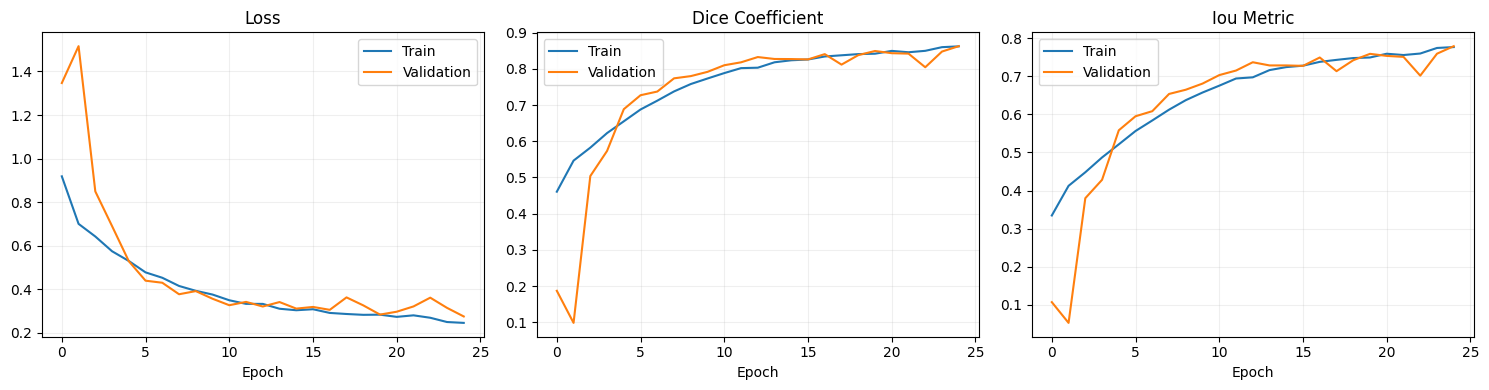

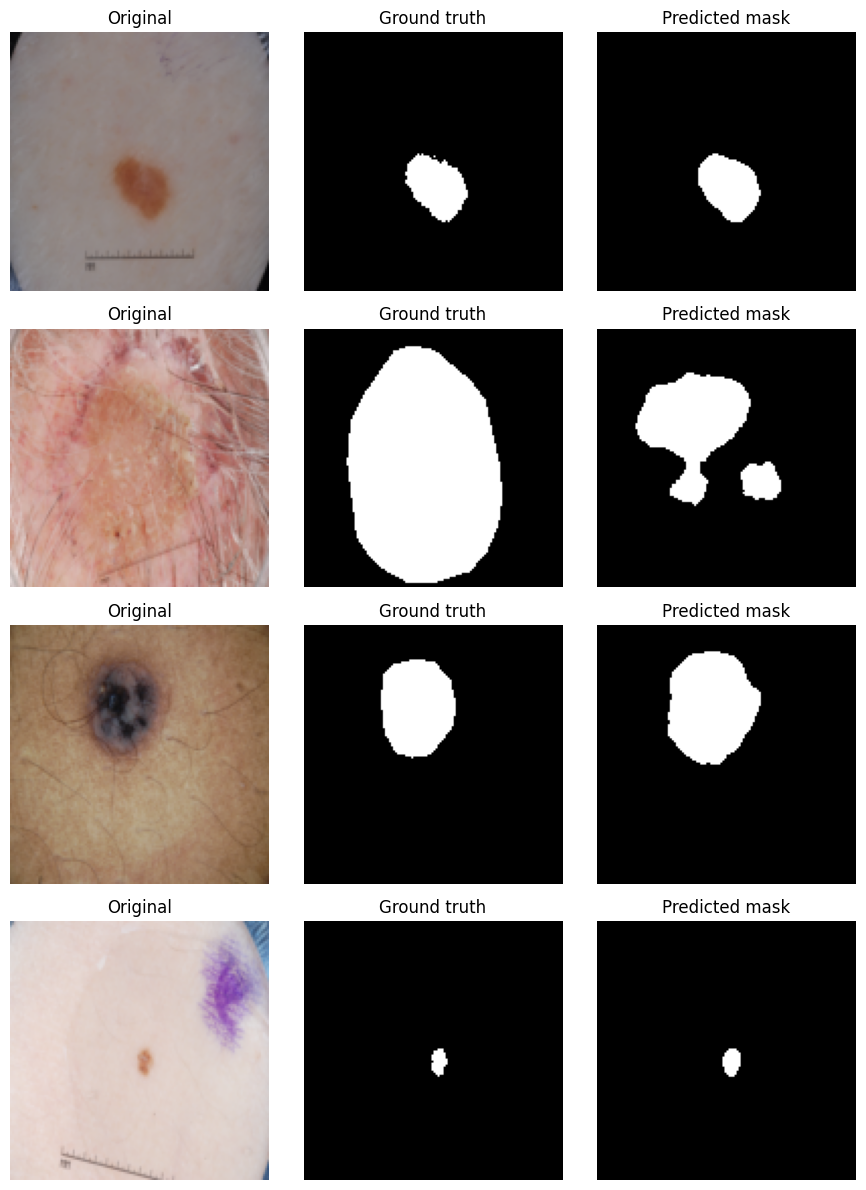


Best checkpoint: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Models/LCTSNet_Inspired_Best.keras
Reports: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Reports
Visualizations: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Visualizations
Next: apply trained model to Derm7pt manifests for predicted masks.


In [ ]:
# STEP 3 CONTINUATION: Run after your existing code through conv_block().
# Requires: tf, np, pd, plt, Path, SIZE, BATCH, EPOCHS, LR,
# train_ds, val_ds, test_ds, MODEL_DIR, REPORT_DIR, VIS_DIR, and conv_block.
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

L = tf.keras.layers
for name in ('train_ds','val_ds','test_ds','conv_block','MODEL_DIR','REPORT_DIR','VIS_DIR','SIZE'):
    if name not in globals():
        raise RuntimeError(f'Missing {name}: run the earlier Step 3 preparation code first.')

MODEL_DIR, REPORT_DIR, VIS_DIR = map(Path, (MODEL_DIR, REPORT_DIR, VIS_DIR))
for p in (MODEL_DIR, REPORT_DIR, VIS_DIR): p.mkdir(parents=True, exist_ok=True)

# No Lambda layers or custom trainable layers: saved model can be loaded with custom_objects.
def build_lcts_inspired(input_size):
    inputs=L.Input((input_size,input_size,3),name='dermoscopic_image')
    s1=conv_block(inputs,24)
    x=L.MaxPooling2D()(s1)
    s2=conv_block(x,48)
    x=L.MaxPooling2D()(s2)
    s3=conv_block(x,96)
    x=L.MaxPooling2D()(s3)
    x=conv_block(x,128)
    # 128x128 -> 16x16 tokens. Attention complexity is manageable on a T4.
    x=L.Reshape((input_size//8 * (input_size//8),128))(x)
    for i in range(2):
        z=L.LayerNormalization(epsilon=1e-6)(x)
        z=L.MultiHeadAttention(num_heads=4,key_dim=32,dropout=0.1,name=f'bottleneck_attention_{i}')(z,z)
        x=L.Add()([x,z])
        z=L.LayerNormalization(epsilon=1e-6)(x)
        z=L.Dense(256,activation='gelu')(z)
        z=L.Dropout(0.1)(z)
        z=L.Dense(128)(z)
        x=L.Add()([x,z])
    x=L.Reshape((input_size//8,input_size//8,128))(x)
    for skip, filters in [(s3,96),(s2,48),(s1,24)]:
        x=L.UpSampling2D(size=2,interpolation='bilinear')(x)
        x=L.Concatenate()([x,skip])
        x=conv_block(x,filters)
    output=L.Conv2D(1,1,activation='sigmoid',name='lesion_probability')(x)
    return tf.keras.Model(inputs,output,name='LCTSNet_Inspired')

@tf.keras.utils.register_keras_serializable(package='Derm7pt')
def dice_coefficient(y_true,y_pred):
    y_true=tf.cast(y_true,tf.float32)
    y_pred=tf.cast(y_pred,tf.float32)
    axes=(1,2,3)
    intersection=tf.reduce_sum(y_true*y_pred,axis=axes)
    denominator=tf.reduce_sum(y_true+y_pred,axis=axes)
    return tf.reduce_mean((2.0*intersection+1e-6)/(denominator+1e-6))

@tf.keras.utils.register_keras_serializable(package='Derm7pt')
def iou_metric(y_true,y_pred):
    y_true=tf.cast(y_true,tf.float32)
    y_pred=tf.cast(y_pred,tf.float32)
    intersection=tf.reduce_sum(y_true*y_pred,axis=(1,2,3))
    union=tf.reduce_sum(y_true+y_pred-y_true*y_pred,axis=(1,2,3))
    return tf.reduce_mean((intersection+1e-6)/(union+1e-6))

@tf.keras.utils.register_keras_serializable(package='Derm7pt')
def segmentation_loss(y_true,y_pred):
    bce=tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true,y_pred))
    return bce + (1.0-dice_coefficient(y_true,y_pred))

if SIZE % 8:
    raise ValueError('SIZE must be divisible by 8')
model=build_lcts_inspired(SIZE)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
              loss=segmentation_loss,metrics=[dice_coefficient,iou_metric])
model.summary()

best_path=MODEL_DIR/'LCTSNet_Inspired_Best.keras'
callbacks=[
    tf.keras.callbacks.ModelCheckpoint(str(best_path),monitor='val_loss',mode='min',save_best_only=True,verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=6,restore_best_weights=True,verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=3,min_lr=1e-6,verbose=1),
    tf.keras.callbacks.CSVLogger(str(REPORT_DIR/'Training_Log.csv')),
]
print('\nStarting LCTS-Net-inspired segmentation training...')
history=model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS,callbacks=callbacks,verbose=1)

# Load best validation checkpoint, not necessarily the final epoch.
model=tf.keras.models.load_model(str(best_path),custom_objects={
    'segmentation_loss':segmentation_loss,'dice_coefficient':dice_coefficient,'iou_metric':iou_metric})
results=model.evaluate(test_ds,verbose=1,return_dict=True)
print('\nHeld-out ISIC test metrics:',results)
with open(REPORT_DIR/'ISIC_Test_Metrics.json','w') as f:
    json.dump({k:float(v) for k,v in results.items()},f,indent=2)

fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['loss','dice_coefficient','iou_metric']):
    ax.plot(history.history[metric],label='Train')
    ax.plot(history.history['val_'+metric],label='Validation')
    ax.set_title(metric.replace('_',' ').title());ax.set_xlabel('Epoch');ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(VIS_DIR/'Training_Curves.png',dpi=160);plt.show();plt.close(fig)

# Example held-out predictions (never use test data for training or model selection).
images,masks=next(iter(test_ds))
predictions=model.predict(images[:4],verbose=0)
fig,axes=plt.subplots(4,3,figsize=(9,12))
for i in range(min(4,len(predictions))):
    axes[i,0].imshow(images[i]);axes[i,0].set_title('Original')
    axes[i,1].imshow(masks[i,:,:,0],cmap='gray',vmin=0,vmax=1);axes[i,1].set_title('Ground truth')
    axes[i,2].imshow(predictions[i,:,:,0]>=0.5,cmap='gray',vmin=0,vmax=1);axes[i,2].set_title('Predicted mask')
for ax in axes.flat:ax.axis('off')
plt.tight_layout();plt.savefig(VIS_DIR/'ISIC_Test_Examples.png',dpi=160);plt.show();plt.close(fig)
print('\nBest checkpoint:',best_path)
print('Reports:',REPORT_DIR)
print('Visualizations:',VIS_DIR)
print('Next: apply trained model to Derm7pt manifests for predicted masks.')


Mounted at /content/drive
Loaded: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Models/LCTSNet_Inspired_Best.keras 
Image size: (128, 128)
Split leakage check: passed
Train: 706/707 predicted masks; report: Derm7pt_Train_Segmentation_Manifest.csv
Validation: 152/152 predicted masks; report: Derm7pt_Validation_Segmentation_Manifest.csv
Test: 152/152 predicted masks; report: Derm7pt_Test_Segmentation_Manifest.csv


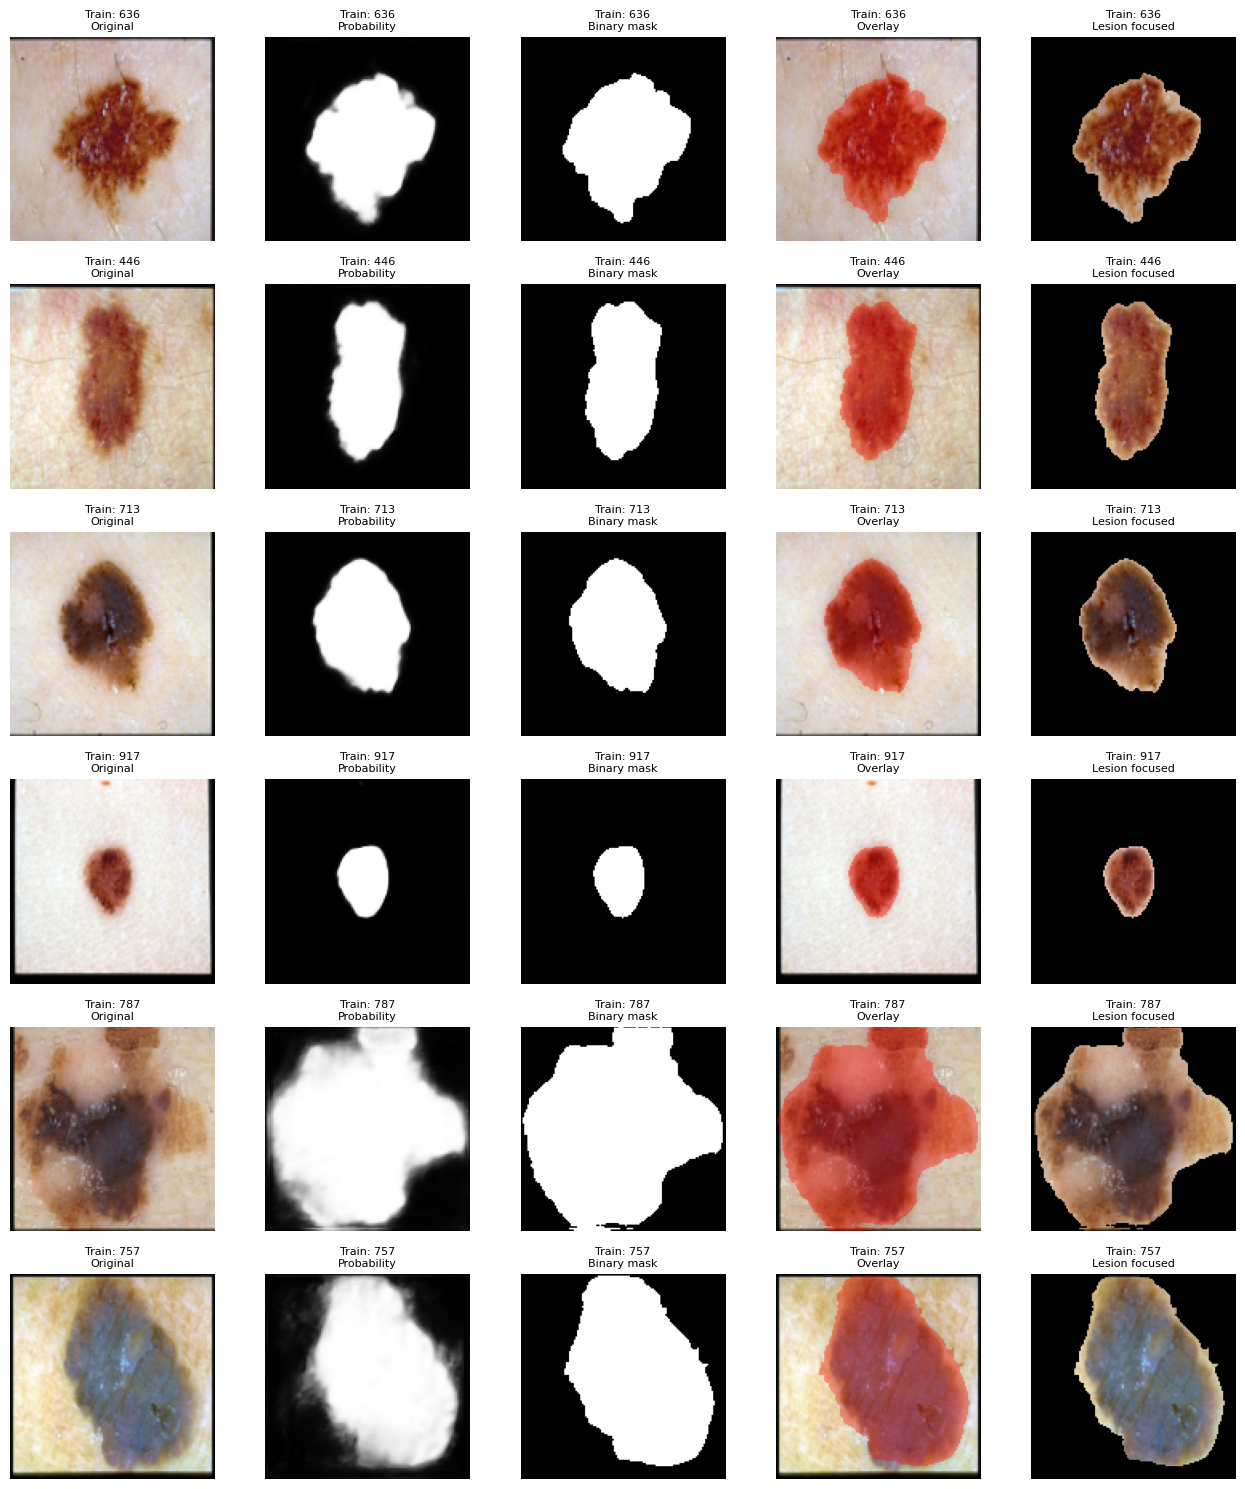

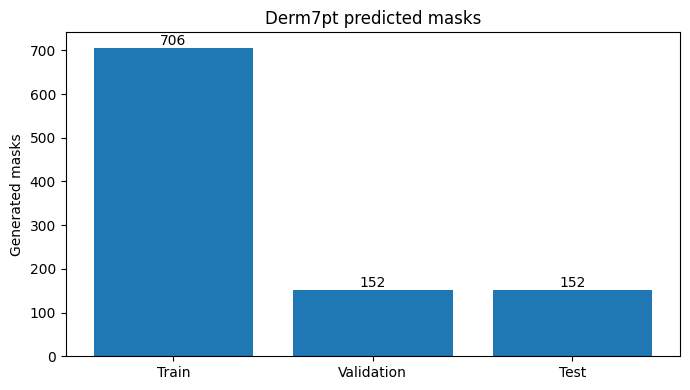


STEP 3B FINISHED: 1010 / 1011
Mask manifest: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Reports/Derm7pt_Mask_Manifest.csv
Focused images: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Lesion_Focused_Images/Dermoscopic
Next: Clinical-image lesion localization and modality-specific image feature extraction.


In [1]:
# ================================================================
# DERM7PT STEP 3B — LCTS-NET-INSPIRED MASK INFERENCE
# Loads Step 3A checkpoint. No training or ground-truth masks needed.
# Predictions are NOT Derm7pt ground truth.
# ================================================================
import os, re, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

SEED=42
THRESHOLD=0.5
BATCH_SIZE=16
MAX_EXAMPLES=6
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Find or mount Google Drive (do not force-remount a populated path).
from google.colab import drive
MYDRIVE = next((p/'MyDrive' for p in (Path('/content/drive'),Path('/content/gdrive'))
                if (p/'MyDrive'/'Derm7pt').is_dir()), None)
if MYDRIVE is None:
    for mount in (Path('/content/drive'),Path('/content/gdrive')):
        mount.mkdir(parents=True,exist_ok=True)
        if not os.path.ismount(str(mount)):
            if any(mount.iterdir()):
                continue
            drive.mount(str(mount), force_remount=False)
        if (mount/'MyDrive'/'Derm7pt').is_dir():
            MYDRIVE=mount/'MyDrive'; break
if MYDRIVE is None:
    raise FileNotFoundError('Cannot locate MyDrive/Derm7pt. Mount Drive or correct project folder.')

BASE=MYDRIVE/'Derm7pt'
PREP=BASE/'Derm7pt_Preprocessed'
ROOT=BASE/'release_v0'
OUT=BASE/'Step3_LCTSNet'
CHECKPOINT=OUT/'Models'/'LCTSNet_Inspired_Best.keras'
MASK_ROOT=OUT/'Predicted_Masks'
FOCUSED_ROOT=OUT/'Lesion_Focused_Images'/'Dermoscopic'
PROB_ROOT=OUT/'Probability_Maps'
REPORT=OUT/'Reports'
VIS=OUT/'Visualizations'
for p in (MASK_ROOT,FOCUSED_ROOT,PROB_ROOT,REPORT,VIS):p.mkdir(parents=True,exist_ok=True)
if not CHECKPOINT.is_file():
    raise FileNotFoundError(f'Missing trained model: {CHECKPOINT}\nRun Step 3A first.')

model=tf.keras.models.load_model(str(CHECKPOINT),compile=False)
shape=model.input_shape
if not isinstance(shape,tuple) or len(shape)!=4 or shape[-1]!=3 or None in shape[1:3]:
    raise ValueError(f'Expected fixed RGB input shape, found: {shape}')
H,W=map(int,shape[1:3])
print('Loaded:',CHECKPOINT,'\nImage size:',(H,W))

# IMPORTANT: these match Step 3A only if training used RGB/255 and bilinear resizing.
def load_rgb(path):
    with Image.open(path) as img:
        img=ImageOps.exif_transpose(img).convert('RGB')
        img=img.resize((W,H),Image.Resampling.BILINEAR)
        return np.asarray(img,dtype=np.float32)/255.

def pick_col(df,possibilities):
    lookup={str(c).casefold():c for c in df.columns}
    return next((lookup[c.casefold()] for c in possibilities if c.casefold() in lookup),None)

def find_image(value,lesion_id):
    raw='' if pd.isna(value) else str(value).strip().replace('\\','/')
    p=Path(raw) if raw else None
    candidates=[]
    if p is not None:
        if p.is_absolute():candidates.append(p)
        else:
            candidates.extend([PREP/p,ROOT/'images'/p,BASE/p])
        candidates.extend([PREP/'Images'/'Dermoscopic'/p.name,
                           PREP/'images'/'dermoscopic'/p.name])
    for suffix in ('.jpg','.jpeg','.png','.JPG','.JPEG','.PNG'):
        candidates.append(PREP/'Images'/'Dermoscopic'/f'{lesion_id}{suffix}')
    return next((c for c in candidates if c.is_file()),None)

def safe_id(x):
    return re.sub(r'[^a-zA-Z0-9_.-]+','_',str(x)).strip('._') or 'unknown'

splits=('Train','Validation','Test')
frames={}; split_ids={}
# Validate every manifest and split BEFORE writing predictions.
for split in splits:
    mf=PREP/f'09_{split}_Image_Manifest.csv'
    if not mf.is_file():raise FileNotFoundError(f'Missing manifest: {mf}')
    df=pd.read_csv(mf,dtype=str,keep_default_na=True)
    id_col=pick_col(df,['Lesion_ID','lesion_id','case_num','Case_ID'])
    image_col=pick_col(df,['Dermoscopic_Image','Dermoscopic_Path','dermoscopic_image','derm','derm_path'])
    if not id_col or not image_col:
        raise ValueError(f'{mf.name} missing ID or dermoscopic path; available: {df.columns.tolist()}')
    if df[id_col].isna().any() or df[id_col].duplicated().any():
        raise ValueError(f'Missing or duplicate lesion IDs: {mf.name}')
    frames[split]=(df,id_col,image_col)
    split_ids[split]=set(df[id_col])
for i,a in enumerate(splits):
    for b in splits[i+1:]:
        common=split_ids[a]&split_ids[b]
        if common:raise ValueError(f'Split leakage between {a} and {b}: {sorted(common)[:8]}')
print('Split leakage check: passed')

summary={}; all_outputs=[]; samples=[]
for split in splits:
    df,id_col,image_col=frames[split]
    dst_mask=MASK_ROOT/split
    dst_prob=PROB_ROOT/split
    dst_focus=FOCUSED_ROOT/split
    for p in (dst_mask,dst_prob,dst_focus):p.mkdir(parents=True,exist_ok=True)
    output=df.copy()
    for c in ('Predicted_Mask_Path','Probability_Map_Path','Lesion_Focused_Image_Path'):
        output[c]=''
    output['Lesion_Area_Fraction']=np.nan
    output['Segmentation_Status']='Not processed'
    pending=[]
    for ix,row in df.iterrows():
        lesion_id=str(row[id_col])
        src=find_image(row[image_col],lesion_id)
        if src is None:output.at[ix,'Segmentation_Status']='Missing dermoscopic image'
        else:pending.append((ix,lesion_id,src))
    succeeded=0
    for start in range(0,len(pending),BATCH_SIZE):
        images=[]; loaded=[]
        for ix,lesion_id,src in pending[start:start+BATCH_SIZE]:
            try:
                images.append(load_rgb(src));loaded.append((ix,lesion_id))
            except Exception as exc:
                output.at[ix,'Segmentation_Status']=f'Image error: {str(exc)[:100]}'
        if not images:continue
        pred=model.predict(np.stack(images),verbose=0)
        if isinstance(pred,(list,tuple)):pred=pred[0]
        if pred.ndim!=4 or pred.shape[1:]!=(H,W,1):
            raise ValueError(f'Model output is {pred.shape}; expected (batch,{H},{W},1)')
        for j,(ix,lesion_id) in enumerate(loaded):
            try:
                prob=np.clip(pred[j,:,:,0].astype(np.float32),0,1)
                mask=(prob>=THRESHOLD).astype(np.uint8)
                name=f'{safe_id(lesion_id)}_{ix:05d}'
                mp=dst_mask/f'{name}_mask.png'
                pp=dst_prob/f'{name}_probability.npy'
                fp=dst_focus/f'{name}_focused.png'
                Image.fromarray(mask*255).save(mp)
                np.save(pp,prob.astype(np.float16))
                focused=(images[j]*mask[:,:,None]*255).round().astype(np.uint8)
                Image.fromarray(focused).save(fp)
                output.at[ix,'Predicted_Mask_Path']=str(mp)
                output.at[ix,'Probability_Map_Path']=str(pp)
                output.at[ix,'Lesion_Focused_Image_Path']=str(fp)
                output.at[ix,'Lesion_Area_Fraction']=float(mask.mean())
                output.at[ix,'Segmentation_Status']='Success'
                succeeded+=1
                if len(samples)<MAX_EXAMPLES:
                    samples.append((split,lesion_id,images[j].copy(),prob.copy(),mask.copy(),focused.copy()))
            except Exception as exc:
                output.at[ix,'Segmentation_Status']=f'Save error: {str(exc)[:100]}'
    path=REPORT/f'Derm7pt_{split}_Segmentation_Manifest.csv'
    output.to_csv(path,index=False)
    all_outputs.append(output.assign(Split=split))
    summary[split]={'manifest_rows':int(len(output)), 'success':int(succeeded),
                    'missing_or_failed':int(len(output)-succeeded), 'manifest':str(path)}
    print(f'{split}: {succeeded}/{len(df)} predicted masks; report: {path.name}')

combined=pd.concat(all_outputs,ignore_index=True)
combined_path=REPORT/'Derm7pt_Mask_Manifest.csv'
combined.to_csv(combined_path,index=False)
report={'checkpoint':str(CHECKPOINT),'size':[H,W],'threshold':THRESHOLD,
        'splits':summary,'total_success':int(sum(x['success'] for x in summary.values())),
        'total_rows':int(len(combined)),
        'note':'Derm7pt masks are predictions; no Derm7pt segmentation accuracy is claimed.'}
with open(REPORT/'Derm7pt_Segmentation_Summary.json','w') as f:json.dump(report,f,indent=2)

if samples:
    fig,axes=plt.subplots(len(samples),5,figsize=(13,2.5*len(samples)),squeeze=False)
    for i,(split,lesion_id,img,prob,mask,focused) in enumerate(samples):
        overlay=img.copy();overlay[mask>0]=0.65*overlay[mask>0]+0.35*np.array([1,0,0])
        for j,(title,shown) in enumerate(zip(('Original','Probability','Binary mask','Overlay','Lesion focused'),
                                              (img,prob,mask,overlay,focused))):
            axes[i,j].imshow(shown,cmap='gray' if j in (1,2) else None,
                             vmin=0 if j in (1,2) else None,vmax=1 if j in (1,2) else None)
            axes[i,j].set_title(f'{split}: {lesion_id}\n{title}',fontsize=8)
            axes[i,j].axis('off')
    fig.tight_layout();fig.savefig(VIS/'Derm7pt_Segmentation_Examples.png',dpi=150);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(7,4))
counts=[summary[s]['success'] for s in splits]
ax.bar(splits,counts);ax.set_ylabel('Generated masks');ax.set_title('Derm7pt predicted masks')
for i,n in enumerate(counts):ax.text(i,n,str(n),ha='center',va='bottom')
fig.tight_layout();fig.savefig(VIS/'Derm7pt_Mask_Counts.png',dpi=150);plt.show();plt.close(fig)
print('\nSTEP 3B FINISHED:',report['total_success'],'/',report['total_rows'])
print('Mask manifest:',combined_path)
print('Focused images:',FOCUSED_ROOT)
print('Next: Clinical-image lesion localization and modality-specific image feature extraction.')


Loading existing LCTS-Net model...
Loaded model input size: (128, 128)
Train: selected 9 of 9 requested images
Validation: selected 3 of 3 requested images
Test: selected 3 of 3 requested images

Input batch shape: (15, 128, 128, 3)

Predicting clinical lesion masks...
Predicted mask shape: (15, 128, 128)


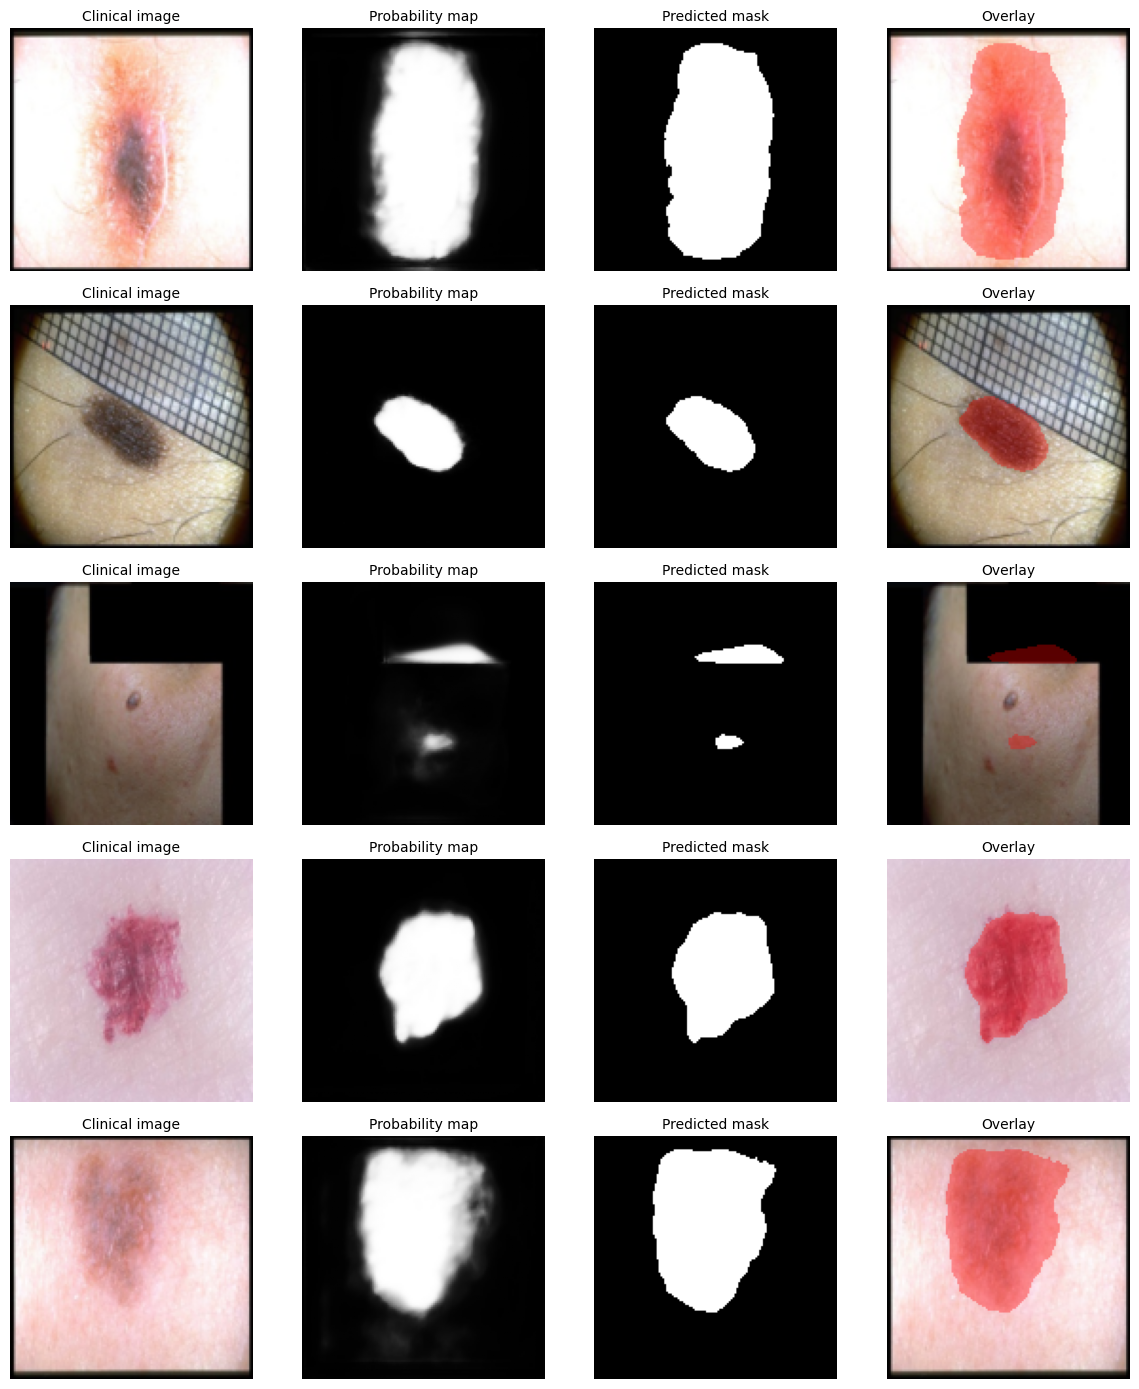


STEP 3C QUICK TEST FINISHED
Processed: 15 clinical images
Masks: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3C_Clinical_QuickTest/Masks
Focused images: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3C_Clinical_QuickTest/Focused_Images
CSV: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3C_Clinical_QuickTest/Reports/Clinical_QuickTest_Manifest.csv
Visualization: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3C_Clinical_QuickTest/Visualizations/Clinical_Segmentation_QuickTest.png

IMPORTANT:
Masks are predictions from a dermoscopy-trained model.
Clinical segmentation accuracy has not been validated.
NEXT: Inspect outputs before feature extraction.


In [2]:

# ============================================================
# STEP 3C — FAST DERM7PT CLINICAL IMAGE SEGMENTATION
# ONLY 15 IMAGES: TRAIN=9, VALIDATION=3, TEST=3
# Uses existing LCTS-Net checkpoint — NO TRAINING
# ============================================================

import os, re, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

SEED = 42
THRESHOLD = 0.5
SAMPLES = {"Train": 9, "Validation": 3, "Test": 3}

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# 1. GOOGLE DRIVE
# ------------------------------------------------------------
from google.colab import drive

MYDRIVE = None

for root in [Path("/content/drive"), Path("/content/gdrive")]:
    candidate = root / "MyDrive"
    if (candidate / "Derm7pt").is_dir():
        MYDRIVE = candidate
        break

if MYDRIVE is None:
    for root in [Path("/content/drive"), Path("/content/gdrive")]:
        root.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(root)):
            if any(root.iterdir()):
                continue
            drive.mount(str(root), force_remount=False)
        if (root / "MyDrive" / "Derm7pt").is_dir():
            MYDRIVE = root / "MyDrive"
            break

if MYDRIVE is None:
    raise FileNotFoundError("Cannot locate MyDrive/Derm7pt")

# ------------------------------------------------------------
# 2. FOLDERS
# ------------------------------------------------------------
BASE = MYDRIVE / "Derm7pt"
PREP = BASE / "Derm7pt_Preprocessed"
STEP3 = BASE / "Step3_LCTSNet"

MODEL_PATH = STEP3 / "Models/LCTSNet_Inspired_Best.keras"

OUT = STEP3 / "Step3C_Clinical_QuickTest"
MASK_DIR = OUT / "Masks"
FOCUSED_DIR = OUT / "Focused_Images"
REPORT_DIR = OUT / "Reports"
VIS_DIR = OUT / "Visualizations"

for folder in [MASK_DIR, FOCUSED_DIR, REPORT_DIR, VIS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Trained model not found: {MODEL_PATH}"
    )

# ------------------------------------------------------------
# 3. LOAD PRETRAINED MODEL
# ------------------------------------------------------------
print("Loading existing LCTS-Net model...")

model = tf.keras.models.load_model(
    str(MODEL_PATH),
    compile=False
)

if isinstance(model.input_shape, list):
    raise ValueError("Expected a single RGB image input.")

H, W = model.input_shape[1:3]

if H is None or W is None:
    raise ValueError("Model input size must be fixed.")

H, W = int(H), int(W)
print("Loaded model input size:", (H, W))

# ------------------------------------------------------------
# 4. HELPER FUNCTIONS
# ------------------------------------------------------------
def find_column(df, choices):
    lookup = {str(c).lower(): c for c in df.columns}
    for name in choices:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

def safe_name(value):
    return re.sub(
        r"[^A-Za-z0-9_.-]", "_", str(value)
    ).strip("._") or "unknown"

def resolve_clinical_path(value, lesion_id):
    candidates = []

    if pd.notna(value) and str(value).strip():
        raw = str(value).strip().replace("\\", "/")
        p = Path(raw)

        if p.is_absolute():
            candidates.append(p)

        candidates.extend([
            PREP / raw,
            PREP / "Images/Clinical" / p.name,
            PREP / "images/clinical" / p.name,
            BASE / "release_v0/images" / raw,
        ])

    for suffix in [".jpg", ".jpeg", ".png",
                   ".JPG", ".JPEG", ".PNG"]:
        candidates.append(
            PREP / "Images/Clinical" / f"{lesion_id}{suffix}"
        )

    for p in candidates:
        if p.is_file():
            return p

    return None

def load_rgb(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize((W, H), Image.Resampling.BILINEAR)
        return np.asarray(im, dtype=np.float32) / 255.0

# ------------------------------------------------------------
# 5. CHOOSE SMALL REPRESENTATIVE SUBSET
# ------------------------------------------------------------
records = []
selection_summary = {}

for split, required_count in SAMPLES.items():

    manifest = PREP / f"09_{split}_Image_Manifest.csv"

    if not manifest.is_file():
        raise FileNotFoundError(
            f"Missing manifest: {manifest}"
        )

    df = pd.read_csv(manifest, dtype=str)

    id_col = find_column(
        df, ["Lesion_ID", "lesion_id", "case_num"]
    )

    clinical_col = find_column(
        df, [
            "Clinical_Image",
            "Clinical_Path",
            "clinical_image",
            "clinic",
            "clinic_path",
        ]
    )

    if id_col is None or clinical_col is None:
        raise ValueError(
            f"Missing ID or clinical column in {manifest.name}. "
            f"Available columns: {df.columns.tolist()}"
        )

    valid = []

    for _, row in df.iterrows():

        lesion_id = str(row[id_col])
        image_path = resolve_clinical_path(
            row[clinical_col], lesion_id
        )

        if image_path is not None:
            valid.append((lesion_id, image_path))

    # Reproducible sampling, no replacement
    rng = random.Random(SEED + list(SAMPLES).index(split))
    rng.shuffle(valid)

    selected = valid[:required_count]

    selection_summary[split] = len(selected)

    print(
        f"{split}: selected {len(selected)} "
        f"of {required_count} requested images"
    )

    for lesion_id, path in selected:
        records.append({
            "Split": split,
            "Lesion_ID": lesion_id,
            "Clinical_Image_Path": str(path)
        })

if not records:
    raise RuntimeError(
        "No valid clinical images were found. "
        "Check manifest paths and Images/Clinical."
    )

# ------------------------------------------------------------
# 6. LOAD IMAGES
# ------------------------------------------------------------
images = []
loaded_records = []

for record in records:
    try:
        images.append(load_rgb(record["Clinical_Image_Path"]))
        loaded_records.append(record)
    except Exception as exc:
        print("Skipped:", record["Lesion_ID"], str(exc)[:100])

if not images:
    raise RuntimeError("No clinical images could be opened.")

X = np.stack(images, axis=0)

print("\nInput batch shape:", X.shape)

# ------------------------------------------------------------
# 7. FAST SINGLE-BATCH PREDICTION
# ------------------------------------------------------------
print("\nPredicting clinical lesion masks...")

predictions = model.predict(
    X,
    batch_size=min(16, len(X)),
    verbose=0
)

if isinstance(predictions, (tuple, list)):
    predictions = predictions[0]

if predictions.shape != (len(X), H, W, 1):
    raise ValueError(
        f"Unexpected segmentation output: {predictions.shape}"
    )

probabilities = np.clip(predictions[..., 0], 0, 1)
binary_masks = probabilities >= THRESHOLD

print("Predicted mask shape:", binary_masks.shape)

# ------------------------------------------------------------
# 8. SAVE MASKS AND FOCUSED IMAGES
# ------------------------------------------------------------
output_rows = []

for i, record in enumerate(loaded_records):

    split = record["Split"]
    lesion_id = record["Lesion_ID"]

    mask = binary_masks[i].astype(np.uint8) * 255

    focused = (
        X[i] * binary_masks[i][..., None]
    )

    focused = (
        np.clip(focused, 0, 1) * 255
    ).astype(np.uint8)

    (MASK_DIR / split).mkdir(parents=True, exist_ok=True)
    (FOCUSED_DIR / split).mkdir(parents=True, exist_ok=True)

    name = f"{safe_name(lesion_id)}_{i:03d}"

    mask_path = MASK_DIR / split / f"{name}_mask.png"
    focus_path = FOCUSED_DIR / split / f"{name}_focused.png"

    Image.fromarray(mask).save(mask_path)
    Image.fromarray(focused).save(focus_path)

    output_rows.append({
        "Split": split,
        "Lesion_ID": lesion_id,
        "Clinical_Image_Path": record["Clinical_Image_Path"],
        "Predicted_Clinical_Mask_Path": str(mask_path),
        "Focused_Clinical_Image_Path": str(focus_path),
        "Lesion_Area_Fraction": float(binary_masks[i].mean()),
        "Mask_Status": "Predicted_Unvalidated"
    })

result_df = pd.DataFrame(output_rows)

csv_path = REPORT_DIR / "Clinical_QuickTest_Manifest.csv"
result_df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 9. VISUALIZATION — ONLY FIRST FIVE SAMPLES
# ------------------------------------------------------------
n_vis = min(5, len(X))

fig, axes = plt.subplots(
    n_vis, 4,
    figsize=(12, 2.8 * n_vis),
    squeeze=False
)

for i in range(n_vis):

    img = X[i]
    prob = probabilities[i]
    mask = binary_masks[i]

    focused = img * mask[..., None]

    overlay = img.copy()
    red = np.zeros_like(img)
    red[..., 0] = 1.0
    overlay = np.where(
        mask[..., None],
        img * 0.65 + red * 0.35,
        img
    )

    axes[i, 0].imshow(img)
    axes[i, 1].imshow(prob, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(mask, cmap="gray")
    axes[i, 3].imshow(overlay)

    labels = [
        "Clinical image",
        "Probability map",
        "Predicted mask",
        "Overlay"
    ]

    for j, label in enumerate(labels):
        axes[i, j].set_title(label, fontsize=10)
        axes[i, j].axis("off")

plt.tight_layout()

vis_path = VIS_DIR / "Clinical_Segmentation_QuickTest.png"
plt.savefig(vis_path, dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. SUMMARY
# ------------------------------------------------------------
summary = {
    "model": str(MODEL_PATH),
    "requested_samples": SAMPLES,
    "selected_samples": selection_summary,
    "processed_samples": int(len(result_df)),
    "input_shape": [H, W, 3],
    "threshold": THRESHOLD,
    "status": "Exploratory clinical transfer inference",
    "validated": False
}

summary_path = REPORT_DIR / "Clinical_QuickTest_Summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 60)
print("STEP 3C QUICK TEST FINISHED")
print("=" * 60)

print("Processed:", len(result_df), "clinical images")
print("Masks:", MASK_DIR)
print("Focused images:", FOCUSED_DIR)
print("CSV:", csv_path)
print("Visualization:", vis_path)

print("\nIMPORTANT:")
print("Masks are predictions from a dermoscopy-trained model.")
print("Clinical segmentation accuracy has not been validated.")
print("NEXT: Inspect outputs before feature extraction.")


Clinical records: 15
Matching image pairs: 15

Prepared samples: 15
Split
Train         9
Validation    3
Test          3


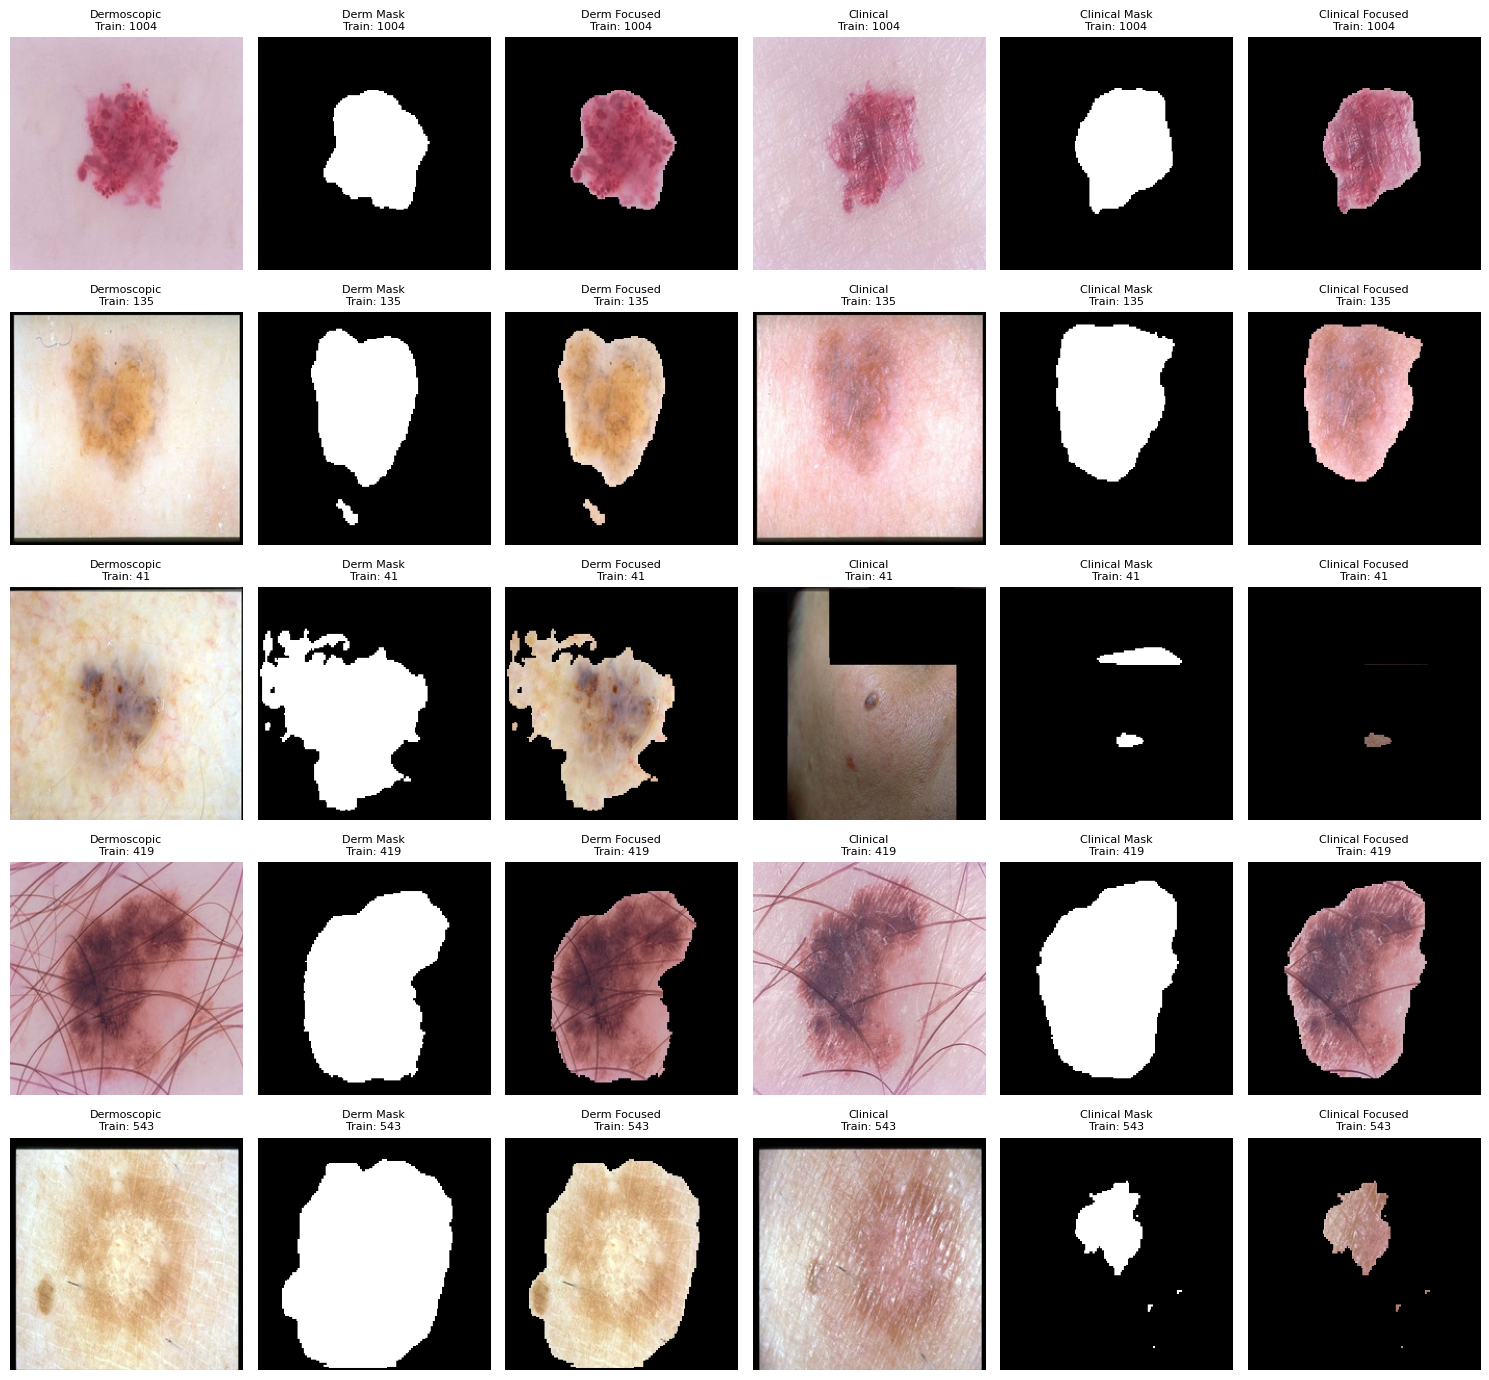


STEP 3D QUICK TEST COMPLETED
Prepared pairs: 15
Dermoscopic images: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3D_Lesion_Focused_QuickTest/Dermoscopic
Clinical images: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3D_Lesion_Focused_QuickTest/Clinical
Manifest: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3D_Lesion_Focused_QuickTest/Reports/Step3D_Aligned_Image_Manifest.csv
Visualization: /content/drive/MyDrive/Derm7pt/Step3_LCTSNet/Step3D_Lesion_Focused_QuickTest/Visualizations/Step3D_Aligned_Examples.png

NEXT: Step 4 — Modality-Specific Feature Extraction


In [3]:

# ================================================================
# STEP 3D — DERM7PT FAST LESION-FOCUSED IMAGE PREPARATION
#
# INPUTS:
# Step 3B: Dermoscopic segmentation manifest + masks
# Step 3C: Clinical quick-test manifest + masks
#
# OUTPUT:
# 15 or fewer paired lesion-focused images
# Combined alignment manifest
# Comparison visualizations
# Summary report
#
# No model training. No feature extraction in this step.
# ================================================================

import os, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

SEED = 42
IMAGE_SIZE = 224
MAX_SAMPLES = 15
VIS_SAMPLES = 5

# ------------------------------------------------
# 1. LOCATE GOOGLE DRIVE
# ------------------------------------------------
from google.colab import drive

MYDRIVE = None

for mount in [Path("/content/drive"), Path("/content/gdrive")]:
    candidate = mount / "MyDrive"
    if (candidate / "Derm7pt").is_dir():
        MYDRIVE = candidate
        break

if MYDRIVE is None:
    for mount in [Path("/content/drive"), Path("/content/gdrive")]:
        mount.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(mount)):
            if any(mount.iterdir()):
                continue
            drive.mount(str(mount), force_remount=False)
        candidate = mount / "MyDrive"
        if (candidate / "Derm7pt").is_dir():
            MYDRIVE = candidate
            break

if MYDRIVE is None:
    raise FileNotFoundError("MyDrive/Derm7pt not found")

BASE = MYDRIVE / "Derm7pt"
SEG = BASE / "Step3_LCTSNet"

DERM_CSV = SEG / "Reports/Derm7pt_Mask_Manifest.csv"
CLIN_CSV = (
    SEG /
    "Step3C_Clinical_QuickTest/Reports/"
    "Clinical_QuickTest_Manifest.csv"
)

OUT = SEG / "Step3D_Lesion_Focused_QuickTest"
DERM_OUT = OUT / "Dermoscopic"
CLIN_OUT = OUT / "Clinical"
REPORT_OUT = OUT / "Reports"
VIS_OUT = OUT / "Visualizations"

for p in [DERM_OUT, CLIN_OUT, REPORT_OUT, VIS_OUT]:
    p.mkdir(parents=True, exist_ok=True)

for f in [DERM_CSV, CLIN_CSV]:
    if not f.is_file():
        raise FileNotFoundError(
            f"Required Step 3 output missing:\n{f}"
        )

# ------------------------------------------------
# 2. LOAD PREVIOUS STEP RESULTS
# ------------------------------------------------
derm_df = pd.read_csv(DERM_CSV, dtype=str)
clin_df = pd.read_csv(CLIN_CSV, dtype=str)

def find_col(df, options):
    lookup = {str(c).lower(): c for c in df.columns}
    for name in options:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

derm_id_col = find_col(derm_df, ["Lesion_ID", "case_num"])
derm_split_col = find_col(derm_df, ["Split"])
derm_img_col = find_col(
    derm_df, ["Dermoscopic_Image", "Dermoscopic_Path", "derm"]
)
derm_mask_col = find_col(
    derm_df, ["Predicted_Mask_Path"]
)

required_derm = [
    derm_id_col, derm_split_col, derm_img_col, derm_mask_col
]

required_clin = [
    "Lesion_ID", "Split", "Clinical_Image_Path",
    "Predicted_Clinical_Mask_Path"
]

if any(x is None for x in required_derm):
    raise ValueError(
        "Dermoscopic manifest missing required columns. "
        f"Available: {derm_df.columns.tolist()}"
    )

missing = [c for c in required_clin if c not in clin_df.columns]
if missing:
    raise ValueError(
        f"Clinical quick-test manifest missing: {missing}"
    )

# ------------------------------------------------
# 3. STANDARDIZE ALIGNMENT KEYS
# ------------------------------------------------
derm = pd.DataFrame({
    "Lesion_ID": derm_df[derm_id_col],
    "Split": derm_df[derm_split_col],
    "Dermoscopic_Image": derm_df[derm_img_col],
    "Dermoscopic_Mask": derm_df[derm_mask_col]
})

clin = clin_df[required_clin].copy()

for frame in [derm, clin]:
    frame["Lesion_ID"] = (
        frame["Lesion_ID"].astype(str).str.strip()
    )
    frame["Split"] = (
        frame["Split"].astype(str).str.strip().str.title()
    )

for name, frame in [("dermoscopic", derm), ("clinical", clin)]:
    if frame.duplicated(["Split", "Lesion_ID"]).any():
        raise ValueError(
            f"Duplicate Split/Lesion_ID in {name} manifest"
        )

paired = pd.merge(
    clin,
    derm,
    on=["Lesion_ID", "Split"],
    how="inner",
    validate="one_to_one"
)

split_order = {"Train": 0, "Validation": 1, "Test": 2}

paired["_order"] = paired["Split"].map(split_order)
paired = paired.sort_values(
    ["_order", "Lesion_ID"]
).drop(columns="_order").head(MAX_SAMPLES)

print("Clinical records:", len(clin))
print("Matching image pairs:", len(paired))

if paired.empty:
    raise RuntimeError(
        "No matching Lesion_ID + Split pairs found. "
        "Inspect the Step 3B and Step 3C CSV files."
    )

# ------------------------------------------------
# 4. RESOLVE INPUT IMAGE PATHS
# ------------------------------------------------
PREP = BASE / "Derm7pt_Preprocessed"

def resolve_path(value, mode="generic", lesion_id=None):
    if pd.isna(value) or not str(value).strip():
        return None

    raw = str(value).strip().replace("\\", "/")
    p = Path(raw)

    candidates = [p] if p.is_absolute() else []

    candidates.extend([
        PREP / raw,
        SEG / raw,
        BASE / raw,
        PREP / "Images" / (
            "Dermoscopic" if mode == "derm" else "Clinical"
        ) / p.name,
        BASE / "release_v0" / "images" / raw
    ])

    if lesion_id is not None and mode in ("derm", "clinical"):
        folder = PREP / "Images" / (
            "Dermoscopic" if mode == "derm" else "Clinical"
        )
        for ext in [".jpg", ".jpeg", ".png",
                    ".JPG", ".JPEG", ".PNG"]:
            candidates.append(folder / f"{lesion_id}{ext}")

    return next((c for c in candidates if c.is_file()), None)

def load_image(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im = im.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )
        return np.asarray(im, dtype=np.uint8)

def load_mask(path):
    with Image.open(path) as im:
        im = im.convert("L")
        im = im.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.NEAREST
        )
        return np.asarray(im) >= 128

def make_focused(img, mask):
    result = img.copy()
    result[~mask] = 0
    return result

def safe_id(value):
    return re.sub(
        r"[^a-zA-Z0-9_.-]+", "_", str(value)
    ).strip("._") or "unknown"

# ------------------------------------------------
# 5. CREATE ALIGNED IMAGES
# ------------------------------------------------
rows = []
examples = []

for _, rec in paired.iterrows():
    split = rec["Split"]
    lesion = rec["Lesion_ID"]

    derm_path = resolve_path(
        rec["Dermoscopic_Image"], "derm", lesion
    )
    clin_path = resolve_path(
        rec["Clinical_Image_Path"], "clinical", lesion
    )
    dmask_path = resolve_path(rec["Dermoscopic_Mask"])
    cmask_path = resolve_path(
        rec["Predicted_Clinical_Mask_Path"]
    )

    paths = [derm_path, clin_path, dmask_path, cmask_path]

    if any(p is None for p in paths):
        print("Skipping incomplete pair:", lesion, split)
        continue

    try:
        dimg = load_image(derm_path)
        cimg = load_image(clin_path)

        dmask = load_mask(dmask_path)
        cmask = load_mask(cmask_path)

        dfocused = make_focused(dimg, dmask)
        cfocused = make_focused(cimg, cmask)

        (DERM_OUT / split).mkdir(parents=True, exist_ok=True)
        (CLIN_OUT / split).mkdir(parents=True, exist_ok=True)

        stem = safe_id(lesion)

        derm_file = DERM_OUT / split / f"{stem}_focused.png"
        clin_file = CLIN_OUT / split / f"{stem}_focused.png"

        Image.fromarray(dfocused).save(derm_file)
        Image.fromarray(cfocused).save(clin_file)

        rows.append({
            "Split": split,
            "Lesion_ID": lesion,
            "Original_Dermoscopic_Image": str(derm_path),
            "Original_Clinical_Image": str(clin_path),
            "Dermoscopic_Mask": str(dmask_path),
            "Clinical_Mask": str(cmask_path),
            "Focused_Dermoscopic_Image": str(derm_file),
            "Focused_Clinical_Image": str(clin_file),
            "Dermoscopic_Area_Fraction": float(dmask.mean()),
            "Clinical_Area_Fraction": float(cmask.mean()),
            "Clinical_Mask_Validated": False,
            "Status": "Prepared"
        })

        if len(examples) < VIS_SAMPLES:
            examples.append((
                lesion, split, dimg, dmask,
                dfocused, cimg, cmask, cfocused
            ))

    except Exception as e:
        print("Error:", lesion, str(e)[:150])

if not rows:
    raise RuntimeError(
        "No complete lesion-focused image pairs were generated."
    )

# ------------------------------------------------
# 6. SAVE MANIFEST
# ------------------------------------------------
result = pd.DataFrame(rows)

manifest_path = (
    REPORT_OUT / "Step3D_Aligned_Image_Manifest.csv"
)

result.to_csv(manifest_path, index=False)

print("\nPrepared samples:", len(result))
print(result["Split"].value_counts().to_string())

# ------------------------------------------------
# 7. QUICK VISUALIZATION
# ------------------------------------------------
fig, axes = plt.subplots(
    len(examples), 6,
    figsize=(15, 2.8 * len(examples)),
    squeeze=False
)

titles = [
    "Dermoscopic",
    "Derm Mask",
    "Derm Focused",
    "Clinical",
    "Clinical Mask",
    "Clinical Focused"
]

for i, item in enumerate(examples):
    lesion, split, dimg, dmask, dfocused, cimg, cmask, cfocused = item
    pictures = [dimg, dmask, dfocused, cimg, cmask, cfocused]

    for j, pic in enumerate(pictures):
        if j in (1, 4):
            axes[i, j].imshow(pic, cmap="gray", vmin=0, vmax=1)
        else:
            axes[i, j].imshow(pic)

        axes[i, j].set_title(
            f"{titles[j]}\n{split}: {lesion}",
            fontsize=8
        )
        axes[i, j].axis("off")

plt.tight_layout()

vis_path = VIS_OUT / "Step3D_Aligned_Examples.png"
plt.savefig(vis_path, dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 8. SAVE SUMMARY
# ------------------------------------------------
summary = {
    "requested_maximum": MAX_SAMPLES,
    "matched_candidates": int(len(paired)),
    "successfully_prepared": int(len(result)),
    "split_counts": result["Split"].value_counts().to_dict(),
    "image_size": IMAGE_SIZE,
    "clinical_mask_validation": "Not validated",
    "manifest": str(manifest_path),
    "note": (
        "This quick test uses only a subset. "
        "It is not the complete Derm7pt training dataset. "
        "Clinical masks are experimental transfer predictions."
    )
}

summary_path = REPORT_OUT / "Step3D_Summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 60)
print("STEP 3D QUICK TEST COMPLETED")
print("=" * 60)
print("Prepared pairs:", len(result))
print("Dermoscopic images:", DERM_OUT)
print("Clinical images:", CLIN_OUT)
print("Manifest:", manifest_path)
print("Visualization:", vis_path)
print("\nNEXT: Step 4 — Modality-Specific Feature Extraction")


Device: cuda
Project: /content/drive/MyDrive/Derm7pt
Outputs: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step4_Full_Modality_Features
Train: total=707, derm=706, clinical=707
Validation: total=152, derm=152, clinical=152
Test: total=152, derm=152, clinical=152
Loading ImageNet pretrained: vit_tiny_patch16_224


Train derm: vit_tiny_patch16_224:   0%|          | 0/89 [00:00<?, ?it/s]

Loading ImageNet pretrained: swin_tiny_patch4_window7_224


Train derm: swin_tiny_patch4_window7_224:   0%|          | 0/89 [00:00<?, ?it/s]

Train ViT_Swin_Dermoscopic: (706, 960)
Loading ImageNet pretrained: convnext_tiny


...

Test ViT_Swin_Dermoscopic: (152, 960)
Loading ImageNet pretrained: convnext_tiny


Test clinical: convnext_tiny:   0%|          | 0/19 [00:00<?, ?it/s]

Loading ImageNet pretrained: vit_tiny_patch16_224


Test clinical: vit_tiny_patch16_224:   0%|          | 0/19 [00:00<?, ?it/s]

Test ConvNeXt_ViT_Clinical: (152, 960)
Train metadata: 707/707 matched; dim=64
Validation metadata: 152/152 matched; dim=64
Test metadata: 152/152 matched; dim=64


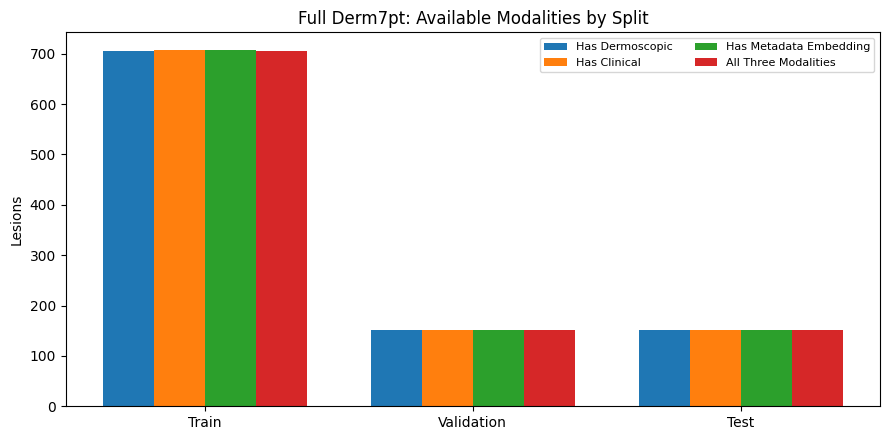


STEP 4: FULL-DATASET FEATURE EXTRACTION FINISHED
Manifest records: 1011
Complete three-modality records: 1010
Feature files: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step4_Full_Modality_Features
Audit: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step4_Full_Modality_Features/Reports/Step4_Multimodal_Availability_Audit.csv
Summary: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step4_Full_Modality_Features/Reports/Step4_Full_Feature_Extraction_Summary.json
NEXT: Train three 256-D projections on TRAIN only and fuse 768-D for HH-SNN.


In [11]:
# ================================================================
# DERM7PT — STEP 4: FULL-DATASET MODALITY-SPECIFIC FEATURES
# Dermoscopic: pretrained ViT + Swin backbones (concatenation)
# Clinical: pretrained ConvNeXt + ViT backbones (concatenation)
# Metadata: align existing FT-Transformer embeddings by Lesion_ID
#
# IMPORTANT
# - Processes ALL available lesion records in ORIGINAL split manifests.
# - Does not use the old 15-image Step3D subset.
# - ImageNet-pretrained feature extractors are FROZEN, not trained
#   end-to-end or exact custom paper-defined hybrid encoders.
# - Does not train a classifier or learn 256-dimensional projections.
# - Uses original images by default. Lesion-focused images are used
#   only where valid full-dataset segmentation manifests exist.
# - Missing modalities remain explicitly flagged, NOT silently dropped.
# - Segmentation masks generated using ISIC dermoscopy may not be
#   valid for clinical photos; no clinical masks assumed here.
# ================================================================

# In Colab, run once if needed:
# %pip -q install -U timm pillow pandas numpy matplotlib tqdm

import os, json, re, gc, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageFile
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
import timm

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 8            # set 4 or 2 if GPU memory is low
NUM_WORKERS = 2          # use 0 if Colab/DataLoader errors occur
USE_AMP = True
USE_LESION_FOCUSED_DERMOSCOPY = True
USE_LESION_FOCUSED_CLINICAL = False  # enable ONLY with validated full clinical masks
OVERWRITE_EXISTING_FEATURES = False
EXPORT_PER_SPLIT_CSV = True
SPLITS = ("Train", "Validation", "Test")

# These are independently pretrained architectures paired at feature level:
DERM_MODELS = ("vit_tiny_patch16_224", "swin_tiny_patch4_window7_224")
CLIN_MODELS = ("convnext_tiny", "vit_tiny_patch16_224")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True
print('Device:', device)

# --------------------- Resolve Google Drive ---------------------
from google.colab import drive
mydrive = None
for mount in (Path('/content/drive'), Path('/content/gdrive')):
    root = mount / 'MyDrive'
    if (root / 'Derm7pt').is_dir():
        mydrive = root
        break
if mydrive is None:
    for mount in (Path('/content/drive'), Path('/content/gdrive')):
        mount.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(mount)):
            if any(mount.iterdir()):
                continue
            drive.mount(str(mount), force_remount=False)
        root = mount / 'MyDrive'
        if (root / 'Derm7pt').is_dir():
            mydrive = root
            break
if mydrive is None:
    raise FileNotFoundError('Google Drive/Derm7pt not found. Mount Drive or correct the project path.')

BASE = mydrive / 'Derm7pt'
ROOT = BASE / 'release_v0'
PREP = BASE / 'Derm7pt_Preprocessed'
SEG = BASE / 'Step3_LCTSNet'
OUT = PREP / 'Step4_Full_Modality_Features'
RAW = OUT / 'Raw_Features'
REPORT = OUT / 'Reports'
VIS = OUT / 'Visualizations'
for p in (OUT, RAW, REPORT, VIS):
    p.mkdir(parents=True, exist_ok=True)

print('Project:', BASE)
print('Outputs:', OUT)

# --------------------- Utilities ---------------------
def find_col(df, candidates):
    lookup = {str(c).casefold(): c for c in df.columns}
    for c in candidates:
        if c.casefold() in lookup:
            return lookup[c.casefold()]
    return None

def clean_id(s):
    if pd.isna(s):
        return ''
    v = str(s).strip()
    # Repair float-rendered integer identifiers only.
    return v[:-2] if re.fullmatch(r'\d+\.0', v) else v

def candidate_path(raw, modality, lesion_id):
    if raw is None or pd.isna(raw):
        raw = ''
    raw = str(raw).strip().replace('\\', '/')
    modality_folder = 'Dermoscopic' if modality == 'derm' else 'Clinical'
    paths = []
    if raw:
        p = Path(raw)
        if p.is_absolute():
            paths.append(p)
        else:
            paths.extend((PREP / p, PREP / 'Images' / modality_folder / p.name,
                          PREP / 'images' / modality_folder.lower() / p.name,
                          ROOT / 'images' / p, ROOT / 'images' / p.name))
    for ext in ('.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG'):
        paths.append(PREP / 'Images' / modality_folder / f'{lesion_id}{ext}')
    return next((p for p in paths if p.is_file()), None)

def resolve_saved_path(v):
    if pd.isna(v) or not str(v).strip():
        return None
    raw = Path(str(v).strip().replace('\\','/'))
    options = [raw] if raw.is_absolute() else [BASE / raw, PREP / raw, SEG / raw]
    return next((p for p in options if p.is_file()), None)

# --------------------- Original split manifests ---------------------
all_manifest = []
for split in SPLITS:
    file = PREP / f'09_{split}_Image_Manifest.csv'
    if not file.is_file():
        raise FileNotFoundError(f'Original split manifest missing: {file}')
    df = pd.read_csv(file, dtype=str, keep_default_na=True)
    id_col = find_col(df, ('Lesion_ID','lesion_id','case_num','Case_ID'))
    derm_col = find_col(df, ('Dermoscopic_Image','Dermoscopic_Path','derm','dermoscopic_image','derm_path'))
    clin_col = find_col(df, ('Clinical_Image','Clinical_Path','clinic','clinical_image','clinic_path'))
    if id_col is None or derm_col is None or clin_col is None:
        raise ValueError(f'{file.name}: missing ID or image columns; found {df.columns.tolist()}')
    df = df.copy()
    df['Lesion_ID'] = df[id_col].map(clean_id)
    if df['Lesion_ID'].eq('').any() or df['Lesion_ID'].duplicated().any():
        raise ValueError(f'{file.name}: empty or duplicate Lesion_ID')
    df['Split'] = split
    df['Dermoscopic_Source'] = [str(candidate_path(v,'derm',lesion) or '') for v,lesion in zip(df[derm_col],df['Lesion_ID'])]
    df['Clinical_Source'] = [str(candidate_path(v,'clinical',lesion) or '') for v,lesion in zip(df[clin_col],df['Lesion_ID'])]
    all_manifest.append(df)
    print(f'{split}: total={len(df)}, derm={df.Dermoscopic_Source.ne("").sum()}, clinical={df.Clinical_Source.ne("").sum()}')

combined = pd.concat(all_manifest, ignore_index=True)
for i, s1 in enumerate(SPLITS):
    for s2 in SPLITS[i+1:]:
        overlap = set(combined.loc[combined.Split.eq(s1),'Lesion_ID']) & set(combined.loc[combined.Split.eq(s2),'Lesion_ID'])
        if overlap:
            raise RuntimeError(f'LEAKAGE: {s1} vs {s2} share lesion IDs: {sorted(overlap)[:10]}')

# --------------------- Optional full dermoscopic mask use ---------------------
full_mask_csv = SEG / 'Reports' / 'Derm7pt_Mask_Manifest.csv'
if USE_LESION_FOCUSED_DERMOSCOPY and full_mask_csv.is_file():
    seg = pd.read_csv(full_mask_csv, dtype=str)
    keys = [find_col(seg, ('Lesion_ID',)),find_col(seg,('Split',)),find_col(seg,('Predicted_Mask_Path',))]
    if all(k is not None for k in keys):
        segment = seg[keys].copy()
        segment.columns=['Lesion_ID','Split','Dermoscopic_Mask']
        segment['Lesion_ID']=segment['Lesion_ID'].map(clean_id)
        segment['Split']=segment['Split'].astype(str).str.title()
        if segment.duplicated(['Split','Lesion_ID']).any():
            raise ValueError('Duplicate split and lesion ID in segmentation manifest.')
        combined=combined.merge(segment,how='left',on=['Split','Lesion_ID'],validate='one_to_one')
    else:
        warnings.warn('Segmentation manifest missing keys; extracting from original dermoscopic images.')
if 'Dermoscopic_Mask' not in combined:
    combined['Dermoscopic_Mask']=''

# The clinical 15-image quick test must NOT be used as if it covers the full clinical dataset.
if USE_LESION_FOCUSED_CLINICAL:
    raise ValueError('Full-dataset validated clinical masks are not configured. Set USE_LESION_FOCUSED_CLINICAL=False.')

combined['Dermoscopic_Mask'] = combined['Dermoscopic_Mask'].fillna('')
combined['Has_Dermoscopic'] = combined['Dermoscopic_Source'].ne('')
combined['Has_Clinical'] = combined['Clinical_Source'].ne('')
combined.to_csv(REPORT / 'Step4_Original_Split_Audit.csv', index=False)

# --------------------- Torch dataset ---------------------
# Use ImageNet normalization for TIMM pretrained encoders.
mean = np.asarray((0.485,0.456,0.406), dtype=np.float32)
std = np.asarray((0.229,0.224,0.225), dtype=np.float32)

class LesionImageDataset(Dataset):
    def __init__(self, table, column, modality):
        self.table=table.reset_index(drop=True)
        self.column=column
        self.modality=modality
    def __len__(self):
        return len(self.table)
    def __getitem__(self, index):
        row=self.table.iloc[index]
        try:
            path=Path(row[self.column])
            with Image.open(path) as img:
                img=ImageOps.exif_transpose(img).convert('RGB')
                img=img.resize((IMG_SIZE,IMG_SIZE),Image.Resampling.BICUBIC)
                arr=np.asarray(img,dtype=np.float32)/255.
            if self.modality=='derm' and USE_LESION_FOCUSED_DERMOSCOPY:
                mask_path=resolve_saved_path(row['Dermoscopic_Mask'])
                if mask_path is not None:
                    with Image.open(mask_path) as mask:
                        m=mask.convert('L').resize((IMG_SIZE,IMG_SIZE),Image.Resampling.NEAREST)
                        mask_array=np.asarray(m,dtype=np.uint8)>=128
                    # Do not use degenerate all-black/all-white predicted masks.
                    if mask_array.any() and not mask_array.all():
                        arr=arr*mask_array[:,:,None]
            tensor=torch.from_numpy(((arr-mean)/std).transpose(2,0,1).copy())
            return tensor, index, ''
        except Exception as ex:
            return torch.zeros((3,IMG_SIZE,IMG_SIZE),dtype=torch.float32), index, str(ex)[:160]

# --------------------- Feature encoder ---------------------
def make_model(name):
    print('Loading ImageNet pretrained:',name)
    net = timm.create_model(name, pretrained=True, num_classes=0, global_pool='avg')
    net=net.to(device)
    net.eval()
    for par in net.parameters():
        par.requires_grad_(False)
    return net

@torch.inference_mode()
def encode_one(model_name, valid_table, modality, image_col, split):
    # One backbone at a time reduces GPU memory.
    model=make_model(model_name)
    dim=int(model.num_features)
    unique = re.sub(r'[^A-Za-z0-9_.-]','_',model_name)
    folder=RAW / split / modality
    folder.mkdir(parents=True,exist_ok=True)
    npy_path=folder/f'{unique}.npy'
    ids_path=folder/f'{unique}_ids.csv'
    err_path=folder/f'{unique}_errors.csv'
    table_ids=valid_table['Lesion_ID'].astype(str).tolist()
    if not OVERWRITE_EXISTING_FEATURES and npy_path.is_file() and ids_path.is_file():
        existing=pd.read_csv(ids_path,dtype=str)['Lesion_ID'].tolist()
        if existing==table_ids:
            cached=np.load(npy_path,mmap_mode='r')
            if cached.shape==(len(table_ids),dim):
                print(f'Reusing saved {split}/{modality}/{model_name}: {cached.shape}')
                del model
                if device.type=='cuda': torch.cuda.empty_cache()
                return np.asarray(cached).copy(),pd.read_csv(err_path) if err_path.exists() else pd.DataFrame(columns=['Index','Error'])

    features=np.full((len(valid_table),dim),np.nan,dtype=np.float32)
    problems=[]
    dataset=LesionImageDataset(valid_table,image_col,modality)
    loader=DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=False,
                      num_workers=NUM_WORKERS,pin_memory=(device.type=='cuda'))
    for images, indices, errors in tqdm(loader,desc=f'{split} {modality}: {model_name}'):
        idx=np.asarray(indices)
        good=np.asarray([not bool(e) for e in errors],dtype=bool)
        for i,err in enumerate(errors):
            if err: problems.append({'Index':int(idx[i]),'Error':err})
        if not good.any():continue
        batch=images[good].to(device,non_blocking=True)
        with torch.autocast(device_type='cuda',dtype=torch.float16,
                            enabled=(USE_AMP and device.type=='cuda')):
            z=model(batch)
        z=z.detach().float().cpu().numpy()
        if z.ndim != 2 or z.shape[1] != dim:
            raise RuntimeError(f'{model_name}: expected (N,{dim}) got {z.shape}')
        features[idx[good]]=z
    np.save(npy_path,features)
    pd.DataFrame({'Lesion_ID':table_ids}).to_csv(ids_path,index=False)
    pd.DataFrame(problems,columns=['Index','Error']).to_csv(err_path,index=False)
    del model,loader,dataset
    gc.collect()
    if device.type=='cuda':torch.cuda.empty_cache()
    return features,pd.DataFrame(problems)

# --------------------- Full image feature extraction ---------------------
feature_paths={}
report={'device':str(device),'image_size':IMG_SIZE,'batch_size':BATCH_SIZE,
        'models':{'dermoscopic':list(DERM_MODELS),'clinical':list(CLIN_MODELS)},
        'pipeline_type':'Frozen pretrained backbone feature concatenation; not exact learned paper hybrids',
        'splits':{}}

for split in SPLITS:
    sframe=combined.loc[combined.Split.eq(split)].copy().reset_index(drop=True)
    split_report={'manifest_rows':int(len(sframe)),'branches':{}}
    for modality,source_col,model_list,output_tag in (
        ('derm','Dermoscopic_Source',DERM_MODELS,'ViT_Swin_Dermoscopic'),
        ('clinical','Clinical_Source',CLIN_MODELS,'ConvNeXt_ViT_Clinical')):
        valid=sframe.loc[sframe[source_col].ne('')].copy().reset_index(drop=True)
        parts=[]; errors_total=[]
        for name in model_list:
            if len(valid):
                block,errs=encode_one(name,valid,modality,source_col,split)
            else:
                # still verify dimensionality without requiring image inference
                net=make_model(name)
                dim=int(net.num_features)
                del net
                if device.type=='cuda':torch.cuda.empty_cache()
                block=np.empty((0,dim),dtype=np.float32)
                errs=pd.DataFrame(columns=['Index','Error'])
            parts.append((name,block))
            if len(errs):errors_total.append(errs.assign(Model=name))
        matrix=np.concatenate([b for _,b in parts],axis=1)
        feature_cols=[f'{modality}_{re.sub("[^A-Za-z0-9]","_",name)}_{j:04d}'
                      for name,b in parts for j in range(b.shape[1])]
        out_df=pd.DataFrame(matrix,columns=feature_cols)
        out_df.insert(0,'Lesion_ID',valid.Lesion_ID.to_numpy())
        file=OUT/f'{split}_{output_tag}_Features.csv'
        if EXPORT_PER_SPLIT_CSV:out_df.to_csv(file,index=False)
        # Also save compressed float32 features
        np.savez_compressed(OUT/f'{split}_{output_tag}_Features.npz',
                            X=matrix,Lesion_ID=valid.Lesion_ID.to_numpy(dtype=str))
        feature_paths[(split,modality)]=file
        split_report['branches'][modality]={
            'available_images':int(len(valid)),
            'feature_dimensions':int(matrix.shape[1]),
            'records_with_any_nonfinite_feature':int((~np.isfinite(matrix)).any(axis=1).sum()) if len(matrix) else 0,
            'individual_models':{name:int(b.shape[1]) for name,b in parts},
            'file':str(file)}
        if errors_total:
            pd.concat(errors_total,ignore_index=True).to_csv(
                REPORT/f'{split}_{modality}_Read_Errors.csv',index=False)
        print(f'{split} {output_tag}: {matrix.shape}')
    report['splits'][split]=split_report

# --------------------- FT-Transformer metadata embeddings ---------------------
# Metadata embeddings are loaded, never invented or re-trained in this script.
META_ROOT=PREP/'13_FTTransformer_Metadata'
META_CANDIDATES=(
    '{split}_Metadata_Embeddings.csv',
    '{split}_FTTransformer_Metadata_Embeddings.csv',
    '{split}_FTTransformer_Embeddings.csv',
)
meta_tables=[]
for split in SPLITS:
    candidates=[META_ROOT/p.format(split=split) for p in META_CANDIDATES]
    existing=next((p for p in candidates if p.is_file()),None)
    if existing is None:
        warnings.warn(f'{split} FT-Transformer embedding CSV not found in {META_ROOT}')
        report['splits'][split]['metadata']={'status':'MISSING','expected_folder':str(META_ROOT)}
        continue
    meta=pd.read_csv(existing)
    id_col=find_col(meta,('Lesion_ID','lesion_id','case_num','Case_ID'))
    if id_col is None:
        raise ValueError(f'{existing.name}: no Lesion_ID column. Do NOT align by row order.')
    meta['Lesion_ID']=meta[id_col].map(clean_id)
    if meta.Lesion_ID.duplicated().any():
        raise ValueError(f'{existing.name}: duplicate lesion IDs in metadata embeddings')
    ignore={id_col,'Lesion_ID','Split','Diagnosis','Diagnosis_Code','Original_Row','Is_Augmented'}
    numeric=[]
    for c in meta.columns:
        if c in ignore:continue
        values=pd.to_numeric(meta[c],errors='coerce')
        if values.notna().any():
            meta[c]=values
            numeric.append(c)
    if not numeric:raise ValueError(f'{existing.name}: no numerical metadata embeddings')
    out=meta[['Lesion_ID']+numeric].copy()
    out=out.rename(columns={c:f'meta_{str(c)}' for c in numeric})
    ordered=combined.loc[combined.Split.eq(split),['Lesion_ID']].copy()
    out=ordered.merge(out,on='Lesion_ID',how='left',validate='one_to_one')
    out_file=OUT/f'{split}_FTTransformer_Aligned_Metadata_Embeddings.csv'
    out.to_csv(out_file,index=False)
    found=int(out.iloc[:,1:].notna().any(axis=1).sum())
    report['splits'][split]['metadata']={
        'status':'FOUND','source':str(existing),'feature_dimensions':len(numeric),
        'matched_records':found,'missing_records':int(len(out)-found),
        'file':str(out_file)}
    meta_tables.append(out)
    print(f'{split} metadata: {found}/{len(out)} matched; dim={len(numeric)}')

# --------------------- Cross-branch identity audit ---------------------
match_rows=[]
for split in SPLITS:
    df=combined.loc[combined.Split.eq(split),['Split','Lesion_ID','Has_Dermoscopic','Has_Clinical']].copy()
    meta_file=OUT/f'{split}_FTTransformer_Aligned_Metadata_Embeddings.csv'
    if meta_file.is_file():
        md=pd.read_csv(meta_file,dtype={'Lesion_ID':str})
        md['Lesion_ID']=md.Lesion_ID.map(clean_id)
        meta_ok=set(md.loc[md.iloc[:,1:].notna().any(axis=1),'Lesion_ID'])
    else:
        meta_ok=set()
    df['Has_Metadata_Embedding']=df.Lesion_ID.isin(meta_ok)
    df['All_Three_Modalities']=df[['Has_Dermoscopic','Has_Clinical','Has_Metadata_Embedding']].all(axis=1)
    match_rows.append(df)
audit=pd.concat(match_rows,ignore_index=True)
audit.to_csv(REPORT/'Step4_Multimodal_Availability_Audit.csv',index=False)

# --------------------- Summary visualization ---------------------
fig,ax=plt.subplots(figsize=(9,4.5))
labels=list(SPLITS)
indices=np.arange(len(labels))
for i,col in enumerate(('Has_Dermoscopic','Has_Clinical','Has_Metadata_Embedding','All_Three_Modalities')):
    values=[int(audit.loc[audit.Split.eq(s),col].sum()) for s in labels]
    ax.bar(indices+(i-1.5)*0.19,values,width=0.19,label=col.replace('_',' '))
ax.set_xticks(indices,labels)
ax.set_ylabel('Lesions')
ax.set_title('Full Derm7pt: Available Modalities by Split')
ax.legend(fontsize=8,ncol=2)
fig.tight_layout()
fig.savefig(VIS/'Step4_Modality_Coverage.png',dpi=150)
plt.show()
plt.close(fig)

report['all_three_modality_records']=int(audit.All_Three_Modalities.sum())
report['total_manifest_records']=int(len(audit))
report['notes']=[
    'Frozen ImageNet feature extractors: no Derm7pt task-specific fine-tuning.',
    'ViT+Swin and ConvNeXt+ViT are independent backbone feature concatenations, not exact custom hybrids.',
    'For PDF-exact results, train the specified architectures and 256-D projection heads on training only.',
    'Clinical features use original photos unless appropriately validated full clinical masks are available.',
    'Do not interpret feature dimensions or model availability as classification accuracy.',
    'Metadata feature embeddings must have been fitted with train-only protocol to avoid leakage.',
    'Raw feature CSVs include only rows for images actually available; join downstream using Lesion_ID.'
]
with open(REPORT/'Step4_Full_Feature_Extraction_Summary.json','w') as f:
    json.dump(report,f,indent=2)

print('\n'+'='*70)
print('STEP 4: FULL-DATASET FEATURE EXTRACTION FINISHED')
print('='*70)
print('Manifest records:',len(audit))
print('Complete three-modality records:',int(audit.All_Three_Modalities.sum()))
print('Feature files:',OUT)
print('Audit:',REPORT/'Step4_Multimodal_Availability_Audit.csv')
print('Summary:',REPORT/'Step4_Full_Feature_Extraction_Summary.json')
print('NEXT: Train three 256-D projections on TRAIN only and fuse 768-D for HH-SNN.')


Updated diagnosis mapping loaded.
Mapped original labels: 29
Train class counts: {'Nevus': 393, 'Melanoma': 185, 'MISC': 65, 'SK': 35, 'BCC': 29}
Validation class counts: {'Nevus': 95, 'Melanoma': 34, 'MISC': 12, 'BCC': 7, 'SK': 4}
Test class counts: {'Nevus': 87, 'Melanoma': 33, 'MISC': 20, 'SK': 6, 'BCC': 6}
Train: records=707; complete modalities=706
Validation: records=152; complete modalities=152
Test: records=152; complete modalities=152


Model: "Derm7pt_Trainable_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ derm_input          │ (None, 960)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_input      │ (None, 960)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_input      │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derm_projection     │ (None, 256)       │    246,016 │ derm_input[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derm_present        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_projection │ (None, 256)       │    246,016 │ clinical_input[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_present    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_projection │ (None, 256)       │     16,640 │ metadata_input[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_present    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derm_masked         │ (None, 256)       │          0 │ derm_projection[… │
│ (Multiply)          │                   │            │ derm_present[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_masked     │ (None, 256)       │          0 │ clinical_project… │
│ (Multiply)          │                   │            │ clinical_present… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata_masked     │ (None, 256)       │          0 │ metadata_project… │
│ (Multiply)          │                   │            │ metadata_present… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fused_768d          │ (None, 768)       │          0 │ derm_masked[0][0… │
│ (Concatenate)       │                   │            │ clinical_masked[… │
│                     │                   │            │ metadata_masked[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ availability_flags  │ (None, 3)         │          0 │ derm_present[0][… │
│ (Concatenate)       │                   │            │ clinical_present… │
│                     │                   │            │ metadata_present… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_with_flags   │ (None, 771)       │          0 │ fused_768d[0][0], │
│ (Concatenate)       │                   │            │ availability_fla… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ aux_hidden (Dense)  │ (None, 128)       │     98,816 │ fusion_with_flag… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 608,133 (2.32 MB)

 Trainable params: 608,133 (2.32 MB)

 Non-trainable params: 0 (0.00 B)

Training three learned 256-D projections...
Epoch 1/60

Epoch 1: val_loss improved from None to 1.40936, saving model to /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Models/Best_Trainable_Fusion.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Models/Best_Trainable_Fusion.keras
23/23 - 17s - 723ms/step - accuracy: 0.2419 - loss: 1.7103 - val_accuracy: 0.4145 - val_loss: 1.4094 - learning_rate: 1.0000e-04
Epoch 2/60

Epoch 2: val_loss improved from 1.40936 to 1.08922, saving model to /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Models/Best_Trainable_Fusion.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Models/Best_Trainable_Fusion.keras
23/23 - 0s - 14ms/step - accuracy: 0.6054 - loss: 0.9179 - val_accuracy: 0.6645 - val_loss: 1.0892 - learning_rate: 1.0000e-04
E

Train: fused features (707, 768) -> /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Train_Fused_768D.csv
Validation: fused features (152, 768) -> /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Validation_Fused_768D.csv
Test: fused features (152, 768) -> /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Test_Fused_768D.csv


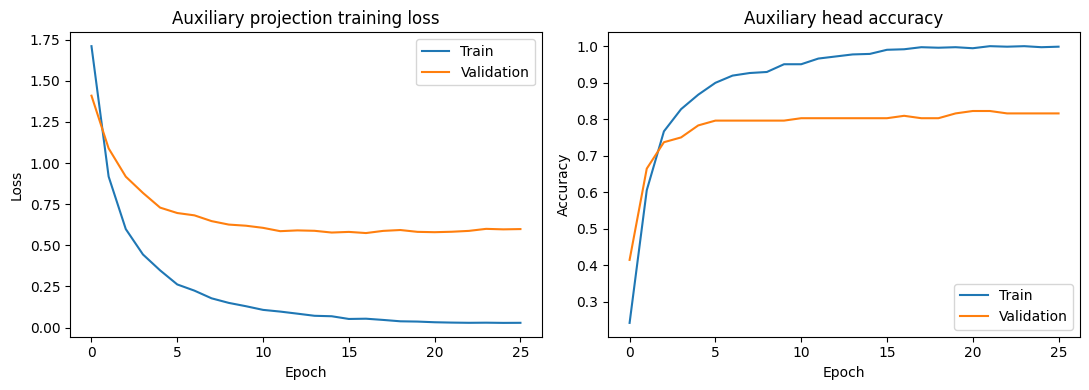


STEP 5 FINISHED — TRAINED 768-D FUSION
Outputs: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion
Audit: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step5_Full_768D_Learned_Fusion/Reports/Step5_Fusion_Matching_Audit.csv
Next: STEP 6 — train five-class HH-SNN on full Train_Fused_768D.csv,
validate on Validation_Fused_768D.csv, and evaluate on Test_Fused_768D.csv.


In [13]:
# ================================================================
# DERM7PT — STEP 5: TRAINED 256-D PROJECTIONS + 768-D FUSION
# Full-dataset Google Colab code, compatible with Step 4 full features
# No HH-SNN training in this step; that is Step 6.
# ================================================================
# Colab dependency (run in a separate cell if needed):
# %pip -q install tensorflow scikit-learn joblib pandas matplotlib

from pathlib import Path
import os, re, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
EPOCHS = 60
BATCH_SIZE = 32
LR = 1e-4
PROJECTION_DIM = 256
DROPOUT = 0.15
SPLITS = ('Train', 'Validation', 'Test')
CLASSES = ('Nevus', 'Melanoma', 'MISC', 'SK', 'BCC')
REQUIRE_ALL_TRAIN_CLASSES = True

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# --------------------- GOOGLE DRIVE ------------------------------
from google.colab import drive
mydrive = None
for mount in (Path('/content/drive'), Path('/content/gdrive')):
    candidate = mount / 'MyDrive'
    if (candidate / 'Derm7pt').is_dir():
        mydrive = candidate
        break
if mydrive is None:
    for mount in (Path('/content/drive'), Path('/content/gdrive')):
        mount.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(mount)):
            if any(mount.iterdir()):
                continue
            drive.mount(str(mount), force_remount=False)
        candidate = mount / 'MyDrive'
        if (candidate / 'Derm7pt').is_dir():
            mydrive = candidate
            break
if mydrive is None:
    raise FileNotFoundError('Unable to locate Google Drive/MyDrive/Derm7pt. Mount Drive and check the folder name.')

BASE = mydrive / 'Derm7pt'
PREP = BASE / 'Derm7pt_Preprocessed'
STEP4 = PREP / 'Step4_Full_Modality_Features'
OUT = PREP / 'Step5_Full_768D_Learned_Fusion'
MODEL_DIR, REPORT_DIR, VIS_DIR = (OUT / n for n in ('Models', 'Reports', 'Visualizations'))
for p in (OUT, MODEL_DIR, REPORT_DIR, VIS_DIR):
    p.mkdir(parents=True, exist_ok=True)

if not STEP4.is_dir():
    raise FileNotFoundError(f'Step 4 full-dataset features missing: {STEP4}')

# --------------------- LABEL GROUPING ----------------------------
# Clinically chosen research grouping. Audit all diagnoses before training.
# MISC is deliberately explicit, never a catch-all for unknown diagnoses.
DIAGNOSIS_MAP = {

    # CLASS 1: NEVUS
    "nevus": "Nevus",
    "melanocytic nevus": "Nevus",
    "blue nevus": "Nevus",
    "clark nevus": "Nevus",
    "combined nevus": "Nevus",
    "congenital nevus": "Nevus",
    "dermal nevus": "Nevus",
    "compound nevus": "Nevus",
    "junctional nevus": "Nevus",
    "recurrent nevus": "Nevus",
    "reed or spitz nevus": "Nevus",

    # CLASS 2: MELANOMA
    "melanoma": "Melanoma",
    "melanoma (in situ)": "Melanoma",
    "melanoma in situ": "Melanoma",
    "melanoma (less than 0.76 mm)": "Melanoma",
    "melanoma (0.76 to 1.5 mm)": "Melanoma",
    "melanoma (more than 1.5 mm)": "Melanoma",
    "melanoma metastasis": "Melanoma",

    # CLASS 3: BASAL CELL CARCINOMA
    "basal cell carcinoma": "BCC",
    "bcc": "BCC",

    # CLASS 4: SEBORRHEIC KERATOSIS
    "seborrheic keratosis": "SK",
    "seborrhoeic keratosis": "SK",
    "sk": "SK",

    # CLASS 5: MISCELLANEOUS
    "miscellaneous": "MISC",
    "misc": "MISC",
    "dermatofibroma": "MISC",
    "vascular lesion": "MISC",
    "lentigo": "MISC",
    "melanosis": "MISC",
}

print("Updated diagnosis mapping loaded.")
print("Mapped original labels:", len(DIAGNOSIS_MAP))

def clean_id(value):
    if pd.isna(value):
        return ''
    v = str(value).strip()
    return v[:-2] if re.fullmatch(r'\d+\.0', v) else v

def find_col(df, options):
    lookup = {str(c).casefold(): c for c in df.columns}
    for c in options:
        if c.casefold() in lookup:
            return lookup[c.casefold()]
    return None

def normalize_label(v):
    return ' '.join(str(v).strip().lower().split())

# --------------------- READ MANIFEST AND LABELS ------------------
manifest = {}
all_ids = {}
unknown_by_split = {}
for split in SPLITS:
    filename = PREP / f'09_{split}_Image_Manifest.csv'
    if not filename.is_file():
        raise FileNotFoundError(f'Missing original manifest: {filename}')
    frame = pd.read_csv(filename, dtype=str)
    id_col = find_col(frame, ('Lesion_ID', 'case_num', 'Case_ID'))
    label_col = find_col(frame, ('Diagnosis', 'diagnosis'))
    if id_col is None or label_col is None:
        raise ValueError(f'{filename.name}: needs Lesion_ID and Diagnosis columns. Found {list(frame.columns)}')
    m = pd.DataFrame({
        'Lesion_ID': frame[id_col].map(clean_id),
        'Original_Diagnosis': frame[label_col].astype(str),
    })
    if m.Lesion_ID.eq('').any() or m.Lesion_ID.duplicated().any():
        raise ValueError(f'{split}: missing/duplicate Lesion_ID')
    normalized = m.Original_Diagnosis.map(normalize_label)
    m['Diagnosis'] = normalized.map(DIAGNOSIS_MAP)
    missing_labels = sorted(normalized[m.Diagnosis.isna()].unique())
    if missing_labels:
        raise ValueError(
            f'{split}: unmapped original diagnoses: {missing_labels}. '
            'Update DIAGNOSIS_MAP after checking the Derm7pt taxonomy; do not assign unknowns automatically.'
        )
    m['Split'] = split
    manifest[split] = m
    all_ids[split] = set(m.Lesion_ID)
    print(f'{split} class counts: {m.Diagnosis.value_counts().to_dict()}')

for i, a in enumerate(SPLITS):
    for b in SPLITS[i+1:]:
        repeated = all_ids[a] & all_ids[b]
        if repeated:
            raise ValueError(f'Lesion leakage between {a} and {b}: {sorted(repeated)[:15]}')

train_labels = set(manifest['Train'].Diagnosis)
missing_train = sorted(set(CLASSES) - train_labels)
if REQUIRE_ALL_TRAIN_CLASSES and missing_train:
    raise ValueError(f'Training data missing classes {missing_train}; use the full original train split, not the 15-image subset.')

# --------------------- FEATURE LOADING BY LESION_ID -------------
BRANCHES = {
    'derm': ('{split}_ViT_Swin_Dermoscopic_Features.csv', 'd_'),
    'clinical': ('{split}_ConvNeXt_ViT_Clinical_Features.csv', 'c_'),
    'metadata': ('{split}_FTTransformer_Aligned_Metadata_Embeddings.csv', 'm_'),
}

def read_features(split, branch):
    pattern, prefix = BRANCHES[branch]
    path = STEP4 / pattern.format(split=split)
    if not path.is_file():
        raise FileNotFoundError(f'Missing Step 4 {branch} features: {path}')
    feat = pd.read_csv(path, dtype={'Lesion_ID': str})
    col = find_col(feat, ('Lesion_ID', 'lesion_id', 'case_num'))
    if col is None:
        raise ValueError(f'{path.name} has no lesion ID; row-order joining is forbidden.')
    feat['Lesion_ID'] = feat[col].map(clean_id)
    if feat.Lesion_ID.eq('').any() or feat.Lesion_ID.duplicated().any():
        raise ValueError(f'{path.name}: missing or duplicate IDs')
    # Only accept feature columns, not label/target/control fields.
    ignore = {col, 'Lesion_ID', 'Split', 'Diagnosis', 'Diagnosis_Code',
              'Original_Diagnosis', 'Original_Row', 'Is_Augmented', 'target', 'label'}
    candidate_cols = [c for c in feat.columns if c not in ignore]
    if not candidate_cols:
        raise ValueError(f'{path.name}: no numeric feature columns')
    # Strictly require a consistent schema from the same Step 4 encoder.
    for c in candidate_cols:
        feat[c] = pd.to_numeric(feat[c], errors='coerce')
    feat = feat[['Lesion_ID'] + candidate_cols].copy()
    return feat.rename(columns={c: prefix+str(c) for c in candidate_cols})

joined = {}
schema = {}
audit_rows = []
for split in SPLITS:
    merged = manifest[split].copy()
    for branch in BRANCHES:
        feat = read_features(split, branch)
        feat_cols = [c for c in feat.columns if c != 'Lesion_ID']
        if split == 'Train':
            schema[branch] = feat_cols
        elif feat_cols != schema[branch]:
            raise ValueError(f'{split}/{branch}: feature columns differ from training; rerun Step 4 consistently.')
        merged = merged.merge(feat, on='Lesion_ID', how='left', validate='one_to_one')
        numeric = merged[feat_cols].apply(pd.to_numeric, errors='coerce')
        merged[f'Has_{branch}'] = numeric.notna().any(axis=1)
    joined[split] = merged
    a = merged[['Lesion_ID', 'Split', 'Diagnosis', 'Has_derm', 'Has_clinical', 'Has_metadata']].copy()
    a['Complete_Three_Modalities'] = a[['Has_derm', 'Has_clinical', 'Has_metadata']].all(axis=1)
    audit_rows.append(a)
    print(f'{split}: records={len(merged)}; complete modalities={int(a.Complete_Three_Modalities.sum())}')

availability = pd.concat(audit_rows, ignore_index=True)
availability.to_csv(REPORT_DIR / 'Step5_Fusion_Matching_Audit.csv', index=False)

# --------------------- FIT TRAIN-ONLY PREPROCESSING -------------
# Missing branch: zero vector AFTER centering/scaling, with availability flag.
# Missing individual numeric values: training-median imputation.
transforms = {}
arrays = {split: {} for split in SPLITS}
for branch in BRANCHES:
    columns = schema[branch]
    train_x = joined['Train'][columns].to_numpy(dtype=np.float32)
    if not np.isfinite(train_x).any():
        raise ValueError(f'No usable training features in {branch} branch.')
    # Avoid treating inf as valid observations.
    train_x[~np.isfinite(train_x)] = np.nan
    all_nan_cols = np.isnan(train_x).all(axis=0)
    if all_nan_cols.any():
        raise ValueError(f'{branch}: {int(all_nan_cols.sum())} feature columns entirely missing in train. Fix Step 4.')
    imp = SimpleImputer(strategy='median', keep_empty_features=True)
    sc = StandardScaler()
    sc.fit(imp.fit_transform(train_x))
    transforms[branch] = {'imputer': imp, 'scaler': sc, 'columns': columns}
    for split in SPLITS:
        x = joined[split][columns].to_numpy(dtype=np.float32)
        x[~np.isfinite(x)] = np.nan
        missing_modality = ~joined[split][f'Has_{branch}'].to_numpy(dtype=bool)
        processed = sc.transform(imp.transform(x)).astype(np.float32)
        processed[missing_modality] = 0.0  # neutral standardized vector
        if not np.isfinite(processed).all():
            raise ValueError(f'Nonfinite features remain in {split}/{branch}')
        arrays[split][branch] = processed
        arrays[split][f'has_{branch}'] = (~missing_modality).astype(np.float32)[:, None]

# --------------------- TRAINABLE PROJECTION + AUXILIARY HEAD ----
# The auxiliary diagnosis head supplies supervised gradients that learn
# projections on TRAIN only; it is NOT the later HH-SNN classifier.
# Validation is only for early stopping; test labels are never used to fit.
L = tf.keras.layers
input_layers = {}
projection_layers = []
availability_layers = []
for branch in BRANCHES:
    dim = len(schema[branch])
    inp = L.Input(shape=(dim,), name=f'{branch}_input')
    present = L.Input(shape=(1,), name=f'{branch}_present')
    x = L.Dense(PROJECTION_DIM, activation='gelu', name=f'{branch}_projection')(inp)
    # Mask the projection INCLUDING its bias when modality unavailable.
    projected = L.Multiply(name=f'{branch}_masked')([x, present])
    input_layers[branch] = inp
    input_layers[f'has_{branch}'] = present
    projection_layers.append(projected)
    availability_layers.append(present)

fusion = L.Concatenate(name='fused_768d')(projection_layers)
flags = L.Concatenate(name='availability_flags')(availability_layers)
x = L.Concatenate(name='fusion_with_flags')([fusion, flags])
x = L.Dense(128, activation='gelu', name='aux_hidden')(x)
x = L.Dropout(DROPOUT, name='aux_dropout')(x)
output = L.Dense(len(CLASSES), activation='softmax', name='aux_diagnosis')(x)
ordered_inputs = [input_layers[k] for k in
                  ('derm','has_derm','clinical','has_clinical','metadata','has_metadata')]
trainer = tf.keras.Model(ordered_inputs, output, name='Derm7pt_Trainable_Fusion')
projector = tf.keras.Model(ordered_inputs, fusion, name='Derm7pt_768D_Projector')
trainer.compile(optimizer=tf.keras.optimizers.Adam(LR),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
trainer.summary()

class_to_int = {c: i for i, c in enumerate(CLASSES)}
y = {s: joined[s].Diagnosis.map(class_to_int).to_numpy(dtype=np.int32) for s in SPLITS}

def as_inputs(split):
    d = arrays[split]
    return [d['derm'], d['has_derm'], d['clinical'], d['has_clinical'],
            d['metadata'], d['has_metadata']]

train_counts = np.bincount(y['Train'], minlength=len(CLASSES))
weights = {i: len(y['Train']) / (len(CLASSES) * max(int(n), 1))
           for i, n in enumerate(train_counts)}

best = MODEL_DIR / 'Best_Trainable_Fusion.keras'
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(str(best), save_best_only=True,
                                       monitor='val_loss', mode='min', verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=9,
                                     restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5,
                                         patience=4, min_lr=1e-6),
    tf.keras.callbacks.CSVLogger(str(REPORT_DIR / 'Fusion_Training_Log.csv')),
]
print('Training three learned 256-D projections...')
history = trainer.fit(
    as_inputs('Train'), y['Train'],
    validation_data=(as_inputs('Validation'), y['Validation']),
    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks,
    class_weight=weights, verbose=2,
)

# Rebuild projection submodel sharing loaded best weights.
trainer = tf.keras.models.load_model(best, compile=False)
projector = tf.keras.Model(inputs=trainer.inputs,
                           outputs=trainer.get_layer('fused_768d').output,
                           name='Derm7pt_768D_Projector')
projector.save(MODEL_DIR / 'Best_768D_Projector.keras')
joblib.dump(transforms, MODEL_DIR / 'Train_Fitted_Feature_Preprocessing.joblib')

# --------------------- EXPORT LEARNED 768-D FEATURES ------------
summary = {'classes': list(CLASSES), 'projection_dim': PROJECTION_DIM,
           'fused_dim': PROJECTION_DIM * len(BRANCHES),
           'training_samples': len(joined['Train']), 'splits': {},
           'image_feature_sources': 'Frozen independent pretrained image backbones from Step 4',
           'learning': 'Supervised auxiliary diagnosis head; trained projections only; HH-SNN not trained here',
           'notes': [
               'All modality joining performed by Lesion_ID, not row order.',
               'Missing modality masks and imputation learned from training only.',
               'No features synthesized for absent modalities.',
               'This is an auxiliary-supervised projection baseline, not the exact PDF end-to-end encoder architecture.',
               'Projected test features depend on train labels and validation-based checkpoint selection, not test labels.',
           ]}
for split in SPLITS:
    vectors = projector.predict(as_inputs(split), batch_size=128, verbose=0)
    vectors = np.asarray(vectors, dtype=np.float32)
    if vectors.shape != (len(joined[split]), 768):
        raise RuntimeError(f'{split} unexpected fused shape: {vectors.shape}')
    if not np.isfinite(vectors).all():
        raise RuntimeError(f'{split} contains nonfinite fused features')
    output_df = pd.DataFrame(vectors, columns=[f'Fusion_{i:03d}' for i in range(768)])
    output_df.insert(0, 'Lesion_ID', joined[split].Lesion_ID.to_numpy())
    output_df.insert(1, 'Diagnosis', joined[split].Diagnosis.to_numpy())
    output_df.insert(2, 'Split', split)
    csv_file = OUT / f'{split}_Fused_768D.csv'
    output_df.to_csv(csv_file, index=False)
    np.savez_compressed(OUT / f'{split}_Fused_768D.npz', X=vectors,
                        y=y[split], Lesion_ID=joined[split].Lesion_ID.to_numpy(dtype=str),
                        classes=np.asarray(CLASSES))
    summary['splits'][split] = {'records': int(len(vectors)), 'feature_dim':768,
                                 'class_counts': joined[split].Diagnosis.value_counts().to_dict(),
                                 'complete_modality_records': int(availability.loc[
                                     availability.Split.eq(split), 'Complete_Three_Modalities'].sum()),
                                 'file': str(csv_file)}
    print(f'{split}: fused features {vectors.shape} -> {csv_file}')

with open(REPORT_DIR / 'Step5_Fusion_Summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
with open(REPORT_DIR / 'Class_Mapping.json', 'w') as f:
    json.dump(class_to_int, f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set(title='Auxiliary projection training loss', xlabel='Epoch', ylabel='Loss')
axes[0].legend()
axes[1].plot(history.history['accuracy'], label='Train')
axes[1].plot(history.history['val_accuracy'], label='Validation')
axes[1].set(title='Auxiliary head accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[1].legend()
fig.tight_layout()
fig.savefig(VIS_DIR / 'Step5_Projection_Training_Curves.png', dpi=160)
plt.show()
plt.close(fig)

print('\nSTEP 5 FINISHED — TRAINED 768-D FUSION')
print('Outputs:', OUT)
print('Audit:', REPORT_DIR / 'Step5_Fusion_Matching_Audit.csv')
print('Next: STEP 6 — train five-class HH-SNN on full Train_Fused_768D.csv,')
print('validate on Validation_Fused_768D.csv, and evaluate on Test_Fused_768D.csv.')


Device: cuda
Train: (707, 768); class counts {'Nevus': 393, 'Melanoma': 185, 'MISC': 65, 'SK': 35, 'BCC': 29}
Validation: (152, 768); class counts {'Nevus': 95, 'Melanoma': 34, 'MISC': 12, 'BCC': 7, 'SK': 4}
Test: (152, 768); class counts {'Nevus': 87, 'Melanoma': 33, 'MISC': 20, 'SK': 6, 'BCC': 6}

Model: HHDynamicsClassifier(
  (input_projection): Linear(in_features=768, out_features=256, bias=True)
  (membrane): HHMembrane()
  (classifier): Sequential(
    (0): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=512, out_features=128, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)
Trainable parameters: 264197
Epoch 001 | loss=1.0749 acc=0.7440 | val_loss=0.7757 val_acc=0.7961
Epoch 002 | loss=0.4253 acc=0.8600 | val_loss=0.7516 val_acc=0.8026
Epoch 003 | loss=0.2212 acc=0.8939 | val_loss=0.7787 val_acc=0.7961
Epoch 004 | loss=0.1144 acc=0.9477 | val_lo

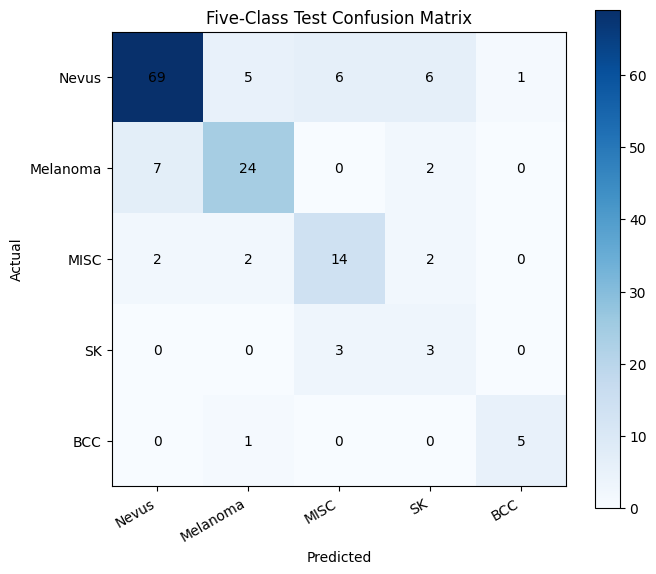

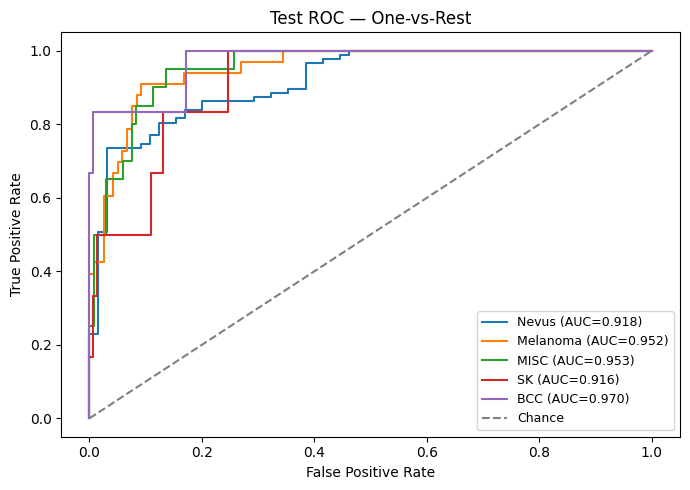

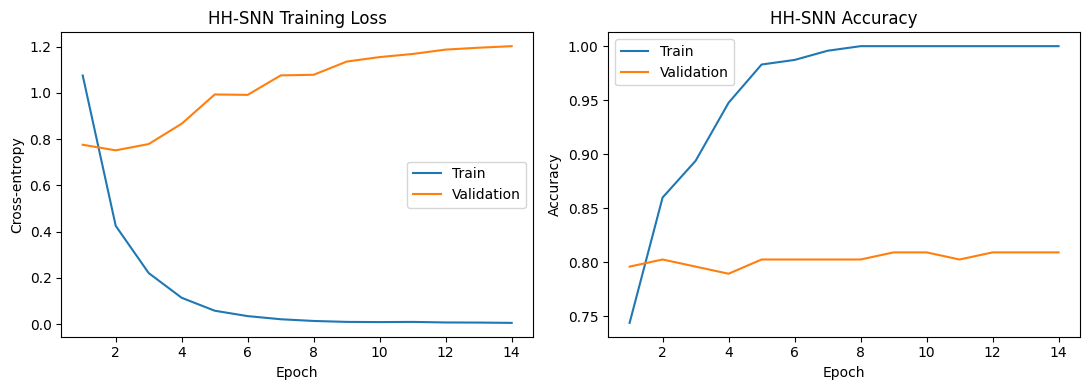


STEP 6 FINISHED
Best epoch: 2
Saved model: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step6_Full_FiveClass_HHSNN/Models/Best_HH_Dynamics_Classifier.pt
Predictions and metrics: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step6_Full_FiveClass_HHSNN/Reports
Visualizations: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step6_Full_FiveClass_HHSNN/Visualizations


In [1]:
# ================================================================
# DERM7PT STEP 6 — FULL-DATA 5-CLASS HH-DYNAMICS-INSPIRED SNN
# Input: Step5_Full_768D_Learned_Fusion/{Train,Validation,Test}_Fused_768D.csv
# Train only on Train; Validation for early stopping; Test for final reporting.
# 256 conductance-based neurons; 20 numerical membrane steps; PyTorch.
# This is a differentiable HH-inspired approximation, NOT a reproduction
# of a validated precise biological HH spike simulator or paper HH-SNN.
# ================================================================
# Google Colab: %pip -q install torch pandas numpy scikit-learn matplotlib joblib
import os, re, json, copy, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
    balanced_accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, auc)
import joblib

SEED = 42
EPOCHS = 80
PATIENCE = 12
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
N_HH_NEURONS = 256
TIME_STEPS = 20
DT_MS = 0.05
DROPOUT = 0.2
SPLITS = ('Train', 'Validation', 'Test')
CLASSES = ('Nevus', 'Melanoma', 'MISC', 'SK', 'BCC')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

# --------------------- Google Drive ------------------------------
def find_project():
    for mount in (Path('/content/drive'), Path('/content/gdrive')):
        p = mount / 'MyDrive' / 'Derm7pt'
        if p.is_dir(): return p
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError('Run in Colab with your Google Drive mounted.')
    for mount in (Path('/content/drive'), Path('/content/gdrive')):
        mount.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(mount)) and not any(mount.iterdir()):
            drive.mount(str(mount), force_remount=False)
        p = mount / 'MyDrive' / 'Derm7pt'
        if p.is_dir(): return p
    raise FileNotFoundError('Could not locate MyDrive/Derm7pt; mount Drive first.')

BASE = find_project()
PREP = BASE / 'Derm7pt_Preprocessed'
IN_DIR = PREP / 'Step5_Full_768D_Learned_Fusion'
OUT = PREP / 'Step6_Full_FiveClass_HHSNN'
MODEL_DIR = OUT / 'Models'; REPORT_DIR = OUT / 'Reports'; VIS_DIR = OUT / 'Visualizations'
for d in (MODEL_DIR, REPORT_DIR, VIS_DIR): d.mkdir(parents=True, exist_ok=True)

# --------------------- Read and audit Step 5 files ---------------
feature_cols = [f'Fusion_{i:03d}' for i in range(768)]
frames = {}; data = {}; ids_by_split = {}
for split in SPLITS:
    p = IN_DIR / f'{split}_Fused_768D.csv'
    if not p.is_file():
        raise FileNotFoundError(f'Missing Step 5 full fusion output: {p}\nRun FULL Step 5 first; do not use 15-image quick files.')
    df = pd.read_csv(p, dtype={'Lesion_ID': str}, low_memory=False)
    required = {'Lesion_ID', 'Diagnosis', 'Split', *feature_cols}
    missing = required - set(df.columns)
    if missing: raise ValueError(f'{p.name} missing columns: {sorted(missing)[:15]}')
    if len(df) == 0: raise ValueError(f'{split}: empty fused file')
    df['Lesion_ID'] = df['Lesion_ID'].astype(str).str.strip().str.replace(r'(?<=\d)\.0$', '', regex=True)
    if df['Lesion_ID'].eq('').any() or df['Lesion_ID'].duplicated().any():
        raise ValueError(f'{split}: empty or duplicated lesion IDs')
    if not df['Split'].astype(str).eq(split).all():
        raise ValueError(f'{split}: Split column disagrees with its filename')
    if df['Diagnosis'].isna().any(): raise ValueError(f'{split}: missing labels')
    unknown = set(df['Diagnosis'].astype(str)) - set(CLASSES)
    if unknown: raise ValueError(f'{split}: unknown diagnoses {sorted(unknown)}')
    x = df[feature_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float32)
    if x.shape[1] != 768 or not np.isfinite(x).all():
        raise ValueError(f'{split}: expected 768 finite fusion features per sample')
    y = df['Diagnosis'].astype(str).map({c: i for i, c in enumerate(CLASSES)}).to_numpy(dtype=np.int64)
    frames[split] = df[['Lesion_ID', 'Diagnosis', 'Split']].copy()
    data[split] = {'X': x, 'y': y}
    ids_by_split[split] = set(df['Lesion_ID'])
    print(f'{split}: {x.shape}; class counts {df.Diagnosis.value_counts().to_dict()}')
for i, a in enumerate(SPLITS):
    for b in SPLITS[i+1:]:
        intersection = ids_by_split[a] & ids_by_split[b]
        if intersection: raise ValueError(f'LEAKAGE: {a}/{b} share lesion IDs {sorted(intersection)[:10]}')
missing_train = set(CLASSES) - set(frames['Train']['Diagnosis'])
if missing_train:
    raise ValueError(f'TRAIN missing {sorted(missing_train)}. Need full Step5 and all five classes; will not silently exclude evaluation records.')
if min(len(data[s]['y']) for s in SPLITS) < 2:
    raise ValueError('Validation and Test should each contain at least two records.')

# Fit standardization using TRAIN ONLY. Step 5 already standardized source
# branches; its 768-D output is restandardized for stable HH input currents.
scaler = StandardScaler()
data['Train']['X'] = scaler.fit_transform(data['Train']['X']).astype(np.float32)
for split in ('Validation', 'Test'):
    data[split]['X'] = scaler.transform(data[split]['X']).astype(np.float32)
for split in SPLITS:
    if not np.isfinite(data[split]['X']).all(): raise ValueError(f'{split}: nonfinite scaled data')
joblib.dump({'scaler': scaler, 'classes': CLASSES, 'columns': feature_cols}, MODEL_DIR / 'HH_TrainOnly_Scaler.joblib')

# --------------------- Differentiable HH-inspired membrane -------
class HHMembrane(nn.Module):
    """Conductance-based HH-style updates for m/h/n gating and voltage.

    Uses Euler integration over TIME_STEPS and differentiable voltage/spike
    summaries rather than hard, non-differentiable threshold spike events.
    This is an HH-dynamics-inspired approximation for classification.
    """
    def __init__(self, steps=20, dt=0.05):
        super().__init__()
        self.steps, self.dt = int(steps), float(dt)
        self.g_na, self.g_k, self.g_l = 120.0, 36.0, 0.3
        self.e_na, self.e_k, self.e_l = 50.0, -77.0, -54.387

    @staticmethod
    def vtrap(x, scale):
        # Numerically stable x/(1-exp(-x/scale)) near x=0.
        z = (x / scale).clamp(-30, 30)
        denominator = torch.where(torch.abs(z) < 1e-4,
                                  torch.ones_like(z), -torch.expm1(-z))
        return torch.where(torch.abs(z) < 1e-4,
                           scale * (1 + z/2 + z*z/12), x / denominator)

    def forward(self, current):
        v = torch.full_like(current, -65.0)
        m = torch.full_like(current, 0.0529)
        h = torch.full_like(current, 0.5961)
        n = torch.full_like(current, 0.3177)
        voltage_integral = torch.zeros_like(current)
        spike_proxy = torch.zeros_like(current)
        for _ in range(self.steps):
            am = 0.1 * self.vtrap(v + 40.0, 10.0)
            bm = 4.0 * torch.exp((-(v + 65.0) / 18.0).clamp(-30, 30))
            ah = 0.07 * torch.exp((-(v + 65.0) / 20.0).clamp(-30, 30))
            bh = torch.sigmoid((v + 35.0) / 10.0)
            an = 0.01 * self.vtrap(v + 55.0, 10.0)
            bn = 0.125 * torch.exp((-(v + 65.0) / 80.0).clamp(-30, 30))
            m = torch.clamp(m + self.dt * (am * (1 - m) - bm * m), 0, 1)
            h = torch.clamp(h + self.dt * (ah * (1 - h) - bh * h), 0, 1)
            n = torch.clamp(n + self.dt * (an * (1 - n) - bn * n), 0, 1)
            ion_na = self.g_na * (m ** 3) * h * (v - self.e_na)
            ion_k = self.g_k * (n ** 4) * (v - self.e_k)
            ion_l = self.g_l * (v - self.e_l)
            v = torch.clamp(v + self.dt * (current - ion_na - ion_k - ion_l), -100, 80)
            voltage_integral = voltage_integral + (v + 65.0) / 100.0
            spike_proxy = spike_proxy + torch.sigmoid((v + 20.0) / 5.0)
        # Surrogate spike activation and membrane voltage feature.
        return torch.cat([voltage_integral / self.steps, spike_proxy / self.steps], dim=1)

class HHDynamicsClassifier(nn.Module):
    def __init__(self, in_dim=768, neurons=256, n_classes=5):
        super().__init__()
        self.input_projection = nn.Linear(in_dim, neurons)
        self.membrane = HHMembrane(steps=TIME_STEPS, dt=DT_MS)
        self.classifier = nn.Sequential(
            nn.LayerNorm(neurons * 2),
            nn.Linear(neurons * 2, 128), nn.GELU(),
            nn.Dropout(DROPOUT), nn.Linear(128, n_classes)
        )
    def forward(self, x):
        # Bounded stimulus current; range permits membrane response.
        current = 12.0 + 18.0 * torch.tanh(self.input_projection(x))
        state = self.membrane(current)
        return self.classifier(state)

model = HHDynamicsClassifier(n_classes=len(CLASSES)).to(DEVICE)
print('\nModel:', model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

# --------------------- Train -------------------------------------
def loader(split, shuffle=False):
    obj = data[split]
    ds = TensorDataset(torch.tensor(obj['X']), torch.tensor(obj['y']))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)
train_loader = loader('Train', shuffle=True)
val_loader = loader('Validation')
train_count = np.bincount(data['Train']['y'], minlength=len(CLASSES))
class_weights = len(data['Train']['y']) / (len(CLASSES) * train_count)
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE))
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4)

def one_epoch(dataloader, train=False):
    model.train(train)
    total_loss, predictions, truths, total = 0., [], [], 0
    for x, y in dataloader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if train: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(train):
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
                optimizer.step()
        total_loss += float(loss.item()) * len(y)
        predictions.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())
        truths.extend(y.detach().cpu().numpy().tolist())
        total += len(y)
    return total_loss / max(total, 1), accuracy_score(truths, predictions)

log = []; best_val, best_epoch, stagnant = float('inf'), 0, 0
checkpoint = MODEL_DIR / 'Best_HH_Dynamics_Classifier.pt'
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = one_epoch(train_loader, train=True)
    val_loss, val_acc = one_epoch(val_loader, train=False)
    if not all(np.isfinite(v) for v in (train_loss, train_acc, val_loss, val_acc)):
        raise RuntimeError('Non-finite training metrics. Inspect input data or lower LEARNING_RATE.')
    log.append({'epoch': epoch, 'loss': train_loss, 'accuracy': train_acc,
                'val_loss': val_loss, 'val_accuracy': val_acc,
                'learning_rate': optimizer.param_groups[0]['lr']})
    scheduler.step(val_loss)
    print(f'Epoch {epoch:03d} | loss={train_loss:.4f} acc={train_acc:.4f} | '
          f'val_loss={val_loss:.4f} val_acc={val_acc:.4f}')
    if val_loss < best_val - 1e-5:
        best_val, best_epoch, stagnant = val_loss, epoch, 0
        torch.save({'state_dict': copy.deepcopy(model.state_dict()), 'classes': CLASSES,
                    'input_dim': 768, 'neurons': N_HH_NEURONS, 'time_steps': TIME_STEPS,
                    'dt_ms': DT_MS, 'seed': SEED}, checkpoint)
    else:
        stagnant += 1
        if stagnant >= PATIENCE:
            print('Early stopping at epoch', epoch)
            break
pd.DataFrame(log).to_csv(REPORT_DIR / 'HH_Training_Log.csv', index=False)
try:
    saved = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
except TypeError:
    saved = torch.load(checkpoint, map_location=DEVICE)
model.load_state_dict(saved['state_dict'])
model.eval()

# --------------------- Predict and evaluate ----------------------
@torch.no_grad()
def predict(split):
    probabilities = []
    for x, _ in loader(split):
        probabilities.append(torch.softmax(model(x.to(DEVICE)), dim=1).cpu().numpy())
    return np.concatenate(probabilities, axis=0)

all_metrics = []
all_roc = {}
for split in SPLITS:
    probs = predict(split)
    yt = data[split]['y']
    yp = probs.argmax(axis=1)
    frame = frames[split].copy()
    frame['Predicted_Diagnosis'] = [CLASSES[i] for i in yp]
    frame['Correct'] = yt == yp
    for j, c in enumerate(CLASSES):
        frame[f'Probability_{c}'] = probs[:, j]
    frame.to_csv(REPORT_DIR / f'{split}_Predictions.csv', index=False)
    precision, recall, f1, support = precision_recall_fscore_support(
        yt, yp, labels=np.arange(len(CLASSES)), zero_division=0)
    per_class = pd.DataFrame({'Class': CLASSES, 'Support': support,
                              'Precision': precision, 'Recall_Sensitivity': recall, 'F1': f1})
    cm = confusion_matrix(yt, yp, labels=np.arange(len(CLASSES)))
    per_class['Specificity'] = [(cm.sum() - cm[j,:].sum() - cm[:,j].sum() + cm[j,j]) /
        max(cm.sum() - cm[j,:].sum() - cm[:,j].sum() + cm[j,j] + cm[:,j].sum() - cm[j,j], 1)
        for j in range(len(CLASSES))]
    per_class.to_csv(REPORT_DIR / f'{split}_Per_Class_Metrics.csv', index=False)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        yt, yp, labels=np.arange(len(CLASSES)), average='macro', zero_division=0)
    present = np.unique(yt)
    balanced = balanced_accuracy_score(yt, yp)
    # AUC is only calculated for classes with positives AND negatives.
    aucs = {}
    for j, c in enumerate(CLASSES):
        truth = (yt == j).astype(int)
        if len(np.unique(truth)) == 2:
            aucs[c] = float(roc_auc_score(truth, probs[:, j]))
        else:
            aucs[c] = None
    if all(value is not None for value in aucs.values()):
        macro_auc = float(np.mean(list(aucs.values())))
    else:
        macro_auc = None
    metrics = {'Split': split, 'Samples': len(yt), 'Classes_in_truth': len(present),
               'Accuracy': float(accuracy_score(yt, yp)), 'Balanced_Accuracy': float(balanced),
               'Macro_Precision_5class': float(macro_p), 'Macro_Recall_5class': float(macro_r),
               'Macro_F1_5class': float(macro_f1), 'Macro_OVR_ROC_AUC': macro_auc}
    all_metrics.append(metrics)
    print(split, metrics)
    print(classification_report(yt, yp, labels=np.arange(len(CLASSES)),
          target_names=CLASSES, zero_division=0))
    np.save(REPORT_DIR / f'{split}_Confusion_Matrix.npy', cm)
    if split == 'Test':
        fig, ax = plt.subplots(figsize=(7, 6))
        heat = ax.imshow(cm, cmap='Blues')
        ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha='right')
        ax.set_yticks(range(len(CLASSES)), CLASSES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        ax.set_title('Five-Class Test Confusion Matrix')
        for r in range(len(CLASSES)):
            for c in range(len(CLASSES)):
                ax.text(c, r, str(cm[r,c]), ha='center', va='center', fontsize=10)
        fig.colorbar(heat, ax=ax); fig.tight_layout()
        fig.savefig(VIS_DIR / 'Test_Confusion_Matrix.png', dpi=170)
        plt.show(); plt.close(fig)
        fig, ax = plt.subplots(figsize=(7, 5))
        n_curves = 0
        for j, c in enumerate(CLASSES):
            true_bin = (yt == j).astype(int)
            if len(np.unique(true_bin)) < 2: continue
            fpr, tpr, _ = roc_curve(true_bin, probs[:, j])
            ax.plot(fpr, tpr, label=f'{c} (AUC={auc(fpr,tpr):.3f})')
            n_curves += 1
        ax.plot([0,1], [0,1], '--', color='gray', label='Chance')
        ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='Test ROC — One-vs-Rest')
        if n_curves: ax.legend(fontsize=9)
        else: ax.text(.1,.5,'No class has both positives and negatives',transform=ax.transAxes)
        fig.tight_layout(); fig.savefig(VIS_DIR / 'Test_ROC_Curves.png', dpi=170)
        plt.show(); plt.close(fig)
    all_roc[split] = aucs

pd.DataFrame(all_metrics).to_csv(REPORT_DIR / 'HH_Summary_Metrics.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hist = pd.DataFrame(log)
ax[0].plot(hist['epoch'], hist['loss'], label='Train')
ax[0].plot(hist['epoch'], hist['val_loss'], label='Validation')
ax[0].set(xlabel='Epoch', ylabel='Cross-entropy', title='HH-SNN Training Loss'); ax[0].legend()
ax[1].plot(hist['epoch'], hist['accuracy'], label='Train')
ax[1].plot(hist['epoch'], hist['val_accuracy'], label='Validation')
ax[1].set(xlabel='Epoch', ylabel='Accuracy', title='HH-SNN Accuracy'); ax[1].legend()
fig.tight_layout(); fig.savefig(VIS_DIR / 'HH_Training_Curves.png', dpi=170)
plt.show(); plt.close(fig)

summary = {'architecture': 'Differentiable Hodgkin-Huxley-dynamics-inspired classifier',
           'exact_paper_replication': False,
           'n_classes': 5, 'classes': list(CLASSES),
           'hidden_neurons': N_HH_NEURONS, 'time_steps': TIME_STEPS,
           'step_dt_ms': DT_MS, 'best_epoch': best_epoch, 'best_val_loss': best_val,
           'train_only_scaling': True,
           'train_validation_test_sizes': {s: len(data[s]['y']) for s in SPLITS},
           'results': all_metrics, 'per_class_roc_auc': all_roc,
           'limitations': [
             'HH gate/voltage dynamics are differentiable and use a surrogate spiking summary, not hard biological spikes.',
             'Full 5-class evaluation needs adequate labeled test examples for every class.',
             'Source Step 4 encoders are pretrained frozen concatenations, not exact paper hybrid backbones.',
             'Any cross-split ID leakage at patient-level must also be checked if patient identifiers exist.']}
with open(REPORT_DIR / 'Step6_HH_SNN_Summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('\nSTEP 6 FINISHED')
print('Best epoch:', best_epoch)
print('Saved model:', checkpoint)
print('Predictions and metrics:', REPORT_DIR)
print('Visualizations:', VIS_DIR)


Train: 707 predictions; original class counts: {'Nevus': 393, 'Melanoma': 185, 'MISC': 65, 'SK': 35, 'BCC': 29}
Validation: 152 predictions; original class counts: {'Nevus': 95, 'Melanoma': 34, 'MISC': 12, 'BCC': 7, 'SK': 4}
Test: 152 predictions; original class counts: {'Nevus': 87, 'Melanoma': 33, 'MISC': 20, 'SK': 6, 'BCC': 6}

Train | Accuracy=0.8996, Macro-F1=0.8827, Macro-AUC=0.9917910241200338


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(



Validation | Accuracy=0.8026, Macro-F1=0.7053, Macro-AUC=0.9466259259755219


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: T


TEST 95% bootstrap intervals (lesion-level resampling):
                Metric  CI_95_Lower  CI_95_Upper  Defined_Bootstrap_Replicates  Total_Bootstrap_Replicates
              Accuracy     0.684211     0.822368                          1000                        1000
       Macro_F1_5class     0.549354     0.760363                          1000                        1000
Macro_OVR_ROC_AUC_All5     0.911079     0.966708                           992                        1000

Test | Accuracy=0.7566, Macro-F1=0.6750, Macro-AUC=0.9417285466994405


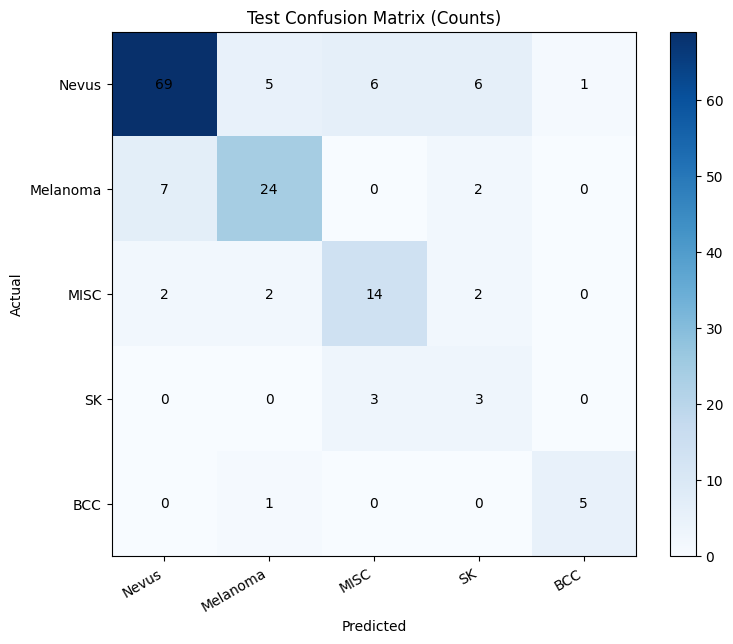

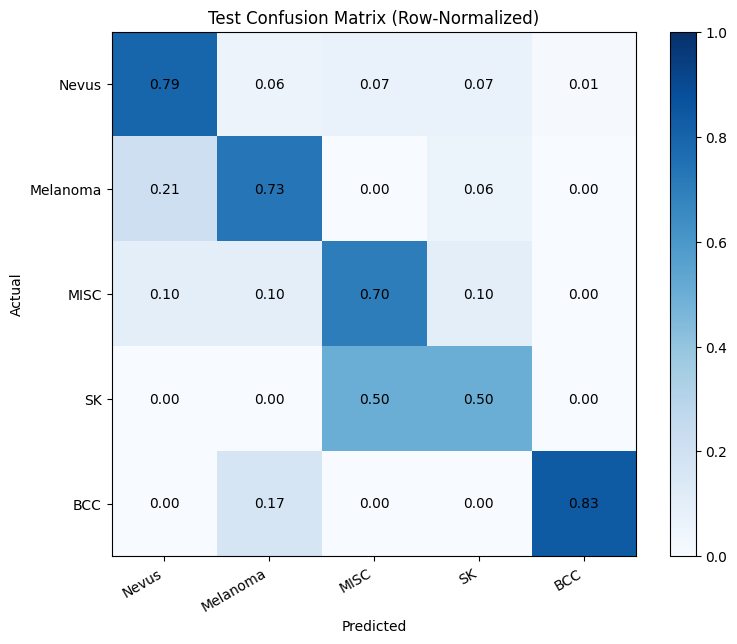

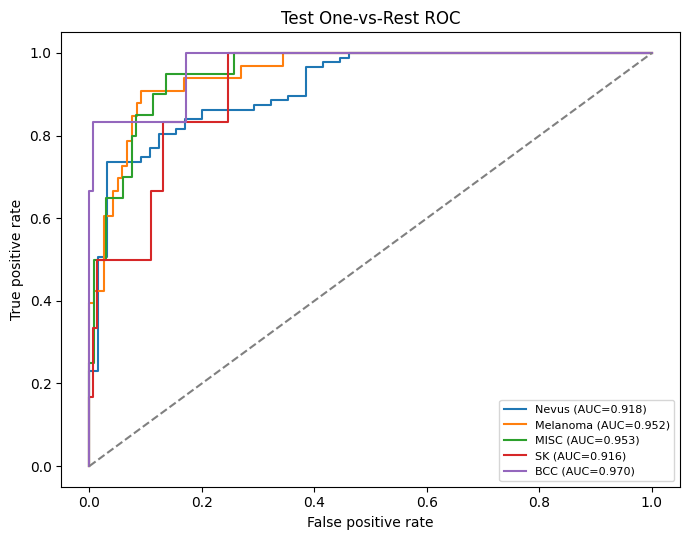

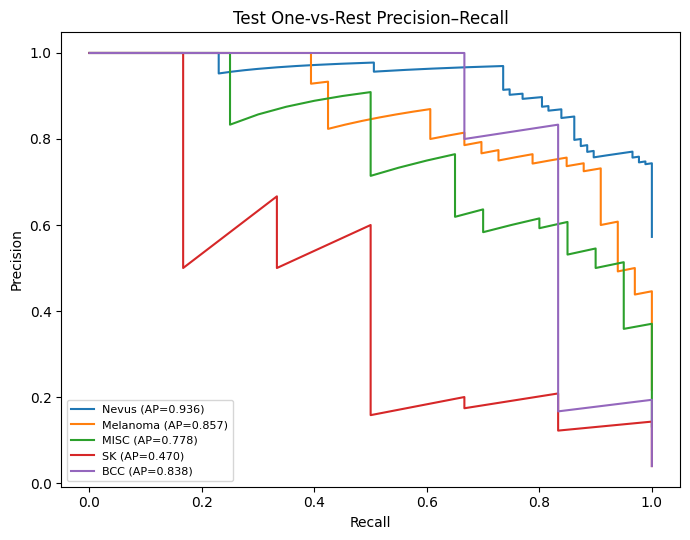

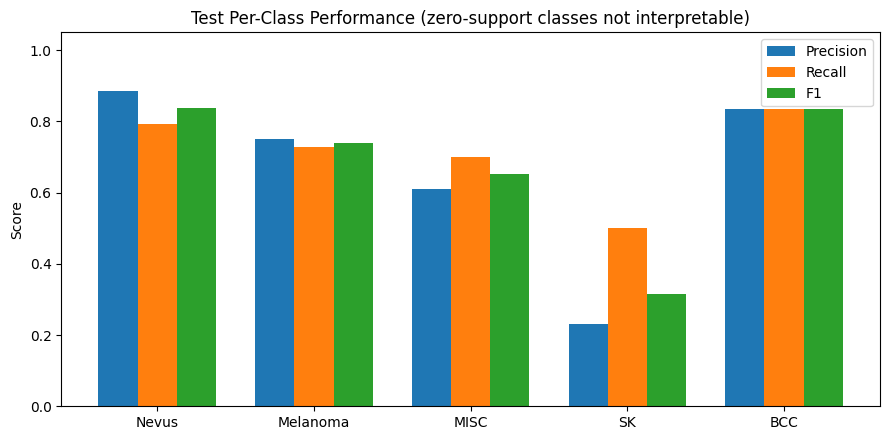

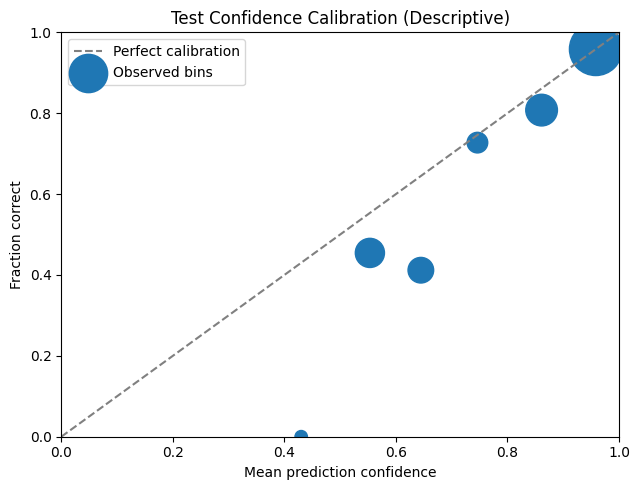

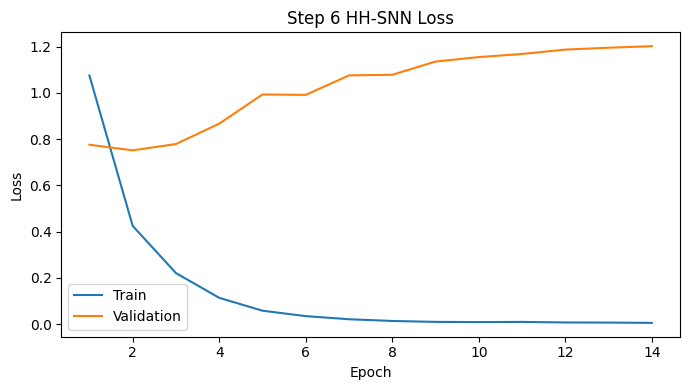

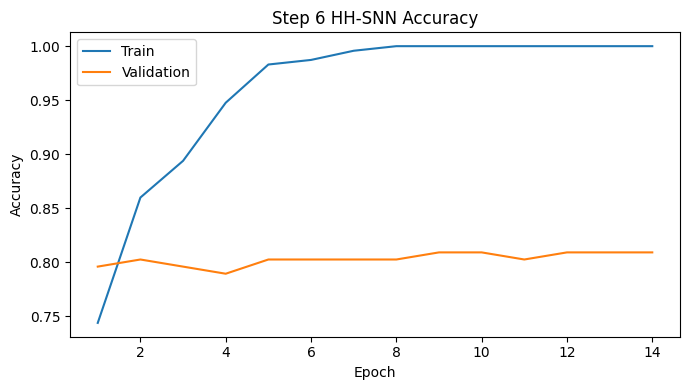


STEP 7 COMPLETED — FULL-DATA HH-SNN EVALUATION
Read-only source: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step6_Full_FiveClass_HHSNN/Reports
Reports: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step7_Full_HHSNN_Evaluation/Reports
Visualizations: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step7_Full_HHSNN_Evaluation/Visualizations
NEXT: Step 8 — XAI (SHAP / Integrated Gradients / encoder-specific Grad-CAM)


In [2]:
# ================================================================
# DERM7PT — STEP 7: INDEPENDENT 5-CLASS HH-SNN EVALUATION
# Input: Step6_Full_FiveClass_HHSNN/Reports/*_Predictions.csv
#        Step6_Full_FiveClass_HHSNN/Reports/HH_Training_Log.csv
# Does NOT retrain, refit, or infer new predictions.
# Reports undefined statistics as NaN; never substitutes values.
# ================================================================
# Colab: %pip -q install numpy pandas matplotlib scikit-learn
import os, json, warnings
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, confusion_matrix,
    precision_recall_fscore_support, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score, log_loss,
    balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef)

SEED = 42
BOOTSTRAP_SAMPLES = 1000
BINS = 10
CLASSES = ('Nevus', 'Melanoma', 'MISC', 'SK', 'BCC')
SPLITS = ('Train', 'Validation', 'Test')
RNG = np.random.default_rng(SEED)

# ------------------- Drive root ----------------------------------
def resolve_base():
    for mount in ('/content/drive', '/content/gdrive'):
        p = Path(mount) / 'MyDrive' / 'Derm7pt'
        if p.is_dir(): return p
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError('Google Colab Drive not mounted.')
    for mount in ('/content/drive', '/content/gdrive'):
        m = Path(mount)
        m.mkdir(parents=True, exist_ok=True)
        if not (m / 'MyDrive').is_dir() and not any(m.iterdir()):
            drive.mount(str(m), force_remount=False)
        p = m / 'MyDrive' / 'Derm7pt'
        if p.is_dir(): return p
    raise FileNotFoundError('Derm7pt project not found. Mount Drive and verify its path.')

BASE = resolve_base()
PREP = BASE / 'Derm7pt_Preprocessed'
STEP6 = PREP / 'Step6_Full_FiveClass_HHSNN'
SOURCE = STEP6 / 'Reports'
OUT = PREP / 'Step7_Full_HHSNN_Evaluation'
REPORT = OUT / 'Reports'
VIS = OUT / 'Visualizations'
for folder in (REPORT, VIS): folder.mkdir(parents=True, exist_ok=True)
if not SOURCE.is_dir():
    raise FileNotFoundError(f'Step 6 reports not found: {SOURCE}. Run the full-data Step 6 first.')

PROB_COLS = [f'Probability_{name}' for name in CLASSES]
MAP = {label: i for i, label in enumerate(CLASSES)}

# ------------------- Strict prediction audits --------------------
data = {}
ids = {}
for split in SPLITS:
    filename = SOURCE / f'{split}_Predictions.csv'
    if not filename.is_file(): raise FileNotFoundError(f'Missing Step 6 predictions: {filename}')
    df = pd.read_csv(filename, dtype={'Lesion_ID': str}, low_memory=False)
    required = {'Lesion_ID', 'Diagnosis', 'Predicted_Diagnosis', *PROB_COLS}
    absent = required - set(df.columns)
    if absent: raise ValueError(f'{filename.name}: columns missing: {sorted(absent)}')
    if len(df) == 0: raise ValueError(f'{split}: empty predictions')
    df['Lesion_ID'] = df['Lesion_ID'].astype(str).str.strip()
    if df['Lesion_ID'].eq('').any() or df['Lesion_ID'].duplicated().any():
        raise ValueError(f'{split}: blank or duplicated lesion IDs')
    if df['Diagnosis'].isna().any() or df['Predicted_Diagnosis'].isna().any():
        raise ValueError(f'{split}: labels contain missing values')
    unknown = (set(df['Diagnosis'].astype(str)) | set(df['Predicted_Diagnosis'].astype(str))) - set(CLASSES)
    if unknown: raise ValueError(f'{split}: unexpected diagnosis classes: {sorted(unknown)}')
    probs = df[PROB_COLS].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float64)
    if not np.isfinite(probs).all() or (probs < -1e-7).any() or (probs > 1 + 1e-7).any():
        raise ValueError(f'{split}: invalid class probabilities')
    if not np.allclose(probs.sum(axis=1), 1.0, atol=1e-3):
        raise ValueError(f'{split}: class probabilities do not sum to 1')
    y = df.Diagnosis.map(MAP).to_numpy(dtype=int)
    yp = df.Predicted_Diagnosis.map(MAP).to_numpy(dtype=int)
    if not np.array_equal(yp, probs.argmax(axis=1)):
        raise ValueError(f'{split}: predicted labels disagree with probability argmax')
    if 'Split' in df.columns and not df['Split'].astype(str).eq(split).all():
        raise ValueError(f'{split}: split column mismatch')
    data[split] = {'df':df, 'y':y, 'yp':yp, 'p':probs}
    ids[split] = set(df.Lesion_ID)
    print(f'{split}: {len(df)} predictions; original class counts: {df.Diagnosis.value_counts().to_dict()}')
for a,b in combinations(SPLITS,2):
    overlap = ids[a] & ids[b]
    if overlap: raise ValueError(f'Lesion-ID leakage between {a}/{b}: {sorted(overlap)[:10]}')
if not set(CLASSES).issubset(set(data['Train']['df'].Diagnosis)):
    warnings.warn('Training does not include all five diagnoses; report does not establish a full five-class experiment.')

# ------------------- Metrics and bootstrap -----------------------
def safe_auc(y, p):
    values = {}
    for i,c in enumerate(CLASSES):
        yy = (y == i).astype(int)
        values[c] = float(roc_auc_score(yy, p[:,i])) if np.unique(yy).size == 2 else np.nan
    return values

def ece_score(y, p, n_bins=BINS):
    confidence = np.max(p, axis=1)
    correct = (np.argmax(p,axis=1) == y).astype(float)
    edges = np.linspace(0,1,n_bins+1)
    ece = 0.0
    rows = []
    for b in range(n_bins):
        mask = (confidence >= edges[b]) & ((confidence < edges[b+1]) if b<n_bins-1 else (confidence <= edges[b+1]))
        if not np.any(mask): continue
        accuracy = float(correct[mask].mean()); conf = float(confidence[mask].mean())
        ece += mask.mean() * abs(accuracy-conf)
        rows.append({'Bin':b+1, 'N':int(mask.sum()), 'Accuracy':accuracy,
                     'Mean_Confidence':conf, 'Gap':accuracy-conf})
    return float(ece), pd.DataFrame(rows)

def metrics(y,p):
    yp=p.argmax(axis=1)
    pr,re,f1,support=precision_recall_fscore_support(y,yp,labels=np.arange(5),zero_division=0)
    cm=confusion_matrix(y,yp,labels=np.arange(5))
    aucs=safe_auc(y,p)
    macro_auc = float(np.mean(list(aucs.values()))) if all(np.isfinite(v) for v in aucs.values()) else np.nan
    ece,_=ece_score(y,p)
    return {'N':int(len(y)), 'Accuracy':float(accuracy_score(y,yp)),
            'Balanced_Accuracy_Present_Classes':float(balanced_accuracy_score(y,yp)),
            'Macro_Precision_5class':float(np.mean(pr)),
            'Macro_Recall_5class':float(np.mean(re)),
            'Macro_F1_5class':float(np.mean(f1)),
            'Weighted_F1':float(np.average(f1, weights=support)),
            'Cohens_Kappa':float(cohen_kappa_score(y,yp)) if len(np.unique(np.r_[y,yp]))>1 else np.nan,
            'Matthews_Correlation':float(matthews_corrcoef(y,yp)),
            'Log_Loss':float(log_loss(y,p,labels=np.arange(5))),
            'Brier_Multiclass':float(np.mean(np.sum((p-np.eye(5)[y])**2,axis=1))),
            'Expected_Calibration_Error':ece,
            'Macro_OVR_ROC_AUC_All5':macro_auc,
            'Classes_Present_In_GroundTruth':int(np.unique(y).size)}

def bootstrap_intervals(y,p,iterations=BOOTSTRAP_SAMPLES):
    n=len(y)
    values={'Accuracy':[],'Macro_F1_5class':[],'Macro_OVR_ROC_AUC_All5':[]}
    for _ in range(iterations):
        ii=RNG.integers(0,n,n)
        result=metrics(y[ii],p[ii])
        for key in values: values[key].append(result[key])
    rows=[]
    for key,v in values.items():
        arr=np.asarray(v,dtype=float)
        arr=arr[np.isfinite(arr)]
        rows.append({'Metric':key,'CI_95_Lower':float(np.percentile(arr,2.5)) if len(arr) else np.nan,
                     'CI_95_Upper':float(np.percentile(arr,97.5)) if len(arr) else np.nan,
                     'Defined_Bootstrap_Replicates':len(arr), 'Total_Bootstrap_Replicates':iterations})
    return pd.DataFrame(rows)

summary=[]
for split in SPLITS:
    o=data[split]; y,yp,p=o['y'],o['yp'],o['p']; n=len(y)
    record={'Split':split,**metrics(y,p)}
    summary.append(record)
    cm=confusion_matrix(y,yp,labels=np.arange(5))
    pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(REPORT/f'{split}_Confusion_Matrix.csv')
    pr,re,f1,support=precision_recall_fscore_support(y,yp,labels=np.arange(5),zero_division=0)
    per=[]; au=safe_auc(y,p)
    for j,name in enumerate(CLASSES):
        tp=cm[j,j]; fn=cm[j,:].sum()-tp; fp=cm[:,j].sum()-tp
        tn=n-tp-fn-fp
        per.append({'Class':name, 'Support':int(support[j]),'Precision':pr[j],
                    'Recall_Sensitivity':re[j],'Specificity':tn/(tn+fp) if tn+fp else np.nan,
                    'F1':f1[j], 'ROC_AUC_OVR':au[name],
                    'Average_Precision_OVR':float(average_precision_score((y==j).astype(int),p[:,j]))
                      if (y==j).any() and (y!=j).any() else np.nan})
    pd.DataFrame(per).to_csv(REPORT/f'{split}_Per_Class_Complete_Metrics.csv',index=False)
    _, cal=ece_score(y,p)
    cal.to_csv(REPORT/f'{split}_Reliability_Bins.csv',index=False)
    if split=='Test':
        ci=bootstrap_intervals(y,p)
        ci.to_csv(REPORT/'Test_Bootstrap_95CI.csv',index=False)
        print('\nTEST 95% bootstrap intervals (lesion-level resampling):')
        print(ci.to_string(index=False))
    print(f'\n{split} | Accuracy={record["Accuracy"]:.4f}, Macro-F1={record["Macro_F1_5class"]:.4f}, '
          f'Macro-AUC={record["Macro_OVR_ROC_AUC_All5"]}')

pd.DataFrame(summary).to_csv(REPORT/'Step7_All_Split_Summary.csv',index=False)

# ------------------- Visualizations ------------------------------
test=data['Test']; y=test['y']; yp=test['yp']; p=test['p']
cm=confusion_matrix(y,yp,labels=np.arange(5))

# Raw and row-normalized confusion matrices
for normalized in (False,True):
    vals=cm.astype(float)
    if normalized:
        vals=np.divide(vals,vals.sum(axis=1,keepdims=True),
                       out=np.zeros_like(vals),where=vals.sum(axis=1,keepdims=True)>0)
    fig,ax=plt.subplots(figsize=(8,6.5))
    image=ax.imshow(vals,cmap='Blues',vmin=0,vmax=(1 if normalized else None))
    ax.set_xticks(range(5),CLASSES,rotation=30,ha='right');ax.set_yticks(range(5),CLASSES)
    ax.set_xlabel('Predicted');ax.set_ylabel('Actual')
    ax.set_title('Test Confusion Matrix' + (' (Row-Normalized)' if normalized else ' (Counts)'))
    for i in range(5):
        for j in range(5):
            ax.text(j,i,(f'{vals[i,j]:.2f}' if normalized else str(cm[i,j])),ha='center',va='center')
    fig.colorbar(image,ax=ax);fig.tight_layout()
    fig.savefig(VIS/('Test_Normalized_Confusion_Matrix.png' if normalized else 'Test_Confusion_Matrix.png'),dpi=170)
    plt.show();plt.close(fig)

# ROC and precision recall; only calculate when positive AND negative exist.
for kind in ('ROC','Precision_Recall'):
    fig,ax=plt.subplots(figsize=(7,5.5)); plotted=0
    for i,name in enumerate(CLASSES):
        yy=(y==i).astype(int)
        if len(np.unique(yy))!=2:continue
        if kind=='ROC':
            fpr,tpr,_=roc_curve(yy,p[:,i])
            ax.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(yy,p[:,i]):.3f})')
        else:
            precision,recall,_=precision_recall_curve(yy,p[:,i])
            ap=average_precision_score(yy,p[:,i])
            ax.plot(recall,precision,label=f'{name} (AP={ap:.3f})')
        plotted+=1
    if kind=='ROC':
        ax.plot([0,1],[0,1],'--',color='gray');ax.set_xlabel('False positive rate');ax.set_ylabel('True positive rate')
    else:
        ax.set_xlabel('Recall');ax.set_ylabel('Precision')
    ax.set_title('Test ' + ('One-vs-Rest ROC' if kind=='ROC' else 'One-vs-Rest Precision–Recall'))
    if plotted:ax.legend(fontsize=8)
    else:ax.text(0.1,0.5,'Undefined: no class with positives and negatives',transform=ax.transAxes)
    fig.tight_layout();fig.savefig(VIS/f'Test_{kind}_Curves.png',dpi=170);plt.show();plt.close(fig)

# True class support and class-specific performance
per=pd.read_csv(REPORT/'Test_Per_Class_Complete_Metrics.csv')
fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(5);width=.25
for j,col in enumerate(('Precision','Recall_Sensitivity','F1')):
    ax.bar(x+(j-1)*width,per[col],width,label=col.replace('_Sensitivity',''))
ax.set_xticks(x,CLASSES);ax.set_ylim(0,1.05)
ax.set_title('Test Per-Class Performance (zero-support classes not interpretable)')
ax.set_ylabel('Score');ax.legend();fig.tight_layout()
fig.savefig(VIS/'Test_Per_Class_Performance.png',dpi=170);plt.show();plt.close(fig)

# Calibration diagram (confidence vs correctness)
_,bins=ece_score(y,p)
fig,ax=plt.subplots(figsize=(6.5,5))
ax.plot([0,1],[0,1],'--',label='Perfect calibration',color='gray')
if len(bins):ax.scatter(bins.Mean_Confidence,bins.Accuracy,s=np.maximum(bins.N,1)*20,label='Observed bins')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean prediction confidence',ylabel='Fraction correct',
       title='Test Confidence Calibration (Descriptive)')
ax.legend();fig.tight_layout();fig.savefig(VIS/'Test_Reliability_Diagram.png',dpi=170)
plt.show();plt.close(fig)

# Training curves from Step 6 logs
training_log=SOURCE/'HH_Training_Log.csv'
if training_log.is_file():
    h=pd.read_csv(training_log)
    if {'epoch','loss','val_loss','accuracy','val_accuracy'}.issubset(h.columns):
        for metric,train_col,val_col in [('Loss','loss','val_loss'),('Accuracy','accuracy','val_accuracy')]:
            fig,ax=plt.subplots(figsize=(7,4))
            ax.plot(h.epoch,h[train_col],label='Train');ax.plot(h.epoch,h[val_col],label='Validation')
            ax.set(xlabel='Epoch',ylabel=metric,title=f'Step 6 HH-SNN {metric}')
            ax.legend();fig.tight_layout();fig.savefig(VIS/f'HH_Training_{metric}.png',dpi=170)
            plt.show();plt.close(fig)

# ------------------- Reproducibility summary ---------------------
notes={
    'source':str(SOURCE), 'step_7_output':str(OUT),'classes':list(CLASSES),
    'class_order_verified_using_probability_columns':True,
    'model_retrained':False,'predictions_recomputed':False,
    'ci_method':'Non-stratified percentile bootstrap over test lesion records; assumes independent lesions',
    'bootstrap_replicates':BOOTSTRAP_SAMPLES,'confidence_level':0.95,
    'metric_conventions':{
      'macro_f1':'Arithmetic mean across all 5 configured classes; unsupported classes contribute zero',
      'macro_ovr_auc':'Only defined if every class has both positive and negative test examples',
      'balanced_accuracy':'Scikit-learn metric over ground-truth classes present',
      'ece':'Maximum-confidence expected calibration error in 10 fixed-width bins'},
    'limitations':[
      'Check patient-level overlap separately when patient IDs exist.',
      'Bootstrapping individual lesions may understate uncertainty if patients have multiple lesions.',
      'No hyperparameter selection should be performed using held-out test findings.',
      'Results evaluate the HH-dynamics-inspired approximation from Step 6, not an exact paper implementation.',
      'Calibration graphics are descriptive and not proof of clinical readiness.'
    ]}
with open(REPORT/'Step7_Evaluation_Audit.json','w') as f:json.dump(notes,f,indent=2)
print('\n'+'='*66)
print('STEP 7 COMPLETED — FULL-DATA HH-SNN EVALUATION')
print('Read-only source:',SOURCE)
print('Reports:',REPORT)
print('Visualizations:',VIS)
print('NEXT: Step 8 — XAI (SHAP / Integrated Gradients / encoder-specific Grad-CAM)')


Device: cuda
Explaining test lesions: 24 of 152


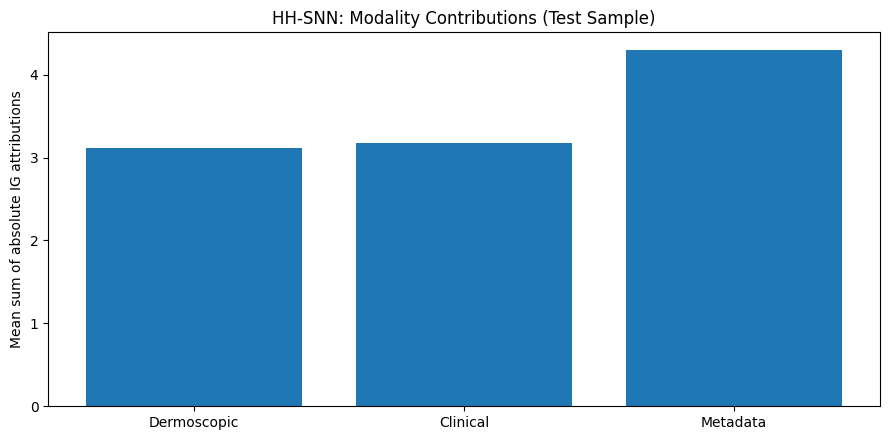

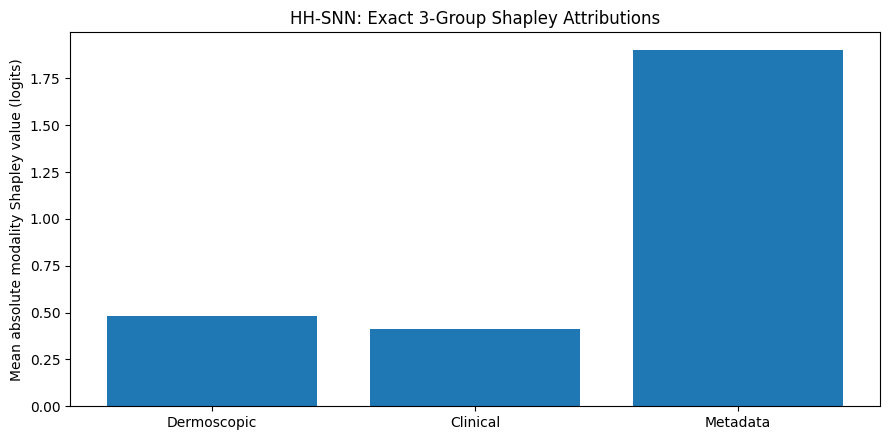

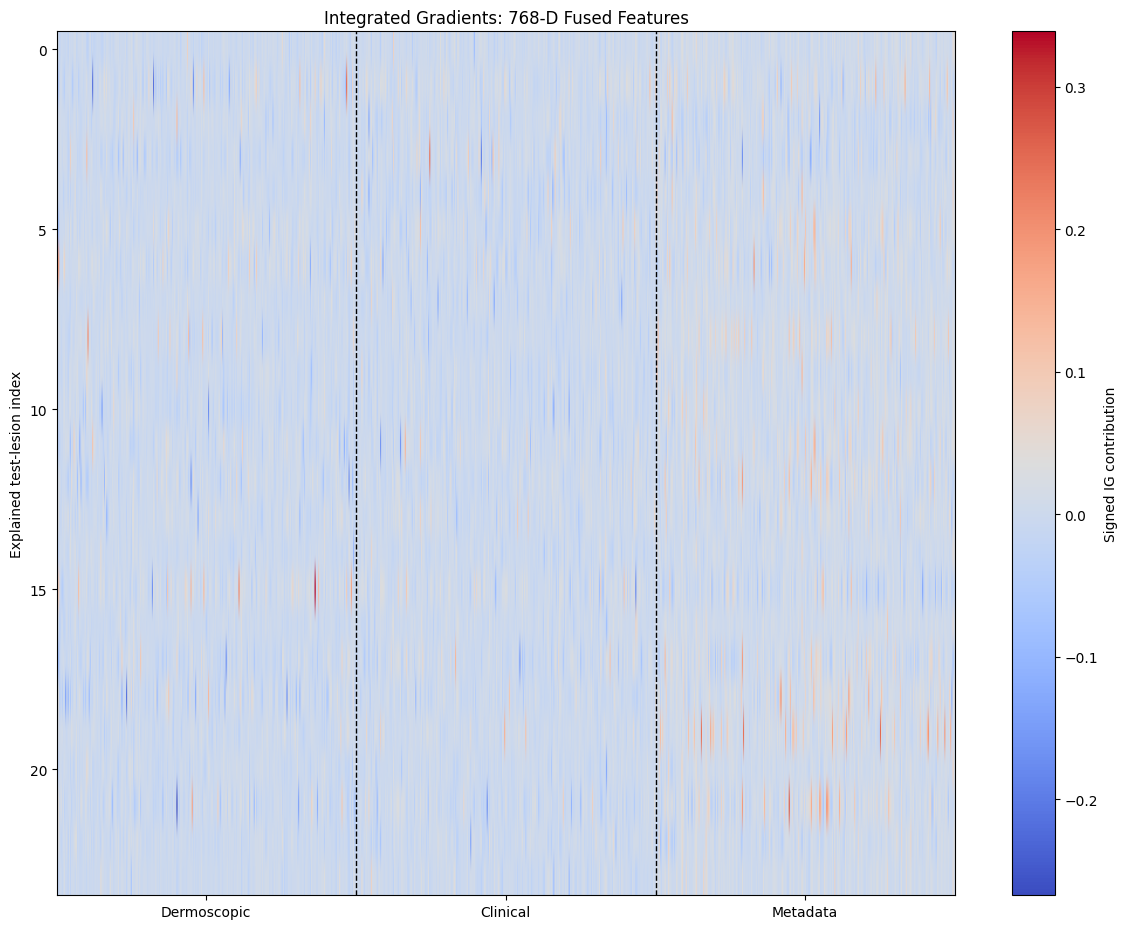

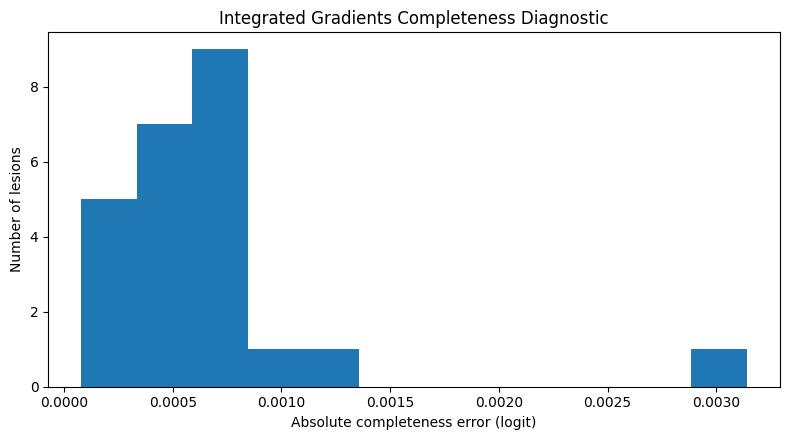


STEP 8 COMPLETED — Integrated Gradients + 3-group Shapley
Explained samples: 24
Mean IG completeness error: 0.000678981343905131
Output: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step8_HHSNN_Explainability
Grad-CAM: not available with the separately trained encoders and HH classifier.


In [3]:
# ================================================================
# DERM7PT STEP 8 — EXPLAINABILITY OF TRAINED HH-DYNAMICS CLASSIFIER
# Actual Integrated Gradients (IG) on 768-D learned-fusion inputs
# Exact 3-group interventional Shapley values (SHAP-style) over
# Dermoscopic / Clinical / Metadata 256-D fusion segments.
# NO Grad-CAM claimed: standalone frozen image encoders are NOT
# connected end-to-end to this HH classifier in Steps 4–6.
# ================================================================
# Colab dependencies: %pip -q install torch pandas numpy matplotlib scikit-learn joblib

import os, json, copy, itertools, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import joblib

SEED = 42
MAX_TEST_EXPLANATIONS = 24  # increase for more samples
IG_STEPS = 32               # increase to 64/128 for convergence checks
BATCH_SIZE = 16
CLASSES = ('Nevus', 'Melanoma', 'MISC', 'SK', 'BCC')
GROUPS = {'Dermoscopic': slice(0, 256),
          'Clinical': slice(256, 512),
          'Metadata': slice(512, 768)}
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

def get_base():
    for prefix in ('/content/drive', '/content/gdrive'):
        root = Path(prefix) / 'MyDrive' / 'Derm7pt'
        if root.is_dir(): return root
    from google.colab import drive
    for prefix in ('/content/drive', '/content/gdrive'):
        mount = Path(prefix)
        mount.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(mount)) and not any(mount.iterdir()):
            drive.mount(str(mount), force_remount=False)
        root = mount / 'MyDrive' / 'Derm7pt'
        if root.is_dir(): return root
    raise FileNotFoundError('MyDrive/Derm7pt not found. Mount Google Drive first.')

BASE = get_base()
PREP = BASE / 'Derm7pt_Preprocessed'
STEP5 = PREP / 'Step5_Full_768D_Learned_Fusion'
STEP6 = PREP / 'Step6_Full_FiveClass_HHSNN'
OUT = PREP / 'Step8_HHSNN_Explainability'
REPORT = OUT / 'Reports'; VIS = OUT / 'Visualizations'
for p in (REPORT, VIS): p.mkdir(parents=True, exist_ok=True)

# ------ Reproduce the Step 6 inference architecture exactly -----
class HHMembrane(nn.Module):
    def __init__(self, steps=20, dt=0.05):
        super().__init__()
        self.steps, self.dt = int(steps), float(dt)
        self.g_na, self.g_k, self.g_l = 120.0, 36.0, 0.3
        self.e_na, self.e_k, self.e_l = 50.0, -77.0, -54.387

    @staticmethod
    def vtrap(x, scale):
        z = (x / scale).clamp(-30, 30)
        denominator = torch.where(torch.abs(z) < 1e-4,
                                  torch.ones_like(z), -torch.expm1(-z))
        return torch.where(torch.abs(z) < 1e-4,
                           scale * (1 + z/2 + z*z/12), x / denominator)

    def forward(self, current):
        v = torch.full_like(current, -65.0)
        m = torch.full_like(current, 0.0529)
        h = torch.full_like(current, 0.5961)
        n = torch.full_like(current, 0.3177)
        voltage_integral = torch.zeros_like(current)
        spike_proxy = torch.zeros_like(current)
        for _ in range(self.steps):
            am = 0.1 * self.vtrap(v + 40.0, 10.0)
            bm = 4.0 * torch.exp((-(v + 65.0) / 18.0).clamp(-30, 30))
            ah = 0.07 * torch.exp((-(v + 65.0) / 20.0).clamp(-30, 30))
            bh = torch.sigmoid((v + 35.0) / 10.0)
            an = 0.01 * self.vtrap(v + 55.0, 10.0)
            bn = 0.125 * torch.exp((-(v + 65.0) / 80.0).clamp(-30, 30))
            m = torch.clamp(m + self.dt * (am * (1 - m) - bm * m), 0, 1)
            h = torch.clamp(h + self.dt * (ah * (1 - h) - bh * h), 0, 1)
            n = torch.clamp(n + self.dt * (an * (1 - n) - bn * n), 0, 1)
            ion_na = self.g_na * (m ** 3) * h * (v - self.e_na)
            ion_k = self.g_k * (n ** 4) * (v - self.e_k)
            ion_l = self.g_l * (v - self.e_l)
            v = torch.clamp(v + self.dt * (current - ion_na - ion_k - ion_l), -100, 80)
            voltage_integral = voltage_integral + (v + 65.0) / 100.0
            spike_proxy = spike_proxy + torch.sigmoid((v + 20.0) / 5.0)
        return torch.cat([voltage_integral / self.steps,
                          spike_proxy / self.steps], dim=1)

class HHDynamicsClassifier(nn.Module):
    def __init__(self, in_dim=768, neurons=256, n_classes=5, steps=20, dt=0.05,
                 dropout=0.2):
        super().__init__()
        self.input_projection = nn.Linear(in_dim, neurons)
        self.membrane = HHMembrane(steps=steps, dt=dt)
        self.classifier = nn.Sequential(
            nn.LayerNorm(neurons * 2),
            nn.Linear(neurons * 2, 128), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(128, n_classes))

    def forward(self, x):
        current = 12.0 + 18.0 * torch.tanh(self.input_projection(x))
        return self.classifier(self.membrane(current))

ckpt_path = STEP6 / 'Models' / 'Best_HH_Dynamics_Classifier.pt'
scaler_path = STEP6 / 'Models' / 'HH_TrainOnly_Scaler.joblib'
for p in (ckpt_path, scaler_path):
    if not p.is_file(): raise FileNotFoundError(f'Run full Step 6 first: {p}')
try:
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=True)
except TypeError:
    ckpt = torch.load(ckpt_path, map_location='cpu')
if tuple(ckpt['classes']) != CLASSES:
    raise ValueError(f'Step 6 class order unexpected: {ckpt["classes"]}')
model = HHDynamicsClassifier(
    in_dim=int(ckpt.get('input_dim', 768)),
    neurons=int(ckpt.get('neurons', 256)),
    n_classes=len(CLASSES),
    steps=int(ckpt.get('time_steps', 20)),
    dt=float(ckpt.get('dt_ms', 0.05))).to(DEVICE)
model.load_state_dict(ckpt['state_dict'], strict=True)
model.eval()
transform = joblib.load(scaler_path)
scaler = transform['scaler']
cols = list(transform.get('columns', [f'Fusion_{i:03d}' for i in range(768)]))
if len(cols) != 768: raise ValueError('Step 6 scaler needs 768 ordered features')

# ------ Load fused features; ensure saved predictions still match --
def load_split(split):
    f = STEP5 / f'{split}_Fused_768D.csv'
    p = STEP6 / 'Reports' / f'{split}_Predictions.csv'
    if not f.is_file() or not p.is_file():
        raise FileNotFoundError(f'Missing Step 5 features or Step 6 predictions for {split}')
    a = pd.read_csv(f, dtype={'Lesion_ID': str})
    b = pd.read_csv(p, dtype={'Lesion_ID': str})
    for d in (a, b):
        d['Lesion_ID'] = d['Lesion_ID'].astype(str).str.strip()
        if d['Lesion_ID'].duplicated().any(): raise ValueError(f'{split}: duplicate Lesion_ID')
    if set(a.Lesion_ID) != set(b.Lesion_ID):
        raise ValueError(f'{split}: Step 5 and Step 6 lesion sets differ')
    b = b.set_index('Lesion_ID').loc[a.Lesion_ID].reset_index()
    if not (a.Diagnosis.to_numpy() == b.Diagnosis.to_numpy()).all():
        raise ValueError(f'{split}: Step 5/6 diagnosis disagreement')
    values = a[cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float32)
    if not np.isfinite(values).all(): raise ValueError(f'{split}: invalid features')
    X = scaler.transform(values).astype(np.float32)
    if not np.isfinite(X).all(): raise ValueError(f'{split}: bad scaled features')
    return a, b, X

train_df, train_predictions, train_X = load_split('Train')
test_df, test_predictions, test_X = load_split('Test')
if len(test_X) == 0: raise ValueError('Empty test split')
indices = np.linspace(0, len(test_X)-1,
                      min(MAX_TEST_EXPLANATIONS, len(test_X)), dtype=int)
indices = np.unique(indices)
X = test_X[indices]
selected = test_predictions.iloc[indices].reset_index(drop=True)
print('Explaining test lesions:', len(indices), 'of', len(test_X))

@torch.no_grad()
def probabilities(x, batch_size=64):
    out=[]
    for i in range(0,len(x),batch_size):
        z=torch.from_numpy(np.asarray(x[i:i+batch_size],dtype=np.float32)).to(DEVICE)
        out.append(model(z).softmax(-1).cpu().numpy())
    return np.vstack(out)

p_now = probabilities(X)
p_saved = selected[[f'Probability_{c}' for c in CLASSES]].to_numpy(dtype=float)
if not np.allclose(p_now, p_saved, rtol=2e-3, atol=2e-3):
    raise RuntimeError('Reloaded HH model does NOT reproduce saved Step 6 probabilities. '
                       'Do not explain a mismatched checkpoint.')

# ------ IG for each lesion's predicted diagnosis logit ------------
# Baseline: training mean in the same standardized 768-D feature space.
# IG is computed on logits, not probabilities (reduces softmax saturation).
baseline = train_X.mean(axis=0).astype(np.float32)

def integrated_gradients(x, target, base, steps=32):
    x_t = torch.as_tensor(x, device=DEVICE, dtype=torch.float32)
    base_t = torch.as_tensor(base, device=DEVICE, dtype=torch.float32)
    delta = x_t - base_t
    accumulated = torch.zeros_like(x_t)
    for step in range(steps + 1):
        alpha = step / steps
        z = (base_t + alpha * delta).detach().requires_grad_(True)
        logits = model(z.unsqueeze(0))
        grad = torch.autograd.grad(logits[0, target], z)[0]
        factor = 0.5 if step in (0, steps) else 1.0
        accumulated = accumulated + factor * grad.detach()
    return (delta * accumulated / steps).cpu().numpy()

all_ig=[]; details=[]
for i, (lesion, prob) in enumerate(zip(X, p_now)):
    target = int(np.argmax(prob))
    attr = integrated_gradients(lesion, target, baseline, IG_STEPS)
    all_ig.append(attr)
    with torch.no_grad():
        f_x = model(torch.as_tensor(lesion[None],device=DEVICE)).cpu().numpy()[0,target]
        f_b = model(torch.as_tensor(baseline[None],device=DEVICE)).cpu().numpy()[0,target]
    details.append({'Lesion_ID':selected.loc[i,'Lesion_ID'],
                    'Actual_Diagnosis':selected.loc[i,'Diagnosis'],
                    'Predicted_Diagnosis':CLASSES[target],
                    'Predicted_Confidence':float(prob[target]),
                    'IG_Logit_Difference':float(f_x-f_b),
                    'IG_Attribution_Sum':float(attr.sum()),
                    'IG_Completeness_Error':float(abs((f_x-f_b)-attr.sum()))})
IG = np.asarray(all_ig,dtype=np.float32)
ig_table = pd.DataFrame(IG,columns=cols)
ig_table.insert(0,'Lesion_ID',selected.Lesion_ID.to_numpy())
ig_table.to_csv(REPORT/'Test_Integrated_Gradients_768D.csv',index=False)

# ------ Exact SHAP-style Shapley values for 3 modality groups ------
# All 8 coalitions, averaged over the 6 permutations. The masked
# modality is replaced with its TRAIN mean. Target is predicted-class
# LOGIT (not probability). Values sum to model(x)-model(baseline).
permutations = list(itertools.permutations(range(3)))
slices = list(GROUPS.values())
shap_rows=[]; ig_group_rows=[]
for i, lesion in enumerate(X):
    target = int(p_now[i].argmax())
    coalitions = list(itertools.product((0,1),repeat=3))
    masked = np.repeat(baseline[None,:],len(coalitions),axis=0)
    for k, coalition in enumerate(coalitions):
        for j, is_present in enumerate(coalition):
            if is_present: masked[k,slices[j]]=lesion[slices[j]]
    with torch.no_grad():
        logits = model(torch.as_tensor(masked,dtype=torch.float32,device=DEVICE))
        values = logits[:,target].cpu().numpy()
    lookup = {coalitions[k]:float(values[k]) for k in range(len(coalitions))}
    contrib=np.zeros(3,dtype=np.float64)
    for perm in permutations:
        coalition=[0,0,0]
        before = lookup[tuple(coalition)]
        for j in perm:
            coalition[j]=1
            after=lookup[tuple(coalition)]
            contrib[j] += after-before
            before=after
    contrib/=len(permutations)
    row={'Lesion_ID':selected.loc[i,'Lesion_ID'],
         'Actual_Diagnosis':selected.loc[i,'Diagnosis'],
         'Predicted_Diagnosis':CLASSES[target],
         'Reference_Baseline_Logit':lookup[(0,0,0)],
         'Full_Input_Logit':lookup[(1,1,1)],
         'SHAP_Completeness_Error':float(abs(contrib.sum()-(lookup[(1,1,1)]-lookup[(0,0,0)])))}
    grow={'Lesion_ID':selected.loc[i,'Lesion_ID']}
    for j, name in enumerate(GROUPS):
        row[f'Shapley_{name}']=float(contrib[j])
        grow[f'IG_{name}_Signed']=float(IG[i,slices[j]].sum())
        grow[f'IG_{name}_Absolute']=float(np.abs(IG[i,slices[j]]).sum())
    shap_rows.append(row); ig_group_rows.append(grow)

pd.DataFrame(shap_rows).to_csv(REPORT/'Test_Modality_Group_Shapley.csv',index=False)
pd.DataFrame(ig_group_rows).to_csv(REPORT/'Test_Modality_IG_Summary.csv',index=False)
pd.DataFrame(details).to_csv(REPORT/'Test_IG_Completeness_Audit.csv',index=False)

# ------ Visualization ---------------------------------------------
fig,ax=plt.subplots(figsize=(9,4.5))
means=[np.abs(IG[:, sl]).sum(axis=1).mean() for sl in GROUPS.values()]
ax.bar(list(GROUPS.keys()),means)
ax.set(ylabel='Mean sum of absolute IG attributions',
       title='HH-SNN: Modality Contributions (Test Sample)')
fig.tight_layout();fig.savefig(VIS/'Modality_IG_Importance.png',dpi=170)
plt.show();plt.close(fig)

sh=pd.DataFrame(shap_rows)
fig,ax=plt.subplots(figsize=(9,4.5))
means=[np.abs(sh[f'Shapley_{name}']).mean() for name in GROUPS]
ax.bar(list(GROUPS),means)
ax.set(ylabel='Mean absolute modality Shapley value (logits)',
       title='HH-SNN: Exact 3-Group Shapley Attributions')
fig.tight_layout();fig.savefig(VIS/'Modality_Shapley_Importance.png',dpi=170)
plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(12,max(3.5,min(len(IG)*0.35+1,10))))
heat=ax.imshow(IG,aspect='auto',cmap='coolwarm')
ax.axvline(255.5,linestyle='--',color='black',linewidth=1)
ax.axvline(511.5,linestyle='--',color='black',linewidth=1)
ax.set_xticks([127,383,639],['Dermoscopic','Clinical','Metadata'])
ax.set(ylabel='Explained test-lesion index',title='Integrated Gradients: 768-D Fused Features')
fig.colorbar(heat,ax=ax,label='Signed IG contribution')
fig.tight_layout();fig.savefig(VIS/'Test_IG_Heatmap.png',dpi=170)
plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(8,4.5))
ax.hist(pd.DataFrame(details)['IG_Completeness_Error'].to_numpy(),bins=12)
ax.set(xlabel='Absolute completeness error (logit)',ylabel='Number of lesions',
       title='Integrated Gradients Completeness Diagnostic')
fig.tight_layout();fig.savefig(VIS/'IG_Completeness_Diagnostic.png',dpi=170)
plt.show();plt.close(fig)

summary={
    'model':'Step 6 frozen HH-dynamics-inspired 5-class classifier',
    'explanation_split':'Test',
    'test_total':int(len(test_X)),
    'test_explained':int(len(X)),
    'sample_selection':'Evenly spaced indices in existing test file (not all test lesions unless count permits)',
    'ig_steps':IG_STEPS,
    'ig_target':'Predicted class logit',
    'ig_baseline':'Training mean of 768-D inputs after Step 6 training-only scaler',
    'shap_method':'Exact interventional three-group Shapley over 8 modality coalitions; training-mean masking',
    'shap_target':'Predicted class logit',
    'group_order':['Dermoscopic 0:256','Clinical 256:512','Metadata 512:768'],
    'gradcam':'NOT GENERATED — image encoders are frozen and not linked differentiably to HH-SNN classifier; needs an integrated image-to-prediction graph',
    'mean_ig_completeness_error':float(np.mean([r['IG_Completeness_Error'] for r in details])),
    'max_group_shapley_completeness_error':float(np.max([r['SHAP_Completeness_Error'] for r in shap_rows])),
    'notes':[
        'These explanations operate on learned fusion coordinates, not lesion pixels.',
        'Signed IG and group Shapley contributions are for predicted-class logits.',
        'Correlated modalities and training-mean masking limit causal interpretation.',
        'The HH model is an HH-dynamics-inspired surrogate, not an exact paper replication.',
        'Explanations describe model behavior and do not clinically validate diagnoses.']}
with open(REPORT/'Step8_Explainability_Summary.json','w') as f:
    json.dump(summary,f,indent=2)
print('\nSTEP 8 COMPLETED — Integrated Gradients + 3-group Shapley')
print('Explained samples:',len(X))
print('Mean IG completeness error:',summary['mean_ig_completeness_error'])
print('Output:',OUT)
print('Grad-CAM: not available with the separately trained encoders and HH classifier.')


Device: cuda
Train (707, 768) {'Nevus': 393, 'Melanoma': 185, 'MISC': 65, 'SK': 35, 'BCC': 29}
Validation (152, 768) {'Nevus': 95, 'Melanoma': 34, 'MISC': 12, 'BCC': 7, 'SK': 4}
Test (152, 768) {'Nevus': 87, 'Melanoma': 33, 'MISC': 20, 'SK': 6, 'BCC': 6}
HH Dermoscopic: best epoch 2, val_loss=1.3548
HH Clinical: best epoch 2, val_loss=1.3515
HH Metadata: best epoch 7, val_loss=0.7415
HH Dermoscopic+Clinical: best epoch 2, val_loss=1.2210
HH Dermoscopic+Metadata: best epoch 2, val_loss=0.7805
HH Clinical+Metadata: best epoch 3, val_loss=0.6367
HH All_Three: best epoch 3, val_loss=0.7348
Baseline LogisticRegression completed
Baseline RandomForest completed
Baseline HistGradientBoosting completed


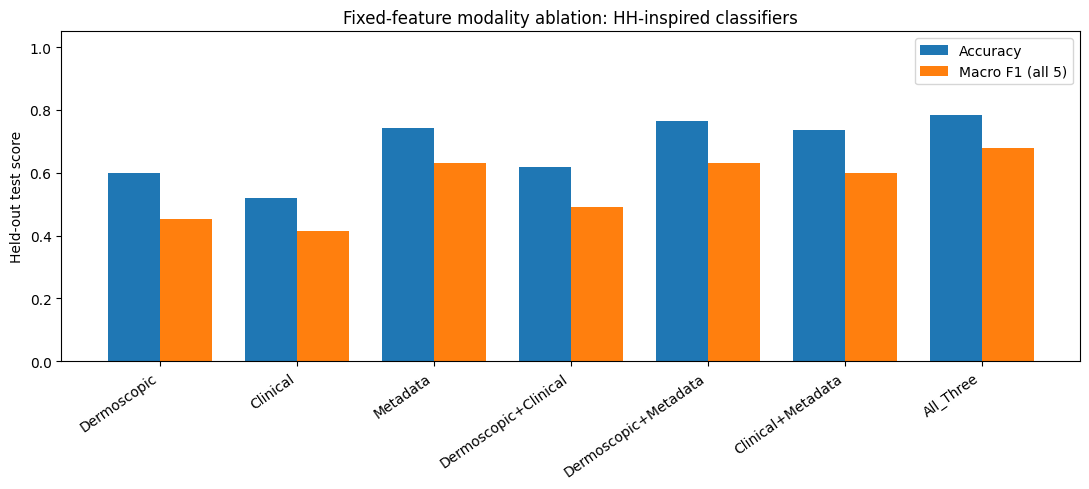

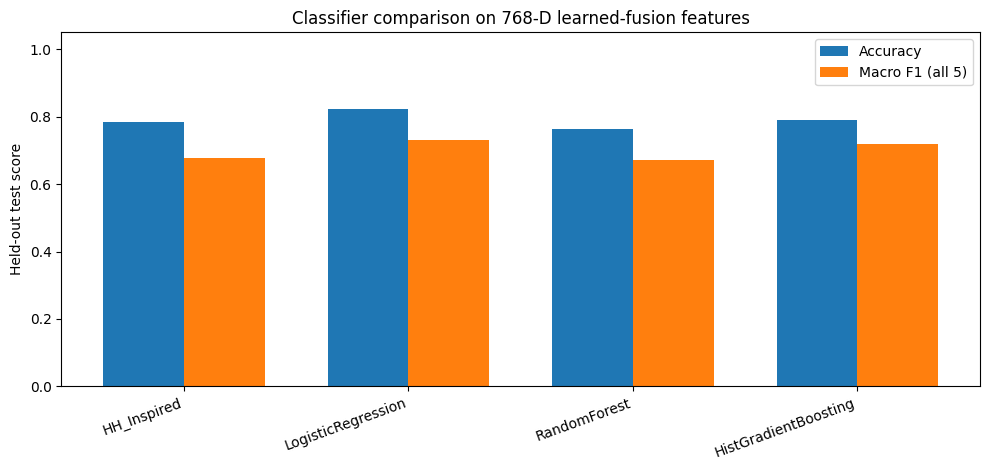


STEP 9 COMPLETED
               Model              Variant  Accuracy  Macro_F1_5class  Macro_OVR_AUC_All5
         HH_Inspired          Dermoscopic  0.598684         0.453160            0.793050
         HH_Inspired             Clinical  0.519737         0.414299            0.765862
         HH_Inspired             Metadata  0.743421         0.632434            0.921003
         HH_Inspired Dermoscopic+Clinical  0.618421         0.489917            0.831783
         HH_Inspired Dermoscopic+Metadata  0.763158         0.629441            0.936774
         HH_Inspired    Clinical+Metadata  0.736842         0.598903            0.937477
         HH_Inspired            All_Three  0.782895         0.677871            0.944723
  LogisticRegression            All_Three  0.822368         0.730111            0.939964
        RandomForest            All_Three  0.763158         0.671611            0.942040
HistGradientBoosting            All_Three  0.789474         0.718790            0.948113
Val

In [4]:
# ================================================================
# DERM7PT STEP 9 — FULL-DATA FIXED-REPRESENTATION ABLATION
# + HH-dynamics-inspired classifier vs conventional baselines
# ================================================================
# Colab: %pip -q install numpy pandas matplotlib scikit-learn torch joblib
# Uses same data splits and learned 768-D projections as Steps 5–8.
# Each modality gets 256 coordinates in the order Derm, Clinical, Metadata.
# CAVEAT: Step 5 projections were jointly trained with all modalities.
# Therefore this is a *fixed-representation* ablation; NOT an end-to-end
# retraining of modality encoders and supervised 256-D projection heads.
# The HH membrane is an HH-inspired differentiable approximation.
# ================================================================

import os, json, random, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
     precision_recall_fscore_support, confusion_matrix, roc_auc_score)
import joblib

SEED = 42
EPOCHS = 65
PATIENCE = 10
BATCH_SIZE = 32
LR = 3e-4
WEIGHT_DECAY = 1e-4
TIME_STEPS = 20
DT_MS = 0.05
NEURONS = 256
DROPOUT = .20
# Change to False to train one full HH model plus conventional baselines only.
RUN_ALL_ABLATIONS = True
# Ablation models each have individually trained input and classification heads.
# Set True if you want confusion matrices for every ablation.
SAVE_EACH_CONFUSION_MATRIX = True
CLASSES = ('Nevus','Melanoma','MISC','SK','BCC')
SPLITS = ('Train','Validation','Test')
GROUPS = {'Dermoscopic':(0,256), 'Clinical':(256,512), 'Metadata':(512,768)}
ABLATIONS = {
  'Dermoscopic':('Dermoscopic',),
  'Clinical':('Clinical',),
  'Metadata':('Metadata',),
  'Dermoscopic+Clinical':('Dermoscopic','Clinical'),
  'Dermoscopic+Metadata':('Dermoscopic','Metadata'),
  'Clinical+Metadata':('Clinical','Metadata'),
  'All_Three':('Dermoscopic','Clinical','Metadata')
}

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

# ---------------------- Resolve Drive ---------------------------
def find_project():
    for mount in ('/content/drive','/content/gdrive'):
        p=Path(mount)/'MyDrive'/'Derm7pt'
        if p.is_dir(): return p
    from google.colab import drive
    for mount in ('/content/drive','/content/gdrive'):
        m=Path(mount)
        m.mkdir(parents=True,exist_ok=True)
        if not os.path.ismount(str(m)) and not any(m.iterdir()):
            drive.mount(str(m),force_remount=False)
        p=m/'MyDrive'/'Derm7pt'
        if p.is_dir(): return p
    raise FileNotFoundError('MyDrive/Derm7pt not found. Mount Google Drive.')

BASE=find_project()
PREP=BASE/'Derm7pt_Preprocessed'
SOURCE=PREP/'Step5_Full_768D_Learned_Fusion'
OUT=PREP/'Step9_FixedFeature_Ablation_Comparison'
MODELS=OUT/'Models'; REPORT=OUT/'Reports'; VIS=OUT/'Visualizations'
for d in (MODELS,REPORT,VIS): d.mkdir(parents=True,exist_ok=True)

# ---------------------- Read & validate features ----------------
FEATURE_COLS=[f'Fusion_{j:03d}' for j in range(768)]
label_to_idx={c:i for i,c in enumerate(CLASSES)}
arrays={}; labels={}; frames={}; ids={}
for split in SPLITS:
    filename=SOURCE/f'{split}_Fused_768D.csv'
    if not filename.is_file():
        raise FileNotFoundError(f'Missing full Step 5 features: {filename}')
    df=pd.read_csv(filename,dtype={'Lesion_ID':str},low_memory=False)
    required={'Lesion_ID','Diagnosis','Split',*FEATURE_COLS}
    missing=required-set(df.columns)
    if missing:raise ValueError(f'{split} missing columns: {sorted(missing)[:12]}')
    if len(df)==0 or df.Lesion_ID.isna().any():raise ValueError(f'{split} has blank records/IDs')
    df['Lesion_ID']=df.Lesion_ID.astype(str).str.strip().str.replace(r'(?<=\d)\.0$', '',regex=True)
    if df.Lesion_ID.eq('').any() or df.Lesion_ID.duplicated().any():
        raise ValueError(f'{split}: blank/duplicated lesion IDs')
    if not df.Split.astype(str).eq(split).all():raise ValueError(f'{split}: mismatched Split column')
    if df.Diagnosis.isna().any() or not set(df.Diagnosis).issubset(CLASSES):
        raise ValueError(f'{split}: missing or unknown labels')
    a=df[FEATURE_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float32)
    if not np.isfinite(a).all():raise ValueError(f'{split} has nonfinite features')
    arrays[split]=a
    labels[split]=df.Diagnosis.map(label_to_idx).to_numpy(dtype=np.int64)
    ids[split]=set(df.Lesion_ID)
    frames[split]=df[['Lesion_ID','Diagnosis','Split']].copy()
    print(split, a.shape, df.Diagnosis.value_counts().to_dict())
for i,a in enumerate(SPLITS):
    for b in SPLITS[i+1:]:
        shared=ids[a]&ids[b]
        if shared:raise ValueError(f'Lesion leakage {a}/{b}: {sorted(shared)[:10]}')
missing_train=sorted(set(range(5))-set(labels['Train']))
if missing_train:raise ValueError('Training missing diagnoses: '+str([CLASSES[j] for j in missing_train]))
if len(labels['Validation']) < 2 or len(labels['Test']) < 2:
    raise ValueError('At least two validation/test records required')

# ---------------------- General metric conventions --------------
def evaluate(y_true,prob):
    pred=np.asarray(prob).argmax(1)
    precision,recall,f1,support=precision_recall_fscore_support(
        y_true,pred,labels=np.arange(5),zero_division=0)
    aucs=[]
    for j in range(5):
        binary=(y_true==j).astype(int)
        aucs.append(float(roc_auc_score(binary,prob[:,j])) if len(np.unique(binary))==2 else np.nan)
    return {
        'Samples':int(len(y_true)),
        'Classes_In_Truth':int(len(np.unique(y_true))),
        'Accuracy':float(accuracy_score(y_true,pred)),
        'Balanced_Accuracy_Present':float(balanced_accuracy_score(y_true,pred)),
        'Macro_Precision_5class':float(np.mean(precision)),
        'Macro_Recall_5class':float(np.mean(recall)),
        'Macro_F1_5class':float(np.mean(f1)),
        'Weighted_F1':float(np.average(f1,weights=support)),
        'Macro_OVR_AUC_All5':float(np.mean(aucs)) if np.isfinite(aucs).all() else np.nan
    }

def subset_indices(names):
    return np.concatenate([np.arange(*GROUPS[n]) for n in names])

# ---------------------- HH-style module (matches Step 6) --------
class HHMembrane(nn.Module):
    def __init__(self,steps=20,dt=.05):
        super().__init__()
        self.steps,self.dt=int(steps),float(dt)
        self.g_na,self.g_k,self.g_l=120.,36.,.3
        self.e_na,self.e_k,self.e_l=50.,-77.,-54.387
    @staticmethod
    def vtrap(x,scale):
        z=(x/scale).clamp(-30,30)
        den=torch.where(torch.abs(z)<1e-4,torch.ones_like(z),-torch.expm1(-z))
        return torch.where(torch.abs(z)<1e-4,scale*(1+z/2+z*z/12),x/den)
    def forward(self,current):
        v=torch.full_like(current,-65.)
        m=torch.full_like(current,.0529)
        h=torch.full_like(current,.5961)
        n=torch.full_like(current,.3177)
        integ=torch.zeros_like(current)
        surrogate=torch.zeros_like(current)
        for _ in range(self.steps):
            am=.1*self.vtrap(v+40,10)
            bm=4*torch.exp((-(v+65)/18).clamp(-30,30))
            ah=.07*torch.exp((-(v+65)/20).clamp(-30,30))
            bh=torch.sigmoid((v+35)/10)
            an=.01*self.vtrap(v+55,10)
            bn=.125*torch.exp((-(v+65)/80).clamp(-30,30))
            m=torch.clamp(m+self.dt*(am*(1-m)-bm*m),0,1)
            h=torch.clamp(h+self.dt*(ah*(1-h)-bh*h),0,1)
            n=torch.clamp(n+self.dt*(an*(1-n)-bn*n),0,1)
            ina=self.g_na*m**3*h*(v-self.e_na)
            ik=self.g_k*n**4*(v-self.e_k)
            il=self.g_l*(v-self.e_l)
            v=torch.clamp(v+self.dt*(current-ina-ik-il),-100,80)
            integ=integ+(v+65)/100
            surrogate=surrogate+torch.sigmoid((v+20)/5)
        return torch.cat([integ/self.steps,surrogate/self.steps],dim=1)

class HHDynamicsClassifier(nn.Module):
    def __init__(self,input_dim):
        super().__init__()
        self.input_projection=nn.Linear(input_dim,NEURONS)
        self.membrane=HHMembrane(TIME_STEPS,DT_MS)
        self.classifier=nn.Sequential(nn.LayerNorm(NEURONS*2),
                nn.Linear(NEURONS*2,128),nn.GELU(),nn.Dropout(DROPOUT),nn.Linear(128,5))
    def forward(self,x):
        cur=12.+18.*torch.tanh(self.input_projection(x))
        return self.classifier(self.membrane(cur))

# ---------------------- Single HH experiment --------------------
def hh_train(name,group_names):
    # IMPORTANT: all preprocessing fit on Train, not Validation/Test.
    ix=subset_indices(group_names)
    scalar=StandardScaler().fit(arrays['Train'][:,ix])
    x={s:scalar.transform(arrays[s][:,ix]).astype(np.float32) for s in SPLITS}
    if any(not np.isfinite(a).all() for a in x.values()):
        raise ValueError(f'Nonfinite standardized features for {name}')
    joblib.dump(scalar,MODELS/f'{name}_Scaler.joblib')
    def loader(split,shuffle=False):
        return DataLoader(TensorDataset(torch.tensor(x[split]),torch.tensor(labels[split])),
                          batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)
    tr=loader('Train',True); va=loader('Validation')
    model=HHDynamicsClassifier(input_dim=len(ix)).to(DEVICE)
    counts=np.bincount(labels['Train'],minlength=5)
    weight=len(labels['Train'])/(5*counts)
    loss_fn=nn.CrossEntropyLoss(weight=torch.as_tensor(weight,dtype=torch.float32,device=DEVICE))
    opt=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=.5,patience=4)
    history=[];best_loss=np.inf;best_epoch=0;stagnant=0;best_state=None
    for epoch in range(1,EPOCHS+1):
        for training,dl in ((True,tr),(False,va)):
            model.train(training)
            running=0.; hits=0; total=0
            for features,target in dl:
                features=features.to(DEVICE);target=target.to(DEVICE)
                if training:opt.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(training):
                    logits=model(features)
                    loss=loss_fn(logits,target)
                    if training:
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model.parameters(),2.)
                        opt.step()
                running+=float(loss.item())*len(target)
                hits+=int((logits.argmax(1)==target).sum().item())
                total+=len(target)
            if training:
                tl,ta=running/total,hits/total
            else:
                vl,vaa=running/total,hits/total
        if not np.isfinite([tl,ta,vl,vaa]).all():
            raise RuntimeError(f'{name}: nonfinite training result')
        history.append({'Epoch':epoch,'Train_Loss':tl,'Train_Accuracy':ta,
                        'Validation_Loss':vl,'Validation_Accuracy':vaa})
        sched.step(vl)
        if vl<best_loss-1e-5:
            best_loss,best_epoch,stagnant=vl,epoch,0
            best_state=copy.deepcopy(model.state_dict())
        else:
            stagnant+=1
            if stagnant>=PATIENCE: break
    model.load_state_dict(best_state);model.eval()
    torch.save({'state_dict':best_state,'classes':CLASSES,'groups':list(group_names),
                'indices':ix.tolist(),'input_dim':len(ix),'neurons':NEURONS,
                'time_steps':TIME_STEPS,'dt_ms':DT_MS,'best_epoch':best_epoch},
                MODELS/f'{name}_Best_HH.pt')
    pd.DataFrame(history).to_csv(REPORT/f'{name}_Training_Log.csv',index=False)
    print(f'HH {name}: best epoch {best_epoch}, val_loss={best_loss:.4f}')
    with torch.no_grad():
        for split in SPLITS:
            probs=[]
            dl=loader(split)
            for xb,_ in dl:
                probs.append(torch.softmax(model(xb.to(DEVICE)),dim=1).cpu().numpy())
            probs=np.concatenate(probs)
            pred=probs.argmax(1)
            output=frames[split].copy()
            output['Predicted_Diagnosis']=[CLASSES[i] for i in pred]
            for j,c in enumerate(CLASSES):output[f'Probability_{c}']=probs[:,j]
            output.to_csv(REPORT/f'{name}_{split}_Predictions.csv',index=False)
            met=evaluate(labels[split],probs)
            met.update({'Model':'HH_Inspired','Variant':name,'Split':split,
                        'Input_Dim':len(ix),'Best_Epoch':best_epoch})
            results.append(met)
            if split=='Test' and SAVE_EACH_CONFUSION_MATRIX:
                cm=confusion_matrix(labels[split],pred,labels=np.arange(5))
                pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(REPORT/f'{name}_Test_CM.csv')
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()

# ---------------------- HH ablations ----------------------------
results=[]
variants=ABLATIONS if RUN_ALL_ABLATIONS else {'All_Three':ABLATIONS['All_Three']}
for variant,group_names in variants.items():
    hh_train(variant,group_names)

# ---------------------- Standard baselines on all 768 features --
# These are separately fitted on training data only.
sc=StandardScaler().fit(arrays['Train'])
xtr=sc.transform(arrays['Train']).astype(np.float32)
xva=sc.transform(arrays['Validation']).astype(np.float32)
xts=sc.transform(arrays['Test']).astype(np.float32)
joblib.dump(sc,MODELS/'Baseline_768D_Scaler.joblib')
models={
 'LogisticRegression':LogisticRegression(max_iter=3000,class_weight='balanced',random_state=SEED),
 'RandomForest':RandomForestClassifier(n_estimators=300,class_weight='balanced_subsample',
                                       random_state=SEED,n_jobs=-1),
 'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=150,learning_rate=.06,
                                       random_state=SEED,early_stopping=False)
}
for name,clf in models.items():
    clf.fit(xtr,labels['Train'])
    # Guard class order in probability outputs.
    if set(clf.classes_) != set(range(5)):
        raise ValueError(f'{name} did not learn all five classes')
    for split,x in zip(SPLITS,(xtr,xva,xts)):
        prob_small=clf.predict_proba(x)
        probs=np.zeros((len(x),5),dtype=np.float64)
        probs[:,clf.classes_.astype(int)]=prob_small
        pred=probs.argmax(1)
        output=frames[split].copy()
        output['Predicted_Diagnosis']=[CLASSES[i] for i in pred]
        for j,c in enumerate(CLASSES):output[f'Probability_{c}']=probs[:,j]
        output.to_csv(REPORT/f'{name}_{split}_Predictions.csv',index=False)
        met=evaluate(labels[split],probs)
        met.update({'Model':name,'Variant':'All_Three','Split':split,
                    'Input_Dim':768,'Best_Epoch':np.nan})
        results.append(met)
    joblib.dump(clf,MODELS/f'{name}.joblib')
    print('Baseline',name,'completed')

# ---------------------- Export comparisons & plots --------------
all_results=pd.DataFrame(results)
all_results.to_csv(REPORT/'Step9_All_Results.csv',index=False)
test=all_results.loc[all_results.Split.eq('Test')].copy()
test.to_csv(REPORT/'Step9_Test_Comparison.csv',index=False)
val=all_results.loc[all_results.Split.eq('Validation')].copy()
val.to_csv(REPORT/'Step9_Validation_Comparison.csv',index=False)

hh=test.loc[test.Model.eq('HH_Inspired')].copy()
fig,ax=plt.subplots(figsize=(11,5))
idx=np.arange(len(hh));wid=.38
ax.bar(idx-wid/2,hh.Accuracy,width=wid,label='Accuracy')
ax.bar(idx+wid/2,hh.Macro_F1_5class,width=wid,label='Macro F1 (all 5)')
ax.set_xticks(idx,hh.Variant,rotation=35,ha='right')
ax.set_ylim(0,1.05);ax.set_ylabel('Held-out test score')
ax.set_title('Fixed-feature modality ablation: HH-inspired classifiers')
ax.legend();fig.tight_layout();fig.savefig(VIS/'HH_Modality_Ablation.png',dpi=170)
plt.show();plt.close(fig)

full=test.loc[test.Variant.eq('All_Three')].copy()
fig,ax=plt.subplots(figsize=(10,4.8))
idx=np.arange(len(full))
ax.bar(idx-.18,full.Accuracy,width=.36,label='Accuracy')
ax.bar(idx+.18,full.Macro_F1_5class,width=.36,label='Macro F1 (all 5)')
ax.set_xticks(idx,full.Model,rotation=20,ha='right')
ax.set_ylim(0,1.05);ax.set_ylabel('Held-out test score')
ax.set_title('Classifier comparison on 768-D learned-fusion features')
ax.legend();fig.tight_layout();fig.savefig(VIS/'Full_Features_Model_Comparison.png',dpi=170)
plt.show();plt.close(fig)

# Select the next model based on validation only; never tune using Test.
chosen=val.sort_values(['Macro_F1_5class','Accuracy'],ascending=False).iloc[0]
summary={
  'input_source':str(SOURCE),'output_dir':str(OUT),'classes':list(CLASSES),
  'experiment':'Full-dataset fixed learned-fusion representation ablation and baseline comparison',
  'hh_implementation':'Differentiable HH-dynamics-inspired approximation, not exact PDF HH-SNN',
  'ablation_variants':{k:list(v) for k,v in variants.items()},
  'baselines':list(models),
  'model_selection':'Validation macro-F1; test not used for model selection',
  'validation_selected':{'Model':str(chosen.Model),'Variant':str(chosen.Variant),
                        'Validation_Macro_F1':float(chosen.Macro_F1_5class)},
  'train_size':len(labels['Train']),
  'validation_size':len(labels['Validation']),
  'test_size':len(labels['Test']),
  'limitations':[
    'Step 5 supervised projections were trained using all three modalities. This is NOT an end-to-end modality ablation.',
    'Reusing a joint projection model may advantage multimodal models over single-modal variants.',
    'An end-to-end ablation must refit Step 5 projections for each modality subset and re-train classifiers.',
    'Only one fixed original split was evaluated; repeated seeds and patient-grouped cross-validation would strengthen conclusions.',
    'All scores come from actual predictions. Macro-F1 uses all five classes; undefined AUC stays NaN.',
    'If patients contribute multiple lesions, verify no patient-level leakage separately.',
    'The full-data Step 4 frozen encoders are not exact research-paper hybrid encoders.'
  ]}
with open(REPORT/'Step9_Experiment_Audit.json','w') as f:json.dump(summary,f,indent=2)
print('\nSTEP 9 COMPLETED')
print(test[['Model','Variant','Accuracy','Macro_F1_5class','Macro_OVR_AUC_All5']].to_string(index=False))
print('Validation-selected configuration:',summary['validation_selected'])
print('Results:',REPORT)
print('Visualizations:',VIS)
print('NEXT: Repeated seeds / group-wise CV and true end-to-end ablation for research-grade validation.')


Device: cuda
Train (707, 768) {'Nevus': 393, 'Melanoma': 185, 'MISC': 65, 'SK': 35, 'BCC': 29}
Validation (152, 768) {'Nevus': 95, 'Melanoma': 34, 'MISC': 12, 'BCC': 7, 'SK': 4}
Test (152, 768) {'Nevus': 87, 'Melanoma': 33, 'MISC': 20, 'SK': 6, 'BCC': 6}

===== RUN 1/5 | Seed 42 =====
Best epoch: 3 | best val_loss=0.75612
Train: Accuracy=0.9406 MacroF1=0.9337
Validation: Accuracy=0.8158 MacroF1=0.7001
Test: Accuracy=0.7829 MacroF1=0.6826

===== RUN 2/5 | Seed 123 =====
Best epoch: 2 | best val_loss=0.73489
Train: Accuracy=0.8939 MacroF1=0.8665
Validation: Accuracy=0.8158 MacroF1=0.7174
Test: Accuracy=0.7500 MacroF1=0.6629

===== RUN 3/5 | Seed 2026 =====
Best epoch: 2 | best val_loss=0.75393
Train: Accuracy=0.8812 MacroF1=0.8543
Validation: Accuracy=0.7829 MacroF1=0.7030
Test: Accuracy=0.7368 MacroF1=0.6361

===== RUN 4/5 | Seed 31415 =====
Best epoch: 2 | best val_loss=0.70364
Train: Accuracy=0.8727 MacroF1=0.8444
Validation: Accuracy=0.7961 MacroF1=0.6968
Test: Accuracy=0.7500 MacroF

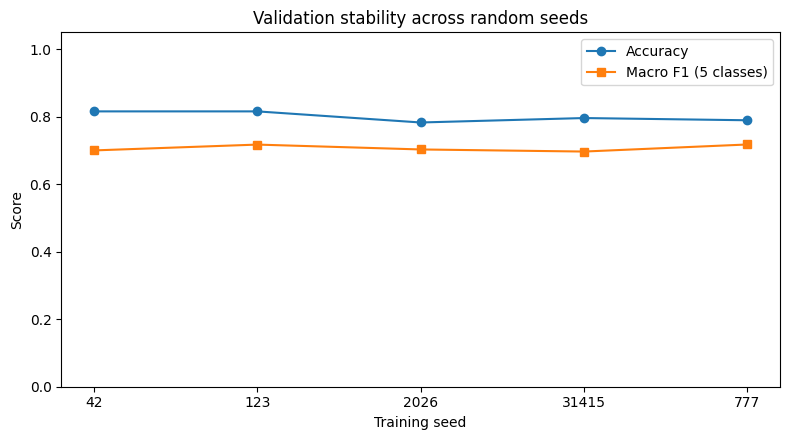

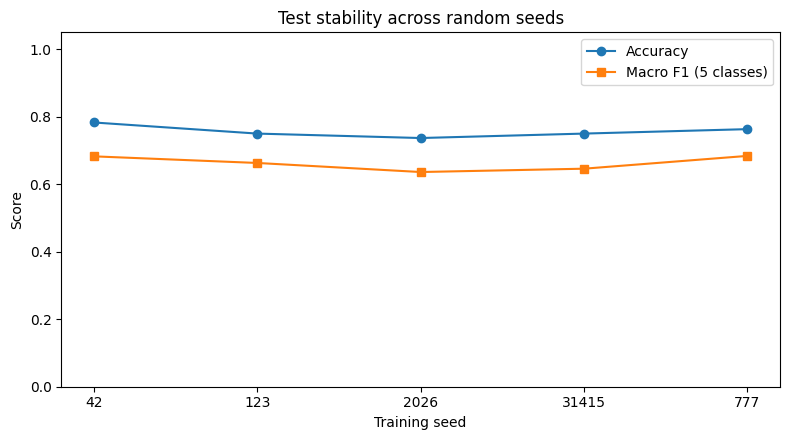


STEP 10 COMPLETED — REPEATED-SEED STABILITY VALIDATION
Validation-selected seed: 777
     Split                    Metric  Runs_With_Defined_Metric     Mean  Std_Dev_Sample      Min      Max
     Train                  Accuracy                         5 0.895615        0.026431 0.872702 0.940594
     Train Balanced_Accuracy_Present                         5 0.940774        0.018715 0.928663 0.973476
     Train      Macro_Precision_All5                         5 0.829675        0.043513 0.791322 0.901505
     Train         Macro_Recall_All5                         5 0.940774        0.018715 0.928663 0.973476
     Train             Macro_F1_All5                         5 0.874841        0.034949 0.844360 0.933719
     Train               Weighted_F1                         5 0.897754        0.025474 0.875879 0.941089
     Train            Macro_AUC_All5                         5 0.991339        0.003348 0.989578 0.997320
Validation                  Accuracy                         5 0.8

In [5]:
# ================================================================
# DERM7PT STEP 10 — REPEATED-SEED STABILITY VALIDATION
# Uses the fixed full-data Step 5 learned 768-D features.
# Re-trains an HH-dynamics-inspired network for each random seed.
# IMPORTANT: This is NOT K-fold CV, NOT patient-grouped CV and NOT
# an exact reproduction of the PDF's end-to-end architecture.
# ================================================================
# Colab: %pip -q install torch numpy pandas scikit-learn matplotlib joblib
import os, json, random, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, balanced_accuracy_score, confusion_matrix, roc_auc_score
import joblib

SEEDS = [42, 123, 2026, 31415, 777]   # Five independent training initializations
EPOCHS = 70
PATIENCE = 11
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
NEURONS = 256
TIME_STEPS = 20
DT_MS = 0.05
DROPOUT = 0.20
# True: evaluate the same untouched test split with each predeclared seed.
# Report these as repeat-run variability, NOT an independent 5-fold estimate.
EVALUATE_TEST_EACH_SEED = True
CLASSES = ('Nevus', 'Melanoma', 'MISC', 'SK', 'BCC')
SPLITS = ('Train', 'Validation', 'Test')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


def resolve_root():
    for prefix in ('/content/drive', '/content/gdrive'):
        p = Path(prefix) / 'MyDrive' / 'Derm7pt'
        if p.is_dir(): return p
    from google.colab import drive
    for prefix in ('/content/drive', '/content/gdrive'):
        mount = Path(prefix)
        mount.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(mount)) and not any(mount.iterdir()):
            drive.mount(str(mount), force_remount=False)
        p = mount / 'MyDrive' / 'Derm7pt'
        if p.is_dir(): return p
    raise FileNotFoundError('Mount Google Drive and verify MyDrive/Derm7pt.')

BASE = resolve_root()
PREP = BASE / 'Derm7pt_Preprocessed'
SOURCE = PREP / 'Step5_Full_768D_Learned_Fusion'
OUT = PREP / 'Step10_Repeated_Seed_Validation'
MODEL_DIR, REPORT, VIS = (OUT / s for s in ('Models', 'Reports', 'Visualizations'))
for p in (MODEL_DIR, REPORT, VIS): p.mkdir(parents=True, exist_ok=True)
COLS = [f'Fusion_{j:03d}' for j in range(768)]
label_map = {c:i for i,c in enumerate(CLASSES)}
raw, target, metadata, id_sets = {}, {}, {}, {}
for split in SPLITS:
    file = SOURCE / f'{split}_Fused_768D.csv'
    if not file.is_file(): raise FileNotFoundError(f'Missing full Step 5 file: {file}')
    df = pd.read_csv(file, dtype={'Lesion_ID': str}, low_memory=False)
    required = set(COLS) | {'Lesion_ID', 'Diagnosis', 'Split'}
    if required - set(df.columns):
        raise ValueError(f'{file.name}: missing columns {sorted(required-set(df.columns))[:10]}')
    if df.empty or df['Lesion_ID'].isna().any() or df['Diagnosis'].isna().any():
        raise ValueError(f'{split}: missing labels/IDs or empty split')
    df['Lesion_ID'] = df['Lesion_ID'].str.strip().str.replace(r'(?<=\d)\.0$', '', regex=True)
    if df['Lesion_ID'].eq('').any() or df['Lesion_ID'].duplicated().any():
        raise ValueError(f'{split}: duplicate or blank IDs')
    if not df['Split'].eq(split).all(): raise ValueError(f'{split}: Split mismatch')
    unknown = set(df['Diagnosis']) - set(CLASSES)
    if unknown: raise ValueError(f'{split}: unexpected labels {unknown}')
    X = df[COLS].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float32)
    if X.shape[1] != 768 or not np.isfinite(X).all():
        raise ValueError(f'{split}: invalid 768-D features')
    raw[split] = X
    target[split] = df['Diagnosis'].map(label_map).to_numpy(dtype=np.int64)
    metadata[split] = df[['Lesion_ID', 'Diagnosis', 'Split']].copy()
    id_sets[split] = set(df['Lesion_ID'])
    print(split, X.shape, df['Diagnosis'].value_counts().to_dict())
for i, a in enumerate(SPLITS):
    for b in SPLITS[i+1:]:
        overlap = id_sets[a] & id_sets[b]
        if overlap: raise ValueError(f'LEAKAGE: {a}/{b} shared IDs {sorted(overlap)[:10]}')
train_count = np.bincount(target['Train'], minlength=5)
if (train_count == 0).any():
    raise ValueError('Train is missing required classes: '+str([CLASSES[i] for i in np.where(train_count == 0)[0]]))
if len(target['Validation']) < 2 or len(target['Test']) < 2:
    raise ValueError('Validation and Test must contain at least two records')

# Train-only normalization, shared across all seeds.
scaler = StandardScaler().fit(raw['Train'])
X = {s: scaler.transform(raw[s]).astype(np.float32) for s in SPLITS}
if any(not np.isfinite(x).all() for x in X.values()):
    raise ValueError('Nonfinite values after scaling')
joblib.dump({'scaler': scaler, 'classes': CLASSES, 'features': COLS}, MODEL_DIR/'TrainOnly_StandardScaler.joblib')

class HHMembrane(nn.Module):
    """Differentiable HH-inspired conductance model matching Steps 6 and 9."""
    def __init__(self, steps=20, dt=0.05):
        super().__init__()
        self.steps, self.dt = int(steps), float(dt)
        self.g_na, self.g_k, self.g_l = 120., 36., 0.3
        self.e_na, self.e_k, self.e_l = 50., -77., -54.387
    @staticmethod
    def vtrap(x, scale):
        z = (x / scale).clamp(-30,30)
        denominator = torch.where(z.abs()<1e-4, torch.ones_like(z), -torch.expm1(-z))
        return torch.where(z.abs()<1e-4, scale*(1+z/2+z*z/12), x/denominator)
    def forward(self, current):
        v = torch.full_like(current, -65.)
        m = torch.full_like(current, .0529)
        h = torch.full_like(current, .5961)
        n = torch.full_like(current, .3177)
        integrated = torch.zeros_like(current)
        surrogate = torch.zeros_like(current)
        for _ in range(self.steps):
            am=.1*self.vtrap(v+40,10)
            bm=4*torch.exp((-(v+65)/18).clamp(-30,30))
            ah=.07*torch.exp((-(v+65)/20).clamp(-30,30))
            bh=torch.sigmoid((v+35)/10)
            an=.01*self.vtrap(v+55,10)
            bn=.125*torch.exp((-(v+65)/80).clamp(-30,30))
            m=torch.clamp(m+self.dt*(am*(1-m)-bm*m),0,1)
            h=torch.clamp(h+self.dt*(ah*(1-h)-bh*h),0,1)
            n=torch.clamp(n+self.dt*(an*(1-n)-bn*n),0,1)
            ina=self.g_na*m**3*h*(v-self.e_na)
            ik=self.g_k*n**4*(v-self.e_k)
            il=self.g_l*(v-self.e_l)
            v=torch.clamp(v+self.dt*(current-ina-ik-il),-100,80)
            integrated+=(v+65)/100
            surrogate+=torch.sigmoid((v+20)/5)
        return torch.cat([integrated/self.steps, surrogate/self.steps],dim=1)

class HHDynamicsClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_projection=nn.Linear(768,NEURONS)
        self.membrane=HHMembrane(TIME_STEPS,DT_MS)
        self.classifier=nn.Sequential(nn.LayerNorm(NEURONS*2), nn.Linear(NEURONS*2,128),
                                      nn.GELU(),nn.Dropout(DROPOUT),nn.Linear(128,5))
    def forward(self,x):
        current=12.+18.*torch.tanh(self.input_projection(x))
        return self.classifier(self.membrane(current))

def make_loader(split, shuffle, generator=None):
    return DataLoader(TensorDataset(torch.from_numpy(X[split]),torch.from_numpy(target[split])),
                      batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator, num_workers=0)

def score(y, probs):
    guess = probs.argmax(axis=1)
    precision, recall, f1, support = precision_recall_fscore_support(
        y, guess, labels=np.arange(5), zero_division=0)
    aucs = {}
    for i, c in enumerate(CLASSES):
        positive = (y == i).astype(int)
        aucs[c] = float(roc_auc_score(positive, probs[:,i])) if np.unique(positive).size == 2 else np.nan
    return {'Samples':len(y), 'Classes_In_GroundTruth':len(np.unique(y)),
            'Accuracy':float(accuracy_score(y,guess)),
            'Balanced_Accuracy_Present':float(balanced_accuracy_score(y,guess)),
            'Macro_Precision_All5':float(precision.mean()),
            'Macro_Recall_All5':float(recall.mean()),
            'Macro_F1_All5':float(f1.mean()),
            'Weighted_F1':float(np.average(f1, weights=support)),
            'Macro_AUC_All5':float(np.mean(list(aucs.values()))) if np.isfinite(list(aucs.values())).all() else np.nan}

results, logs = [], []
for index, seed in enumerate(SEEDS, 1):
    print(f'\n===== RUN {index}/{len(SEEDS)} | Seed {seed} =====')
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    gen = torch.Generator().manual_seed(seed)
    model = HHDynamicsClassifier().to(DEVICE)
    weights = len(target['Train'])/(5*train_count)
    criterion=nn.CrossEntropyLoss(weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE))
    optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',patience=4,factor=.5)
    train_loader=make_loader('Train',True,gen)
    val_loader=make_loader('Validation',False)
    best_state=None; best_loss=np.inf; best_epoch=0; stagnant=0
    for epoch in range(1,EPOCHS+1):
        epoch_values={}
        for split, dl, training in [('Train',train_loader,True),('Validation',val_loader,False)]:
            model.train(training)
            running=0.; hits=0; total=0
            for xb,yb in dl:
                xb,yb=xb.to(DEVICE),yb.to(DEVICE)
                if training: optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(training):
                    logits=model(xb)
                    loss=criterion(logits,yb)
                    if training:
                        loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(),2.)
                        optimizer.step()
                running+=float(loss.item())*len(yb)
                hits+=int((logits.argmax(dim=1)==yb).sum().item())
                total+=len(yb)
            epoch_values[split]=(running/total, hits/total)
        tr_loss,tr_acc=epoch_values['Train']
        va_loss,va_acc=epoch_values['Validation']
        if not np.isfinite([tr_loss,tr_acc,va_loss,va_acc]).all():
            raise RuntimeError(f'Seed {seed}: non-finite training loss; inspect data')
        logs.append({'Seed':seed,'Epoch':epoch,'Train_Loss':tr_loss,'Train_Accuracy':tr_acc,
                     'Validation_Loss':va_loss,'Validation_Accuracy':va_acc})
        scheduler.step(va_loss)
        if va_loss < best_loss-1e-5:
            best_loss,best_epoch,stagnant=va_loss,epoch,0
            best_state=copy.deepcopy(model.state_dict())
        else:
            stagnant+=1
            if stagnant>=PATIENCE: break
    model.load_state_dict(best_state); model.eval()
    torch.save({'state_dict':best_state,'classes':CLASSES,'input_dim':768,
                'neurons':NEURONS,'steps':TIME_STEPS,'dt_ms':DT_MS,
                'seed':seed,'best_epoch':best_epoch},MODEL_DIR/f'Seed_{seed}_Best_HH.pt')
    print(f'Best epoch: {best_epoch} | best val_loss={best_loss:.5f}')
    for split in SPLITS:
        if split == 'Test' and not EVALUATE_TEST_EACH_SEED: continue
        batches=[]
        with torch.no_grad():
            for xb,_ in make_loader(split,False):
                batches.append(model(xb.to(DEVICE)).softmax(dim=1).cpu().numpy())
        probs=np.concatenate(batches)
        metric=score(target[split],probs)
        metric.update({'Seed':seed,'Split':split,'Best_Epoch':best_epoch,
                       'Best_Validation_Loss':best_loss})
        results.append(metric)
        output=metadata[split].copy()
        output['Predicted_Diagnosis']=[CLASSES[i] for i in probs.argmax(axis=1)]
        for j,c in enumerate(CLASSES): output[f'Probability_{c}']=probs[:,j]
        output.to_csv(REPORT/f'Seed_{seed}_{split}_Predictions.csv',index=False)
        print(f'{split}: Accuracy={metric["Accuracy"]:.4f} MacroF1={metric["Macro_F1_All5"]:.4f}')
    del model
    if DEVICE.type=='cuda': torch.cuda.empty_cache()

all_df=pd.DataFrame(results)
all_df.to_csv(REPORT/'Step10_All_Seed_Results.csv',index=False)
pd.DataFrame(logs).to_csv(REPORT/'Step10_Training_Logs.csv',index=False)
metric_names=['Accuracy','Balanced_Accuracy_Present','Macro_Precision_All5',
              'Macro_Recall_All5','Macro_F1_All5','Weighted_F1','Macro_AUC_All5']
summary_rows=[]
for split, grp in all_df.groupby('Split',sort=False):
    for col in metric_names:
        numbers=grp[col].dropna().to_numpy(dtype=float)
        summary_rows.append({'Split':split,'Metric':col,'Runs_With_Defined_Metric':len(numbers),
                             'Mean':float(np.mean(numbers)) if len(numbers) else np.nan,
                             'Std_Dev_Sample':float(np.std(numbers,ddof=1)) if len(numbers)>1 else np.nan,
                             'Min':float(np.min(numbers)) if len(numbers) else np.nan,
                             'Max':float(np.max(numbers)) if len(numbers) else np.nan})
summary_df=pd.DataFrame(summary_rows)
summary_df.to_csv(REPORT/'Step10_Mean_Std_Metrics.csv',index=False)

for split in ('Validation','Test'):
    frame=all_df[all_df.Split.eq(split)]
    if frame.empty: continue
    fig, ax=plt.subplots(figsize=(8,4.5))
    ax.plot(frame.Seed.astype(str),frame.Accuracy,marker='o',label='Accuracy')
    ax.plot(frame.Seed.astype(str),frame.Macro_F1_All5,marker='s',label='Macro F1 (5 classes)')
    ax.set(xlabel='Training seed',ylabel='Score',ylim=(0,1.05),title=f'{split} stability across random seeds')
    ax.legend();fig.tight_layout()
    fig.savefig(VIS/f'{split}_Seed_Stability.png',dpi=180)
    plt.show();plt.close(fig)

best_val=all_df.loc[all_df.Split.eq('Validation')].sort_values(
    ['Macro_F1_All5','Accuracy','Best_Validation_Loss'], ascending=[False,False,True]).iloc[0]
selected_seed=int(best_val.Seed)
selected_test=all_df.loc[(all_df.Split.eq('Test')) & (all_df.Seed.eq(selected_seed))]
summary={
    'protocol':'Repeated-seed retraining on fixed Step 5 full-dataset 768-D features',
    'not_cross_validation':True,'not_end_to_end_retraining':True,
    'not_exact_paper_HH_SNN':True,
    'random_seeds':SEEDS,'train_val_test_sizes':{s:len(target[s]) for s in SPLITS},
    'model_selection_rule':'Highest validation macro F1 then validation accuracy, then lowest validation loss',
    'validation_selected_seed':selected_seed,
    'validation_selected_test_result':selected_test.to_dict(orient='records') if len(selected_test) else None,
    'test_variability_warning':(
        'Same held-out test examples across runs: reported mean/std captures random initializations, '
        'not uncertainty across independently sampled patient cohorts.'),
    'other_limits':[
        'Step 5 supervised embeddings were fitted once; representation learning uncertainty is not included.',
        'Confirm patient-level disjointness when patient IDs are available.',
        'No hyperparameters or seed selection should be adapted using test results.',
        'All-five macro F1 includes zero for labels with no examples in a split.',
        'Undefined class-wise AUCs remain undefined; macro AUC requires all five class contrasts.']}
with open(REPORT/'Step10_Stability_Audit.json','w') as f:json.dump(summary,f,indent=2)
print('\nSTEP 10 COMPLETED — REPEATED-SEED STABILITY VALIDATION')
print('Validation-selected seed:',selected_seed)
print(summary_df.to_string(index=False))
print('Outputs:',OUT)
print('NEXT: patient-grouped CV (if patient identifiers exist), or end-to-end modality ablation.')



Original class counts:
 Diagnosis   Nevus  Melanoma  MISC  SK  BCC
Split                                     
Train         393       185    65  35   29
Validation     95        34    12   4    7
Test           87        33    20   6    6
Patient identifiers: 0 / 1011
Patient metadata: meta.csv has no explicit patient identifier/key pair
Patient IDs appearing across original splits: 0


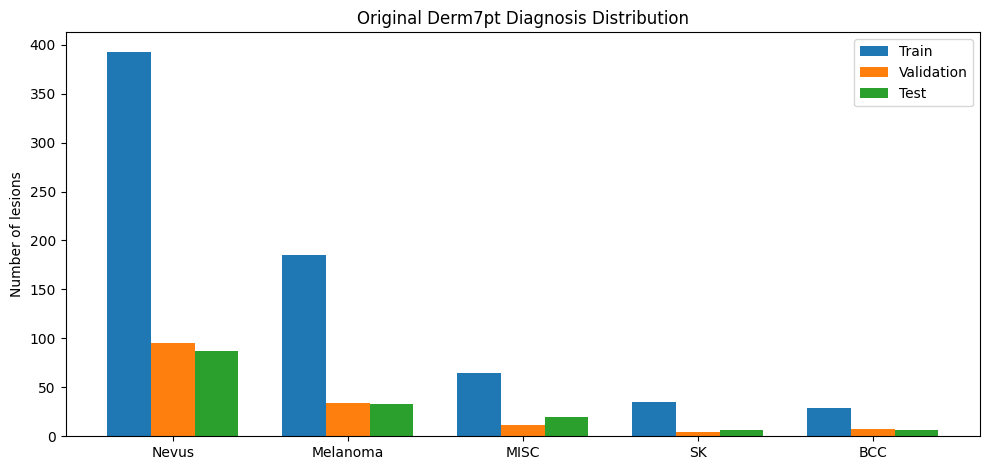

Created 5 lesion_only_exploratory fold assignments in /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step11_CV_Fold_Preparation/Folds

STEP 11 AUDIT FINISHED
Report folder: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step11_CV_Fold_Preparation/Reports
Fold folder: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step11_CV_Fold_Preparation/Folds
Prepared folds: 5
NEXT: Fold-specific representation learning and HH-SNN training; only then report CV metrics.


/tmp/ipykernel_27962/1699583470.py:198: UserWarning: Patient IDs incomplete: lesion-level CV cannot exclude patient leakage.
  warnings.warn('Patient IDs incomplete: lesion-level CV cannot exclude patient leakage.')


In [11]:
# ================================================================
# DERM7PT — STEP 11: PATIENT-LEAKAGE AUDIT + CV FOLD PREPARATION
# ================================================================
# INPUT: original Derm7pt split manifests and (optionally) meta.csv
# OUTPUT: patient/lesion split audit, predeclared CV folds, class plots
# CAUTION: This prepares folds ONLY. It does not train cross-validation
# models or establish cross-validated classification performance.
# IMPORTANT: Step 5 supervised 768-D embeddings must NOT be reused in
# cross-validation training: retrain preprocessing/projection heads
# inside each fold to prevent feature-learning leakage.
# Colab dependencies: %pip -q install pandas numpy scikit-learn matplotlib

import os, re, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

SEED = 42
REQUESTED_FOLDS = 5
ALLOW_EXPLORATORY_LESION_CV = True  # Set True ONLY when patient IDs unavailable.
CLASSES = ('Nevus', 'Melanoma', 'MISC', 'SK', 'BCC')
SPLITS = ('Train', 'Validation', 'Test')

# Use explicit mappings consistent with your Step 5 grouping. Review
# MISC assignments against your research protocol before final reporting.
DIAGNOSIS_MAP = {
    'nevus':'Nevus', 'melanocytic nevus':'Nevus',
    'blue nevus':'Nevus', 'clark nevus':'Nevus',
    'combined nevus':'Nevus', 'congenital nevus':'Nevus',
    'dermal nevus':'Nevus', 'compound nevus':'Nevus',
    'junctional nevus':'Nevus', 'recurrent nevus':'Nevus',
    'reed or spitz nevus':'Nevus',
    'melanoma':'Melanoma', 'melanoma in situ':'Melanoma',
    'melanoma (in situ)':'Melanoma',
    'melanoma (less than 0.76 mm)':'Melanoma',
    'melanoma (0.76 to 1.5 mm)':'Melanoma',
    'melanoma (more than 1.5 mm)':'Melanoma',
    'melanoma metastasis':'Melanoma',
    'basal cell carcinoma':'BCC', 'bcc':'BCC',
    'seborrheic keratosis':'SK', 'seborrhoeic keratosis':'SK', 'sk':'SK',
    'misc':'MISC', 'miscellaneous':'MISC',
    'dermatofibroma':'MISC', 'vascular lesion':'MISC',
    'lentigo':'MISC', 'melanosis':'MISC'
}


def resolve_base():
    for mount in ('/content/drive', '/content/gdrive'):
        root = Path(mount) / 'MyDrive' / 'Derm7pt'
        if root.is_dir():
            return root
    from google.colab import drive
    for mount in ('/content/drive', '/content/gdrive'):
        m = Path(mount)
        m.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(m)) and not any(m.iterdir()):
            drive.mount(str(m), force_remount=False)
        root = m / 'MyDrive' / 'Derm7pt'
        if root.is_dir():
            return root
    raise FileNotFoundError('Could not locate Google Drive/MyDrive/Derm7pt')

BASE = resolve_base()
PREP = BASE / 'Derm7pt_Preprocessed'
ROOT = BASE / 'release_v0'
OUT = PREP / 'Step11_CV_Fold_Preparation'
REPORT, VIS, FOLDS = (OUT / s for s in ('Reports', 'Visualizations', 'Folds'))
for p in (REPORT, VIS, FOLDS):
    p.mkdir(parents=True, exist_ok=True)


def col(df, possibilities):
    lookup = {str(name).lower().strip(): name for name in df.columns}
    return next((lookup[c] for c in possibilities if c in lookup), None)


def clean_id(value):
    if pd.isna(value):
        return ''
    text = str(value).strip()
    return text[:-2] if re.fullmatch(r'\d+\.0', text) else text


def normalize(value):
    return ' '.join(str(value).strip().lower().split())

# Do not infer patient identity from lesion ID, image paths, or filenames.
PATIENT_FIELDS = ('patient_id', 'patientid', 'patient_identifier',
                  'subject_id', 'subjectid', 'participant_id',
                  'individual_id', 'person_id')
JOIN_FIELDS = ('lesion_id', 'case_num', 'case_id')

rows = []
for split in SPLITS:
    p = PREP / f'09_{split}_Image_Manifest.csv'
    if not p.is_file():
        raise FileNotFoundError('Missing manifest: ' + str(p))
    table = pd.read_csv(p, dtype=str)
    ic = col(table, JOIN_FIELDS)
    dc = col(table, ('diagnosis',))
    if ic is None or dc is None:
        raise ValueError(f'{p.name}: Lesion_ID and Diagnosis columns required.')
    part = pd.DataFrame({'Lesion_ID': table[ic].map(clean_id),
                         'Original_Diagnosis': table[dc], 'Split':split})
    if part.Lesion_ID.eq('').any() or part.Lesion_ID.duplicated().any():
        raise ValueError(f'{split}: empty/duplicate lesion IDs')
    part['Diagnosis'] = part.Original_Diagnosis.map(normalize).map(DIAGNOSIS_MAP)
    unknown = sorted(part.loc[part.Diagnosis.isna(), 'Original_Diagnosis'].astype(str).unique())
    if unknown:
        raise ValueError(f'{split}: unmapped diagnoses: {unknown}')
    pc = col(table, PATIENT_FIELDS)
    part['Patient_ID'] = table[pc].map(clean_id).to_numpy() if pc else ''
    rows.append(part)

data = pd.concat(rows, ignore_index=True)
if data.Lesion_ID.duplicated().any():
    repeated = data.loc[data.Lesion_ID.duplicated(keep=False), ['Lesion_ID','Split']]
    repeated.to_csv(REPORT / 'Cross_Split_Leakage.csv', index=False)
    raise ValueError('Lesion-level overlap across original partitions. See Cross_Split_Leakage.csv')

# Optionally obtain authentic patient IDs from Derm7pt original metadata.
meta_path = ROOT / 'meta' / 'meta.csv'
meta_merge_note = 'Not attempted'
if meta_path.is_file():
    meta = pd.read_csv(meta_path, dtype=str)
    patient_col = col(meta, PATIENT_FIELDS)
    id_col = col(meta, JOIN_FIELDS)
    if patient_col and id_col:
        aux = pd.DataFrame({'Lesion_ID':meta[id_col].map(clean_id),
                            'Metadata_Patient_ID':meta[patient_col].map(clean_id)})
        aux = aux.loc[aux.Lesion_ID.ne('')].copy()
        # Multiple metadata records per lesion must agree on patient identity.
        conflict = aux.groupby('Lesion_ID').Metadata_Patient_ID.nunique()
        if (conflict > 1).any():
            raise ValueError('Conflicting patient IDs for the same lesion in meta.csv')
        aux = aux.drop_duplicates('Lesion_ID')
        data = data.merge(aux, on='Lesion_ID', how='left', validate='many_to_one')
        old = data.Patient_ID.fillna('')
        new = data.Metadata_Patient_ID.fillna('')
        conflicts = old.ne('') & new.ne('') & old.ne(new)
        if conflicts.any():
            raise ValueError('Manifest and meta.csv disagree on patient IDs')
        data['Patient_ID'] = old.where(old.ne(''), new)
        data = data.drop(columns=['Metadata_Patient_ID'])
        meta_merge_note = f'Patient_ID joined by exact lesion key {id_col} from meta.csv'
    else:
        meta_merge_note = 'meta.csv has no explicit patient identifier/key pair'
else:
    meta_merge_note = 'meta.csv not found'

data['Patient_ID'] = data.Patient_ID.fillna('').map(clean_id)
patient_coverage = int(data.Patient_ID.ne('').sum())
known_patient = data.loc[data.Patient_ID.ne('')]
patient_overlap = (known_patient.groupby('Patient_ID').Split.nunique() > 1)
leaking_patient_ids = patient_overlap.index[patient_overlap].tolist()
if leaking_patient_ids:
    known_patient.loc[known_patient.Patient_ID.isin(leaking_patient_ids)].to_csv(
        REPORT / 'Patient_Split_Leakage.csv', index=False)

class_counts = (data.groupby(['Split','Diagnosis']).size().unstack(fill_value=0)
                .reindex(index=SPLITS, columns=CLASSES, fill_value=0))
class_counts.to_csv(REPORT / 'Original_Class_Distribution.csv')
data.to_csv(REPORT / 'Original_Lesion_Patient_Audit.csv', index=False)
print('\nOriginal class counts:\n', class_counts)
print('Patient identifiers:', patient_coverage, '/', len(data))
print('Patient metadata:', meta_merge_note)
print('Patient IDs appearing across original splits:', len(leaking_patient_ids))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(CLASSES))
for k, split in enumerate(SPLITS):
    ax.bar(x + (k-1)*.25, class_counts.loc[split].to_numpy(), width=.25, label=split)
ax.set_xticks(x, CLASSES)
ax.set_ylabel('Number of lesions')
ax.set_title('Original Derm7pt Diagnosis Distribution')
ax.legend()
fig.tight_layout()
fig.savefig(VIS / 'Original_Diagnosis_Distribution.png', dpi=160)
plt.show()
plt.close(fig)

# CV candidates: original Train + Validation; original Test untouched.
cv_pool = data.loc[data.Split.isin(('Train','Validation'))].copy().reset_index(drop=True)
held_out = data.loc[data.Split.eq('Test')].copy()
held_out.to_csv(REPORT / 'Untouched_Original_Test_Lesions.csv', index=False)

has_complete_patient_ids = data.Patient_ID.ne('').all()
mode = None
reason = None
if leaking_patient_ids:
    reason = 'Original data partitions share patient IDs. Fix the original partitioning before CV.'
elif has_complete_patient_ids:
    mode = 'patient_grouped'
elif ALLOW_EXPLORATORY_LESION_CV:
    mode = 'lesion_only_exploratory'
    warnings.warn('Patient IDs incomplete: lesion-level CV cannot exclude patient leakage.')
else:
    reason = ('Patient IDs are absent/incomplete. Refusing to call lesion-level CV patient-grouped CV. '
              'Set ALLOW_EXPLORATORY_LESION_CV=True only for an explicitly exploratory analysis.')

fold_summary = []
if mode is not None:
    counts = cv_pool.Diagnosis.value_counts()
    min_class = int(counts.reindex(CLASSES, fill_value=0).min())
    if min_class < REQUESTED_FOLDS:
        reason = (f'Insufficient labels for {REQUESTED_FOLDS}-fold stratification: '
                  f'rarest class contains {min_class} lesions in CV pool.')
        mode = None
    elif mode == 'patient_grouped':
        group_counts = cv_pool.groupby('Diagnosis').Patient_ID.nunique()
        if group_counts.reindex(CLASSES, fill_value=0).min() < REQUESTED_FOLDS:
            reason = ('Too few independent patients in at least one class for the requested '
                      f'{REQUESTED_FOLDS} grouped folds.')
            mode = None

if mode is not None:
    y = cv_pool.Diagnosis.to_numpy()
    if mode == 'patient_grouped':
        splitter = StratifiedGroupKFold(n_splits=REQUESTED_FOLDS, shuffle=True, random_state=SEED)
        folds = splitter.split(cv_pool, y, groups=cv_pool.Patient_ID.to_numpy())
    else:
        splitter = StratifiedKFold(n_splits=REQUESTED_FOLDS, shuffle=True, random_state=SEED)
        folds = splitter.split(cv_pool, y)
    for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
        a = cv_pool.iloc[train_idx].copy()
        b = cv_pool.iloc[valid_idx].copy()
        if set(a.Lesion_ID) & set(b.Lesion_ID):
            raise RuntimeError(f'Fold {fold}: lesion leakage')
        if mode == 'patient_grouped' and (set(a.Patient_ID) & set(b.Patient_ID)):
            raise RuntimeError(f'Fold {fold}: patient leakage')
        a['CV_Role'] = 'Train'
        b['CV_Role'] = 'Validation'
        a['Fold'] = fold
        b['Fold'] = fold
        combined_fold = pd.concat([a,b], ignore_index=True)
        combined_fold.to_csv(FOLDS / f'Fold_{fold:02d}_Assignments.csv', index=False)
        for role, piece in (('Train', a), ('Validation', b)):
            support = piece.Diagnosis.value_counts().reindex(CLASSES, fill_value=0)
            fold_summary.append({'Fold':fold, 'Role':role, 'Lesions':len(piece),
                                 'Patients': piece.Patient_ID.nunique() if mode=='patient_grouped' else np.nan,
                                 **{f'Count_{c}':int(support[c]) for c in CLASSES}})
    pd.DataFrame(fold_summary).to_csv(REPORT / 'Fold_Class_Support.csv', index=False)
    if any(row[f'Count_{c}']==0 for row in fold_summary for c in CLASSES):
        warnings.warn('Some grouped folds have zero samples for a class. See Fold_Class_Support.csv.')
    print(f'Created {REQUESTED_FOLDS} {mode} fold assignments in {FOLDS}')
else:
    print('No folds created:', reason)

summary = {
    'protocol':'Step 11 patient-level leakage audit and CV fold preparation ONLY',
    'patient_identity_source':meta_merge_note,
    'patient_ids_available':patient_coverage,
    'total_lesions':len(data),
    'cross_partition_patient_overlap_count':len(leaking_patient_ids),
    'cross_partition_patient_overlap_ids':leaking_patient_ids[:20],
    'folds_created':len(set(row['Fold'] for row in fold_summary)),
    'fold_mode':mode,
    'fold_creation_blocker':reason,
    'cv_pool':'Original Train + Validation; Test withheld untouched',
    'test_records_reserved':len(held_out),
    'model_trained':False,
    'cross_validation_scores_calculated':False,
    'critical_next_step':'For actual CV, refit Step 5 imputers/scalers, supervised projection heads and HH-SNN separately inside each training fold. Do NOT reuse globally trained Step 5 fused features.',
    'limitations':['Patient_ID is never derived from Lesion_ID.',
                   'Group stratification may be imperfect when class counts are small.',
                   'Original partition leakage must be resolved before a patient-independent evaluation.']
}
with open(REPORT / 'Step11_Preparation_Audit.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('\nSTEP 11 AUDIT FINISHED')
print('Report folder:', REPORT)
print('Fold folder:', FOLDS)
print('Prepared folds:', summary['folds_created'])
print('NEXT: Fold-specific representation learning and HH-SNN training; only then report CV metrics.')


Device: cuda


/tmp/ipykernel_27962/4063504878.py:74: UserWarning: EXPLORATORY lesion-level CV: patient independence unverified.
  warnings.warn('EXPLORATORY lesion-level CV: patient independence unverified.')


derm features: 960 IDs: 858
clinical features: 960 IDs: 859
metadata features: 64 IDs: 859

FOLD 1/5
Fold score: {'Fold': 1, 'N_Train': 687, 'N_Validation': 172, 'Accuracy': 0.8546511627906976, 'Macro_Precision_5class': 0.7528824833702882, 'Macro_Recall_5class': 0.8265615337043908, 'Macro_F1_5class': 0.7809204231520787, 'Macro_OVR_AUC_All5': 0.9651529717390226, 'Classes_In_Validation': 5}

FOLD 2/5
Fold score: {'Fold': 2, 'N_Train': 687, 'N_Validation': 172, 'Accuracy': 0.8313953488372093, 'Macro_Precision_5class': 0.7075064935064935, 'Macro_Recall_5class': 0.7483534322820037, 'Macro_F1_5class': 0.7206367325313972, 'Macro_OVR_AUC_All5': 0.9544208852802603, 'Classes_In_Validation': 5}

FOLD 3/5
Fold score: {'Fold': 3, 'N_Train': 687, 'N_Validation': 172, 'Accuracy': 0.7151162790697675, 'Macro_Precision_5class': 0.5583380979607395, 'Macro_Recall_5class': 0.6391350917124112, 'Macro_F1_5class': 0.5848530176997614, 'Macro_OVR_AUC_All5': 0.9143867783325131, 'Classes_In_Validation': 5}

FOLD 

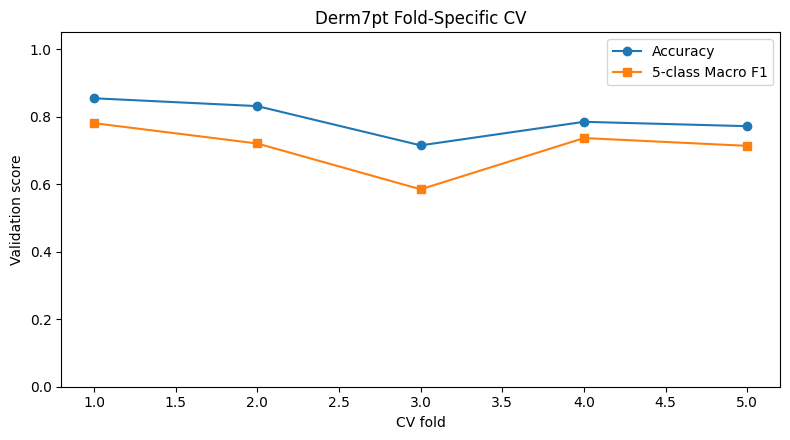


STEP 12 COMPLETED
 Fold  N_Train  N_Validation  Accuracy  Macro_Precision_5class  Macro_Recall_5class  Macro_F1_5class  Macro_OVR_AUC_All5  Classes_In_Validation
    1      687           172  0.854651                0.752882             0.826562         0.780920            0.965153                      5
    2      687           172  0.831395                0.707506             0.748353         0.720637            0.954421                      5
    3      687           172  0.715116                0.558338             0.639135         0.584853            0.914387                      5
    4      687           172  0.784884                0.691878             0.810002         0.736792            0.955527                      5
    5      688           171  0.771930                0.670589             0.792825         0.713636            0.952805                      5

Mean/SD:
                Metric  Defined_Folds     Mean  Std_Dev
              Accuracy              5 0.791595 0.05

In [12]:
# ===============================================================
# DERM7PT STEP 12 — FOLD-SPECIFIC PROJECTION + HH-INSPIRED CV
# Uses Step11 assignments and Step4 (pre-fusion) modality features.
# NEVER use Step5 learned 768-D features for cross-validation.
# IMPORTANT: Step4 FT-Transformer embeddings must also be learned
# without CV-fold validation labels/data. If that cannot be verified,
# treat results as exploratory rather than leakage-free CV.
# ===============================================================
# Colab: %pip -q install torch tensorflow pandas numpy scikit-learn matplotlib joblib
import os, re, json, copy, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score

SEED=42
FUSION_EPOCHS=35
HH_EPOCHS=55
PATIENCE=8
BATCH_SIZE=32
PROJECTION_DIM=256
HH_NEURONS=256
TIME_STEPS=20
DT=0.05
LR=3e-4
CLASSES=('Nevus','Melanoma','MISC','SK','BCC')
BRANCHES={
 'derm':'{split}_ViT_Swin_Dermoscopic_Features.csv',
 'clinical':'{split}_ConvNeXt_ViT_Clinical_Features.csv',
 'metadata':'{split}_FTTransformer_Aligned_Metadata_Embeddings.csv'
}
SPLITS=('Train','Validation')
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE)

def find_base():
    for mount in ('/content/drive','/content/gdrive'):
        p=Path(mount)/'MyDrive'/'Derm7pt'
        if p.is_dir(): return p
    from google.colab import drive
    for mount in ('/content/drive','/content/gdrive'):
        p=Path(mount);p.mkdir(parents=True,exist_ok=True)
        if not os.path.ismount(str(p)) and not any(p.iterdir()): drive.mount(str(p),force_remount=False)
        root=p/'MyDrive'/'Derm7pt'
        if root.is_dir():return root
    raise FileNotFoundError('Unable to find /MyDrive/Derm7pt. Mount Google Drive.')
BASE=find_base();PREP=BASE/'Derm7pt_Preprocessed'
SOURCE=PREP/'Step4_Full_Modality_Features'
STEP11=PREP/'Step11_CV_Fold_Preparation'
OUT=PREP/'Step12_FoldSpecific_CV'
REPORT=OUT/'Reports';MODELS=OUT/'Models';VIS=OUT/'Visualizations'
for p in (REPORT,MODELS,VIS):p.mkdir(parents=True,exist_ok=True)

# Step 11 may intentionally refuse to create folds when patient IDs absent.
audit_path=STEP11/'Reports'/'Step11_Preparation_Audit.json'
if not audit_path.is_file():raise FileNotFoundError('Step 11 audit missing: '+str(audit_path))
with open(audit_path) as f:audit=json.load(f)
mode=audit.get('fold_mode');fold_count=int(audit.get('folds_created') or 0)
if fold_count==0:
    raise RuntimeError('Step 11 did not prepare CV folds. Reason: '+str(audit.get('fold_creation_blocker'))+
      '\nFor exploratory lesion-level CV, explicitly set ALLOW_EXPLORATORY_LESION_CV=True in Step 11, rerun it, and disclose that patients may overlap. Do NOT claim patient-grouped CV.')
if mode not in ('patient_grouped','lesion_only_exploratory'):
    raise ValueError('Unrecognized Step11 CV mode: '+str(mode))
if audit.get('cross_partition_patient_overlap_count',0):
    raise RuntimeError('Step11 detected cross-partition patient leakage; repair original partitions first.')
if mode=='lesion_only_exploratory':
    warnings.warn('EXPLORATORY lesion-level CV: patient independence unverified.')
fold_files=sorted((STEP11/'Folds').glob('Fold_*_Assignments.csv'))
if len(fold_files)!=fold_count:raise ValueError('Step11 fold file count differs from audit: rerun Step11.')

# Load ONLY original Train + Validation Step4 features.
def clean_id(v):
    if pd.isna(v):return ''
    s=str(v).strip()
    return s[:-2] if re.fullmatch(r'\d+\.0',s) else s

all_features={}
for branch,pattern in BRANCHES.items():
    parts=[]; schema=None
    for split in SPLITS:
        path=SOURCE/pattern.format(split=split)
        if not path.exists():raise FileNotFoundError('Step4 file missing: '+str(path))
        df=pd.read_csv(path,dtype={'Lesion_ID':str},low_memory=False)
        if 'Lesion_ID' not in df:raise ValueError(str(path)+' missing Lesion_ID')
        df['Lesion_ID']=df['Lesion_ID'].map(clean_id)
        if df.Lesion_ID.eq('').any() or df.Lesion_ID.duplicated().any():
            raise ValueError('Bad IDs in '+str(path))
        excluded={'Lesion_ID','Split','Diagnosis','Diagnosis_Code','Original_Row','Original_Diagnosis','target','label','Is_Augmented'}
        cols=[c for c in df.columns if c not in excluded]
        if not cols:raise ValueError('No feature columns in '+str(path))
        if schema is None:schema=cols
        if cols!=schema:raise ValueError(f'{branch}: schema differs across Train and Validation')
        numeric=df[cols].apply(pd.to_numeric,errors='coerce')
        out=pd.concat([df[['Lesion_ID']],numeric],axis=1)
        out.insert(0,'Original_Split',split)
        parts.append(out)
    merged=pd.concat(parts,ignore_index=True)
    if merged.Lesion_ID.duplicated().any():raise RuntimeError('Step4 lesion overlap: '+branch)
    all_features[branch]={'data':merged.set_index('Lesion_ID'),'columns':schema}
    print(branch,'features:',len(schema),'IDs:',len(merged))

class HHMembrane(nn.Module):
    def __init__(self,steps=TIME_STEPS,dt=DT):
        super().__init__();self.steps,self.dt=steps,dt
    def vtrap(self,x,s):
        z=(x/s).clamp(-30,30)
        den=torch.where(z.abs()<1e-4,torch.ones_like(z),-torch.expm1(-z))
        return torch.where(z.abs()<1e-4,s*(1+z/2+z*z/12),x/den)
    def forward(self,I):
        v=torch.full_like(I,-65.);m=torch.full_like(I,.0529)
        h=torch.full_like(I,.5961);n=torch.full_like(I,.3177)
        vmean=torch.zeros_like(I);proxy=torch.zeros_like(I)
        for _ in range(self.steps):
            am=.1*self.vtrap(v+40,10);bm=4*torch.exp((-(v+65)/18).clamp(-30,30))
            ah=.07*torch.exp((-(v+65)/20).clamp(-30,30));bh=torch.sigmoid((v+35)/10)
            an=.01*self.vtrap(v+55,10);bn=.125*torch.exp((-(v+65)/80).clamp(-30,30))
            m=(m+self.dt*(am*(1-m)-bm*m)).clamp(0,1)
            h=(h+self.dt*(ah*(1-h)-bh*h)).clamp(0,1)
            n=(n+self.dt*(an*(1-n)-bn*n)).clamp(0,1)
            ina=120*m**3*h*(v-50);ik=36*n**4*(v+77);il=.3*(v+54.387)
            v=(v+self.dt*(I-ina-ik-il)).clamp(-100,80)
            vmean=vmean+(v+65)/100
            proxy=proxy+torch.sigmoid((v+20)/5)
        return torch.cat([vmean/self.steps,proxy/self.steps],dim=1)

class FusionHH(nn.Module):
    def __init__(self,dims):
        super().__init__()
        self.projections=nn.ModuleDict({k:nn.Sequential(nn.Linear(d,256),nn.GELU()) for k,d in dims.items()})
        self.aux=nn.Sequential(nn.Linear(768+3,128),nn.GELU(),nn.Dropout(.15),nn.Linear(128,5))
        self.current=nn.Linear(768,HH_NEURONS)
        self.mem=HHMembrane()
        self.readout=nn.Sequential(nn.LayerNorm(HH_NEURONS*2),nn.Linear(HH_NEURONS*2,128),
                                   nn.GELU(),nn.Dropout(.2),nn.Linear(128,5))
    def fused(self,inputs,flags):
        chunks=[self.projections[k](inputs[k])*flags[k] for k in BRANCHES]
        return torch.cat(chunks,dim=1)
    def forward(self,inputs,flags,stage='hh'):
        fusion=self.fused(inputs,flags)
        if stage=='aux':return self.aux(torch.cat([fusion]+[flags[k] for k in BRANCHES],dim=1))
        current=12+18*torch.tanh(self.current(fusion))
        return self.readout(self.mem(current))

class FoldDataset(torch.utils.data.Dataset):
    def __init__(self,inputs,flags,y):self.inputs=inputs;self.flags=flags;self.y=y
    def __len__(self):return len(self.y)
    def __getitem__(self,i):return ({k:v[i] for k,v in self.inputs.items()},
                                      {k:v[i] for k,v in self.flags.items()},self.y[i])

def prep_fold(train_ids,val_ids):
    out={};transforms={};dims={}
    for branch,obj in all_features.items():
        frame=obj['data']; cols=obj['columns'];dims[branch]=len(cols)
        t=frame.reindex(train_ids)[cols].to_numpy(dtype=np.float32)
        v=frame.reindex(val_ids)[cols].to_numpy(dtype=np.float32)
        t[~np.isfinite(t)]=np.nan;v[~np.isfinite(v)]=np.nan
        has_t=np.isfinite(t).any(axis=1);has_v=np.isfinite(v).any(axis=1)
        if not has_t.any():raise ValueError('No train features for branch '+branch)
        if np.isnan(t).all(axis=0).any():raise ValueError(f'{branch}: feature columns absent from this training fold')
        imp=SimpleImputer(strategy='median',keep_empty_features=True)
        sc=StandardScaler();tt=sc.fit_transform(imp.fit_transform(t))
        vv=sc.transform(imp.transform(v));tt[~has_t]=0;vv[~has_v]=0
        out[branch]=(tt.astype('float32'),vv.astype('float32'),has_t.astype('float32')[:,None],has_v.astype('float32')[:,None])
        transforms[branch]={'imputer':imp,'scaler':sc,'columns':cols}
    return out,transforms,dims

def make_data(prepped,y,role):
    index=0 if role=='train' else 1; flag_index=2 if role=='train' else 3
    inputs={k:torch.from_numpy(prepped[k][index]) for k in BRANCHES}
    flags={k:torch.from_numpy(prepped[k][flag_index]) for k in BRANCHES}
    return FoldDataset(inputs,flags,torch.as_tensor(y,dtype=torch.long))

def run_epoch(model,dataloader,optimizer,criterion,stage):
    training=optimizer is not None
    model.train(training);loss_sum=0.;n=0;all_pred=[];all_true=[]
    for inputs,flags,y in dataloader:
        inputs={k:v.to(DEVICE) for k,v in inputs.items()}
        flags={k:v.to(DEVICE) for k,v in flags.items()};y=y.to(DEVICE)
        if training:optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(inputs,flags,stage)
            loss=criterion(logits,y)
            if training:
                loss.backward();nn.utils.clip_grad_norm_(model.parameters(),2.)
                optimizer.step()
        n+=len(y);loss_sum+=float(loss.item())*len(y)
        all_pred.extend(logits.argmax(1).detach().cpu().tolist());all_true.extend(y.cpu().tolist())
    return loss_sum/n,accuracy_score(all_true,all_pred)

def train_stage(model,tr,va,weights,stage,epochs,fold):
    # Freeze unused branch weights to prevent wasted gradients.
    if stage=='aux':
        for p in model.parameters():p.requires_grad_(False)
        for p in model.projections.parameters():p.requires_grad_(True)
        for p in model.aux.parameters():p.requires_grad_(True)
    else:
        for p in model.parameters():p.requires_grad_(False)
        for p in model.current.parameters():p.requires_grad_(True)
        for p in model.readout.parameters():p.requires_grad_(True)
        # Consistent with Step5->Step6: freeze learned fusion projections.
    opt=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=LR,weight_decay=1e-4)
    loss_fn=nn.CrossEntropyLoss(weight=torch.as_tensor(weights,dtype=torch.float32,device=DEVICE))
    best=np.inf;best_state=None;stale=0;log=[]
    for epoch in range(1,epochs+1):
        lt,at=run_epoch(model,tr,opt,loss_fn,stage)
        lv,av=run_epoch(model,va,None,loss_fn,stage)
        if not np.isfinite([lt,at,lv,av]).all():raise RuntimeError('Nonfinite fold loss')
        log.append({'Fold':fold,'Stage':stage,'Epoch':epoch,'Train_Loss':lt,'Train_Accuracy':at,'Validation_Loss':lv,'Validation_Accuracy':av})
        if lv<best-1e-5:
            best=lv;best_state=copy.deepcopy(model.state_dict());stale=0
        else:
            stale+=1
            if stale>=PATIENCE:break
    if best_state is None:raise RuntimeError('No checkpoint produced')
    model.load_state_dict(best_state)
    return log

rows=[];histories=[];support_rows=[]
for fold_file in fold_files:
    fold=int(re.search(r'Fold_(\d+)',fold_file.stem).group(1))
    print('\n'+'='*65+'\nFOLD '+str(fold)+'/'+str(fold_count))
    random.seed(SEED+fold);np.random.seed(SEED+fold);torch.manual_seed(SEED+fold)
    frame=pd.read_csv(fold_file,dtype={'Lesion_ID':str,'Patient_ID':str})
    needed={'Lesion_ID','Diagnosis','CV_Role','Fold'}
    if needed-set(frame.columns):raise ValueError(str(fold_file)+' missing columns '+str(needed-set(frame.columns)))
    frame['Lesion_ID']=frame['Lesion_ID'].map(clean_id)
    if frame.Lesion_ID.duplicated().any():raise ValueError('Duplicate lesion ID in '+str(fold_file))
    if not frame.Fold.eq(fold).all():raise ValueError('Incorrect Fold column')
    if not set(frame.CV_Role).issubset({'Train','Validation'}):raise ValueError('Unknown CV_Role')
    tr=frame[frame.CV_Role=='Train'].copy();va=frame[frame.CV_Role=='Validation'].copy()
    if len(tr)==0 or len(va)==0:raise ValueError('Empty train/validation fold')
    if mode=='patient_grouped':
        if tr.Patient_ID.isna().any() or va.Patient_ID.isna().any():raise ValueError('Missing patient IDs')
        if set(tr.Patient_ID)&set(va.Patient_ID):raise ValueError('Patient overlap in fold')
    if (tr.Diagnosis.isna().any() or va.Diagnosis.isna().any() or
        not set(pd.concat([tr.Diagnosis,va.Diagnosis])).issubset(CLASSES)):
        raise ValueError('Unexpected diagnosis in CV fold')
    ytr=tr.Diagnosis.map({c:i for i,c in enumerate(CLASSES)}).to_numpy(dtype=int)
    yva=va.Diagnosis.map({c:i for i,c in enumerate(CLASSES)}).to_numpy(dtype=int)
    counts=np.bincount(ytr,minlength=5)
    if (counts==0).any():raise ValueError('Fold '+str(fold)+' lacks TRAIN class(es): '+str([CLASSES[j] for j in np.where(counts==0)[0]]))
    for role,yy in [('Train',ytr),('Validation',yva)]:
        support_rows.extend({'Fold':fold,'Role':role,'Class':c,'Count':int(np.sum(yy==j))} for j,c in enumerate(CLASSES))
    prepped,transforms,dims=prep_fold(tr.Lesion_ID.tolist(),va.Lesion_ID.tolist())
    joblib.dump(transforms,MODELS/f'Fold_{fold:02d}_TrainOnly_Transformers.joblib')
    td=make_data(prepped,ytr,'train');vd=make_data(prepped,yva,'val')
    train_dl=DataLoader(td,batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    val_dl=DataLoader(vd,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
    model=FusionHH(dims).to(DEVICE)
    weights=len(ytr)/(5*counts)
    hist1=train_stage(model,train_dl,val_dl,weights,'aux',FUSION_EPOCHS,fold)
    hist2=train_stage(model,train_dl,val_dl,weights,'hh',HH_EPOCHS,fold)
    histories+=hist1+hist2
    model.eval();prob=[]
    with torch.no_grad():
        for inputs,flags,_ in val_dl:
            inputs={k:v.to(DEVICE) for k,v in inputs.items()}
            flags={k:v.to(DEVICE) for k,v in flags.items()}
            prob.append(torch.softmax(model(inputs,flags,'hh'),dim=1).cpu().numpy())
    prob=np.concatenate(prob);pred=prob.argmax(1)
    p,r,f,s=precision_recall_fscore_support(yva,pred,labels=np.arange(5),zero_division=0)
    aucs=[]
    for j in range(5):
        binary=(yva==j).astype(int)
        aucs.append(float(roc_auc_score(binary,prob[:,j])) if np.unique(binary).size==2 else np.nan)
    row={'Fold':fold,'N_Train':len(ytr),'N_Validation':len(yva),'Accuracy':float(accuracy_score(yva,pred)),
         'Macro_Precision_5class':float(p.mean()),'Macro_Recall_5class':float(r.mean()),
         'Macro_F1_5class':float(f.mean()),'Macro_OVR_AUC_All5':float(np.mean(aucs)) if np.isfinite(aucs).all() else np.nan,
         'Classes_In_Validation':int(np.unique(yva).size)}
    rows.append(row)
    result=va[['Lesion_ID','Diagnosis']].copy().reset_index(drop=True)
    result['Fold']=fold;result['Predicted_Diagnosis']=[CLASSES[j] for j in pred]
    for j,c in enumerate(CLASSES):result[f'Probability_{c}']=prob[:,j]
    result.to_csv(REPORT/f'Fold_{fold:02d}_Validation_Predictions.csv',index=False)
    cm=confusion_matrix(yva,pred,labels=np.arange(5))
    pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(REPORT/f'Fold_{fold:02d}_Confusion_Matrix.csv')
    torch.save({'state_dict':model.state_dict(),'dims':dims,'classes':CLASSES,'fold':fold,'cv_mode':mode,
                'stage':'fold-specific projection followed by HH-inspired training'},
               MODELS/f'Fold_{fold:02d}_Fusion_HH.pt')
    print('Fold score:',row)
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()

scores=pd.DataFrame(rows).sort_values('Fold');scores.to_csv(REPORT/'Step12_Per_Fold_Metrics.csv',index=False)
pd.DataFrame(histories).to_csv(REPORT/'Step12_Training_Logs.csv',index=False)
pd.DataFrame(support_rows).to_csv(REPORT/'Step12_Fold_Class_Support.csv',index=False)
summary=[]
for metric in ('Accuracy','Macro_Precision_5class','Macro_Recall_5class','Macro_F1_5class','Macro_OVR_AUC_All5'):
    values=scores[metric].dropna()
    summary.append({'Metric':metric,'Defined_Folds':len(values),'Mean':float(values.mean()) if len(values) else np.nan,
                    'Std_Dev':float(values.std(ddof=1)) if len(values)>1 else np.nan})
pd.DataFrame(summary).to_csv(REPORT/'Step12_CV_Mean_Std.csv',index=False)

fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot(scores.Fold,scores.Accuracy,marker='o',label='Accuracy')
ax.plot(scores.Fold,scores.Macro_F1_5class,marker='s',label='5-class Macro F1')
ax.set(ylim=(0,1.05),xlabel='CV fold',ylabel='Validation score',title='Derm7pt Fold-Specific CV')
ax.legend();fig.tight_layout();fig.savefig(VIS/'CV_Fold_Performance.png',dpi=170)
plt.show();plt.close(fig)
info={'cv_mode':mode,'folds':fold_count,'source_step4':str(SOURCE),'step5_global_embeddings_used':False,
      'fit_preprocessing_inside_fold':True,'fit_256d_supervised_projections_inside_fold':True,
      'train_HH_inside_fold':True,'held_out_original_test_used':False,
      'method':'Two-stage fold-specific supervised fusion followed by HH-inspired classifier',
      'limitations':[
          'Step4 frozen ImageNet image encoders are not refit within folds (valid if truly unsupervised with respect to Derm7pt).',
          'The original FT-Transformer metadata embedding weights/protocol must be checked: if they were fit globally, this CV has representation leakage.',
          'Projection best epochs are chosen on same fold validation set used for final fold metrics; this adds model-selection optimism. Nested CV or internal train-only stopping split is stronger.',
          'No patient independence is implied for exploratory lesion-level folds.',
          'A full end-to-end PDF replication would train specified image encoders and HH-SNN with nested, patient-grouped evaluation.',
          'No final held-out test evaluation is performed here.'
      ]}
with open(REPORT/'Step12_CV_Audit.json','w') as f:json.dump(info,f,indent=2)
print('\nSTEP 12 COMPLETED')
print(scores.to_string(index=False))
print('\nMean/SD:');print(pd.DataFrame(summary).to_string(index=False))
print('Reports:',REPORT)
print('Models:',MODELS)
print('Plots:',VIS)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


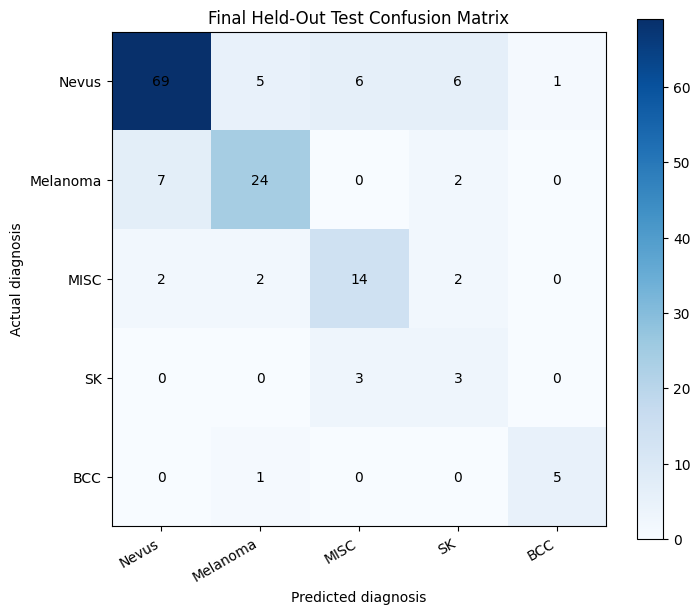

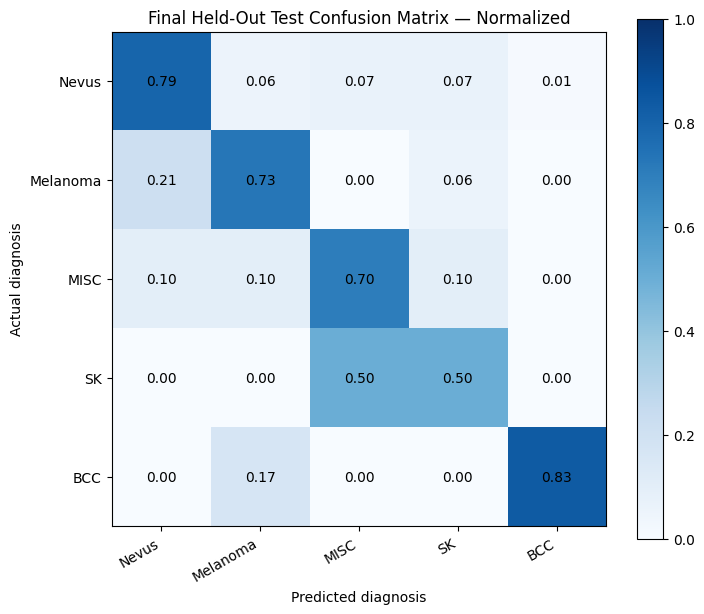

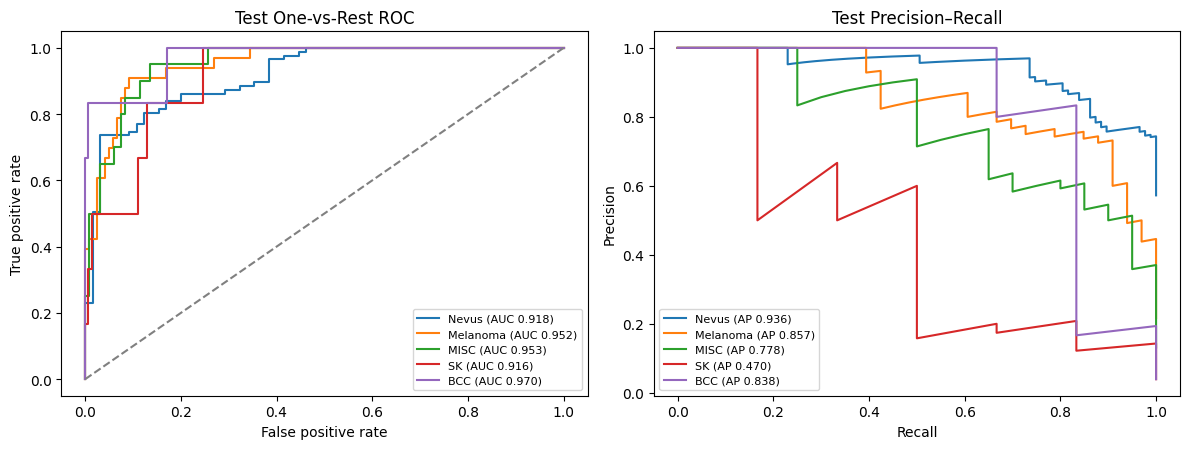

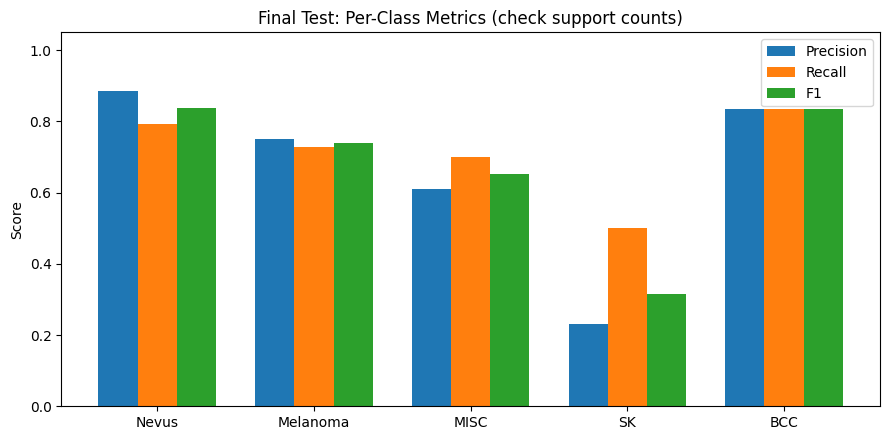


STEP 13 COMPLETE — FINAL TEST REPORT PACKAGE
Actual final test metrics:
 Test_Samples  Classes_In_Test  Accuracy  Balanced_Accuracy_Present_Classes  Macro_Precision_All5  Macro_Recall_All5  Macro_F1_All5  Weighted_F1  Macro_OVR_AUC_All5     MCC  Cohen_Kappa  Log_Loss
          152                5  0.756579                           0.710742              0.661483           0.710742       0.675022     0.770071            0.941729 0.62066     0.617102  0.638978
Confidence intervals:
       Metric  Estimate  Lower_95  Upper_95                                           Resampling_Unit  Bootstrap_Replicates
     Accuracy  0.756579  0.690789  0.822368 Lesion-level bootstrap; clustering by patient unavailable                  1500
Macro_F1_All5  0.675022  0.557363  0.760828 Lesion-level bootstrap; clustering by patient unavailable                  1500
Warnings / methodological limitations: 9
Reports: /content/drive/MyDrive/Derm7pt/Derm7pt_Preprocessed/Step13_Final_Test_Research_Report/Repor

In [13]:
# ===============================================================
# DERM7PT — STEP 13: FINAL TEST AUDIT + RESEARCH RESULT PACKAGE
# ===============================================================
# Uses ACTUAL held-out test predictions saved by FULL Step 6.
# Step 7 / Step 10 / Step 12 are summarized as separate evidence.
# Does NOT train, tune, choose or modify any model.
# Does NOT call CV results a new independent test experiment.
# NOTE: Step 6 checkpoint selection was based on original validation.
# NOTE: Frozen image encoders + HH-inspired dynamics != exact paper.
# Colab: %pip -q install pandas numpy matplotlib scikit-learn

from pathlib import Path
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    confusion_matrix, precision_recall_fscore_support, roc_curve,
    roc_auc_score, average_precision_score, precision_recall_curve,
    log_loss, matthews_corrcoef, cohen_kappa_score)

SEED = 42
BOOTSTRAP = 1500
CLASSES = ('Nevus', 'Melanoma', 'MISC', 'SK', 'BCC')
PROBS = [f'Probability_{c}' for c in CLASSES]
COLS = [f'Fusion_{j:03d}' for j in range(768)]
RNG = np.random.default_rng(SEED)


def locate_project():
    for mount in ('/content/drive', '/content/gdrive'):
        candidate = Path(mount) / 'MyDrive' / 'Derm7pt'
        if candidate.is_dir():
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError('Google Colab Drive is required; mount your Derm7pt folder.')
    for mount in ('/content/drive', '/content/gdrive'):
        root = Path(mount)
        root.mkdir(parents=True, exist_ok=True)
        if not os.path.ismount(str(root)) and not any(root.iterdir()):
            drive.mount(str(root), force_remount=False)
        candidate = root / 'MyDrive' / 'Derm7pt'
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError('Project missing under /content/drive/MyDrive/Derm7pt.')

BASE = locate_project()
PREP = BASE / 'Derm7pt_Preprocessed'
STEP5 = PREP / 'Step5_Full_768D_Learned_Fusion'
STEP6 = PREP / 'Step6_Full_FiveClass_HHSNN'
STEP7 = PREP / 'Step7_Full_HHSNN_Evaluation'
STEP10 = PREP / 'Step10_Repeated_Seed_Validation'
STEP11 = PREP / 'Step11_CV_Fold_Preparation'
STEP12 = PREP / 'Step12_FoldSpecific_CV'
OUT = PREP / 'Step13_Final_Test_Research_Report'
REPORT = OUT / 'Reports'
VIS = OUT / 'Visualizations'
for d in (REPORT, VIS):
    d.mkdir(parents=True, exist_ok=True)


def read_required(path, **kwargs):
    if not path.is_file():
        raise FileNotFoundError(f'Required completed previous-step file missing: {path}')
    return pd.read_csv(path, **kwargs)


def clean_ids(s):
    return s.astype('string').str.strip().str.replace(r'(?<=\d)\.0$', '', regex=True)


# 1. Use a checkpoint that was already trained before this reporting stage.
checkpoint = STEP6 / 'Models' / 'Best_HH_Dynamics_Classifier.pt'
if not checkpoint.is_file():
    raise FileNotFoundError(f'Full Step 6 checkpoint missing: {checkpoint}')

manifest = read_required(PREP / '09_Test_Image_Manifest.csv', dtype=str)
if 'Lesion_ID' not in manifest.columns:
    raise ValueError('Original held-out test manifest needs Lesion_ID.')
manifest['Lesion_ID'] = clean_ids(manifest['Lesion_ID'])
if manifest.Lesion_ID.isna().any() or manifest.Lesion_ID.eq('').any() or manifest.Lesion_ID.duplicated().any():
    raise ValueError('Original test manifest has missing or repeated lesion IDs.')

fusion_test = read_required(STEP5 / 'Test_Fused_768D.csv', dtype={'Lesion_ID': str})
result = read_required(STEP6 / 'Reports' / 'Test_Predictions.csv', dtype={'Lesion_ID': str})
for label, frame in [('Step 5 test', fusion_test), ('Step 6 predictions', result)]:
    required = {'Lesion_ID', 'Diagnosis'} | (set(COLS) if 'Step 5' in label else set(PROBS) | {'Predicted_Diagnosis'})
    if not required.issubset(frame.columns):
        raise ValueError(f'{label}: missing columns {sorted(required-set(frame.columns))[:12]}')
    frame['Lesion_ID'] = clean_ids(frame['Lesion_ID'])
    if frame.Lesion_ID.isna().any() or frame.Lesion_ID.eq('').any() or frame.Lesion_ID.duplicated().any():
        raise ValueError(f'{label}: missing or duplicate Lesion_ID.')

orig_ids = set(manifest.Lesion_ID)
fused_ids = set(fusion_test.Lesion_ID)
pred_ids = set(result.Lesion_ID)
if not (orig_ids == fused_ids == pred_ids):
    audit_missing = pd.DataFrame({'Lesion_ID': sorted(orig_ids | fused_ids | pred_ids)})
    audit_missing['In_Original_Test'] = audit_missing.Lesion_ID.isin(orig_ids)
    audit_missing['In_Fusion'] = audit_missing.Lesion_ID.isin(fused_ids)
    audit_missing['In_Predictions'] = audit_missing.Lesion_ID.isin(pred_ids)
    audit_missing.to_csv(REPORT / 'Test_Coverage_Mismatch.csv', index=False)
    raise ValueError('Final test is not complete: original manifest, fused data and predictions contain different lesion sets. See Test_Coverage_Mismatch.csv; never silently report a subset as a full test result.')

ordered = result.set_index('Lesion_ID').loc[manifest.Lesion_ID].reset_index()
features_aligned = fusion_test.set_index('Lesion_ID').loc[manifest.Lesion_ID].reset_index()
if not np.array_equal(ordered.Diagnosis.to_numpy(), features_aligned.Diagnosis.to_numpy()):
    raise ValueError('Step 5 vs Step 6 labels disagree for some test lesions.')
if 'Split' in ordered.columns and not ordered.Split.astype(str).eq('Test').all():
    raise ValueError('Step 6 Test_Predictions.csv contains other partitions.')
if 'Split' in features_aligned.columns and not features_aligned.Split.astype(str).eq('Test').all():
    raise ValueError('Step 5 Test_Fused_768D.csv contains other partitions.')

for name, file in [('Train', STEP6/'Reports'/'Train_Predictions.csv'),
                   ('Validation', STEP6/'Reports'/'Validation_Predictions.csv')]:
    existing = read_required(file, dtype={'Lesion_ID': str})
    if 'Lesion_ID' not in existing.columns:
        raise ValueError(f'{file.name} missing Lesion_ID')
    if set(clean_ids(existing['Lesion_ID'])) & pred_ids:
        raise RuntimeError(f'LEAKAGE: {name} predictions share lesion IDs with Test.')

mapping = {c:i for i,c in enumerate(CLASSES)}
if not set(ordered.Diagnosis).issubset(mapping) or not set(ordered.Predicted_Diagnosis).issubset(mapping):
    raise ValueError('Unexpected class names in actual or predicted diagnoses.')
y = ordered.Diagnosis.map(mapping).to_numpy(dtype=int)
yp = ordered.Predicted_Diagnosis.map(mapping).to_numpy(dtype=int)
p = ordered[PROBS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64)
if not np.isfinite(p).all() or (p < -1e-6).any() or (p > 1+1e-6).any():
    raise ValueError('Invalid class probabilities in Step 6 prediction file.')
if not np.allclose(p.sum(axis=1),1,atol=1e-3):
    raise ValueError('Saved probabilities do not sum to one.')
if not np.array_equal(yp,p.argmax(axis=1)):
    raise ValueError('Predicted diagnosis is inconsistent with saved probability columns.')
if not np.isfinite(features_aligned[COLS].to_numpy(dtype=np.float32)).all():
    raise ValueError('Invalid Step 5 fused features in held-out test records.')

# 2. Report all 5 classes, even if some have zero support; undefined AUC stays NaN.
cm = confusion_matrix(y, yp, labels=np.arange(5))
precision, recall, f1, support = precision_recall_fscore_support(y, yp, labels=np.arange(5), zero_division=0)
perclass = []
for i,c in enumerate(CLASSES):
    tp = int(cm[i,i]); fn = int(cm[i,:].sum()-tp)
    fp = int(cm[:,i].sum()-tp); tn = int(cm.sum()-tp-fn-fp)
    yy=(y==i).astype(int)
    eligible=(np.unique(yy).size==2)
    perclass.append({'Class':c,'Support':int(support[i]),
       'TP':tp,'FP':fp,'FN':fn,'TN':tn,'Precision':float(precision[i]),
       'Sensitivity_Recall':float(recall[i]),'Specificity':float(tn/(tn+fp)) if tn+fp else np.nan,
       'F1':float(f1[i]),'ROC_AUC_OVR':float(roc_auc_score(yy,p[:,i])) if eligible else np.nan,
       'Average_Precision_OVR':float(average_precision_score(yy,p[:,i])) if eligible else np.nan})
per_df = pd.DataFrame(perclass)
per_df.to_csv(REPORT / 'Final_Test_Per_Class.csv',index=False)
pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(REPORT/'Final_Test_Confusion_Matrix.csv')

auc_values = per_df.ROC_AUC_OVR.to_numpy(dtype=float)
metrics = {'Test_Samples':int(len(y)), 'Classes_In_Test':int(len(np.unique(y))),
           'Accuracy':float(accuracy_score(y,yp)),
           'Balanced_Accuracy_Present_Classes':float(balanced_accuracy_score(y,yp)),
           'Macro_Precision_All5':float(precision.mean()),
           'Macro_Recall_All5':float(recall.mean()),
           'Macro_F1_All5':float(f1.mean()),
           'Weighted_F1':float(np.average(f1, weights=support)),
           'Macro_OVR_AUC_All5':float(auc_values.mean()) if np.isfinite(auc_values).all() else np.nan,
           'MCC':float(matthews_corrcoef(y,yp)),
           'Cohen_Kappa':float(cohen_kappa_score(y,yp)) if len(np.unique(np.r_[y,yp]))>1 else np.nan,
           'Log_Loss':float(log_loss(y,p,labels=np.arange(5)))}
pd.DataFrame([metrics]).to_csv(REPORT/'Final_Test_Summary.csv',index=False)
ordered.to_csv(REPORT/'Final_Test_Verified_Predictions.csv',index=False)

# 3. Optional patient-cluster bootstrap only if authentic complete patient IDs exist.
patient_ids=None
patient_source=STEP11/'Reports'/'Original_Lesion_Patient_Audit.csv'
if patient_source.is_file():
    patients=pd.read_csv(patient_source,dtype=str)
    if {'Lesion_ID','Patient_ID'}.issubset(patients.columns):
        patients['Lesion_ID']=clean_ids(patients.Lesion_ID)
        if not patients.Lesion_ID.duplicated().any():
            patient_lookup=patients.set_index('Lesion_ID').reindex(ordered.Lesion_ID)['Patient_ID']
            if patient_lookup.notna().all() and patient_lookup.str.strip().ne('').all():
                patient_ids=patient_lookup.astype(str).to_numpy()

if patient_ids is not None:
    unique_groups=np.unique(patient_ids)
    groups=[np.flatnonzero(patient_ids==g) for g in unique_groups]
    unit='Patient-cluster bootstrap (verified IDs)'
else:
    groups=[np.array([i]) for i in range(len(y))]
    unit='Lesion-level bootstrap; clustering by patient unavailable'

def bootstrap_sample():
    indices=RNG.integers(0,len(groups),len(groups))
    return np.concatenate([groups[k] for k in indices])

samples=[]
for _ in range(BOOTSTRAP):
    z=bootstrap_sample()
    yy=y[z]; pred=yp[z]
    _,_,fs,_=precision_recall_fscore_support(yy,pred,labels=np.arange(5),zero_division=0)
    samples.append((accuracy_score(yy,pred),float(np.mean(fs))))
samples=np.asarray(samples)
ci=pd.DataFrame([{'Metric':name,'Estimate':metrics[metric],
                   'Lower_95':float(np.percentile(samples[:,j],2.5)),
                   'Upper_95':float(np.percentile(samples[:,j],97.5)),
                   'Resampling_Unit':unit,'Bootstrap_Replicates':BOOTSTRAP}
    for j,(name,metric) in enumerate([('Accuracy','Accuracy'),('Macro_F1_All5','Macro_F1_All5')])])
ci.to_csv(REPORT/'Final_Test_Bootstrap_CI.csv',index=False)

# 4. Visualizations based ONLY on saved predictions.
for normalized in (False,True):
    matrix=cm.astype(float)
    if normalized:
        den=matrix.sum(axis=1,keepdims=True)
        matrix=np.divide(matrix,den,out=np.zeros_like(matrix),where=den>0)
    fig,ax=plt.subplots(figsize=(7.5,6.3))
    im=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=1 if normalized else None)
    ax.set_xticks(range(5),CLASSES,rotation=30,ha='right')
    ax.set_yticks(range(5),CLASSES)
    ax.set(xlabel='Predicted diagnosis',ylabel='Actual diagnosis',
           title='Final Held-Out Test Confusion Matrix'+(' — Normalized' if normalized else ''))
    for i in range(5):
        for j in range(5):
            ax.text(j,i,f'{matrix[i,j]:.2f}' if normalized else str(cm[i,j]),ha='center',va='center')
    fig.colorbar(im,ax=ax);fig.tight_layout()
    fig.savefig(VIS/('Final_Test_Confusion_Matrix_Normalized.png' if normalized else 'Final_Test_Confusion_Matrix.png'),dpi=180)
    plt.show();plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(12,4.6))
plotted=0
for j,c in enumerate(CLASSES):
    yy=(y==j).astype(int)
    if np.unique(yy).size!=2:continue
    fpr,tpr,_=roc_curve(yy,p[:,j]);axes[0].plot(fpr,tpr,label=f'{c} (AUC {roc_auc_score(yy,p[:,j]):.3f})')
    pre,rec,_=precision_recall_curve(yy,p[:,j]);axes[1].plot(rec,pre,label=f'{c} (AP {average_precision_score(yy,p[:,j]):.3f})')
    plotted+=1
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Test One-vs-Rest ROC')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Test Precision–Recall')
if plotted:
    for ax in axes:ax.legend(fontsize=8)
else:
    for ax in axes:ax.text(.1,.5,'No defined positive/negative class pairs',transform=ax.transAxes)
fig.tight_layout();fig.savefig(VIS/'Final_Test_ROC_and_PR.png',dpi=180)
plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(5);width=.25
for i,(column,lab) in enumerate([('Precision','Precision'),('Sensitivity_Recall','Recall'),('F1','F1')]):
    ax.bar(x+(i-1)*width,per_df[column],width,label=lab)
ax.set_xticks(x,CLASSES);ax.set_ylim(0,1.05)
ax.set(ylabel='Score',title='Final Test: Per-Class Metrics (check support counts)')
ax.legend();fig.tight_layout();fig.savefig(VIS/'Final_Test_Per_Class.png',dpi=180)
plt.show();plt.close(fig)

# 5. Aggregate evidence, keeping distinct evaluation protocols separate.
evidence=[]
def evidence_file(stage, file, role):
    if file.is_file():
        tab=pd.read_csv(file)
        if not tab.empty:
            tab.to_csv(REPORT/f'{stage}_{file.name}',index=False)
            evidence.append({'Stage':stage,'Evidence':role,'Available':True,
                             'Rows':int(len(tab)),'Source':str(file)})
            return
    evidence.append({'Stage':stage,'Evidence':role,'Available':False,
                     'Rows':0,'Source':str(file)})

evidence_file('Step7',STEP7/'Reports'/'Step7_All_Split_Summary.csv','Prior independent metrics audit')
evidence_file('Step9',PREP/'Step9_FixedFeature_Ablation_Comparison'/'Reports'/'Step9_Test_Comparison.csv','Fixed-representation ablations (not independent test)')
evidence_file('Step10',STEP10/'Reports'/'Step10_Mean_Std_Metrics.csv','Repeated-seed variability on same data split')
evidence_file('Step12',STEP12/'Reports'/'Step12_Per_Fold_Metrics.csv','Cross-validation folds (not held-out test)')
evidence_file('Step12',STEP12/'Reports'/'Step12_CV_Mean_Std.csv','Cross-validation summary (not held-out test)')
pd.DataFrame(evidence).to_csv(REPORT/'Evidence_Inventory.csv',index=False)

step11_audit_file = STEP11/'Reports'/'Step11_Preparation_Audit.json'
step11_audit = json.loads(step11_audit_file.read_text()) if step11_audit_file.is_file() else None
step12_audit_file=STEP12/'Reports'/'Step12_CV_Audit.json'
step12_audit=json.loads(step12_audit_file.read_text()) if step12_audit_file.is_file() else None
warnings_list=[]
if step11_audit and step11_audit.get('cross_partition_patient_overlap_count',0):
    warnings_list.append('Step 11 detected patient overlap across partitions: patient-independent test evaluation NOT established.')
if step11_audit and step11_audit.get('patient_ids_available',0)<step11_audit.get('total_lesions',0):
    warnings_list.append('Patient IDs are incomplete; patient-level independence not demonstrated.')
if step12_audit and step12_audit.get('cv_mode')=='lesion_only_exploratory':
    warnings_list.append('Step 12 CV was lesion-only exploratory; DO NOT label it patient-grouped.')
if step12_audit:
    warnings_list.append('Step 12 selected epochs on evaluated fold validation data; fold metrics may be optimistic.')
warnings_list += [
    'Step 5 supervised projections were learned on original Train and selected using Validation; Step 6 test scores are tied to that fixed procedure.',
    'Step 4 feature backbones were independent frozen pretrained architectures, not exact paper-defined trained hybrids.',
    'HH membrane is a differentiable HH-inspired approximation, not a validated exact biological spike simulator.',
    'Step 4 FT-Transformer metadata embedding training provenance must be independently checked for train/test and CV leakage.',
    'Do not compare Step 10 repeated seeds or Step 12 fold means as independent cohorts or merge them with held-out-test accuracy.',
    'The 5-class MISC diagnosis mapping needs clinical/research protocol verification before manuscript submission.'
]

# A simple report intended for copying into results; never fabricate study claims.
lines=['# Derm7pt — Final Held-Out Test Results','',
       '**Evaluation source:** Step 6 full-data five-class HH-dynamics-inspired classifier.',
       '**Model selection:** performed on original validation partition (not on test in this script).','',
       '## Actual held-out test metrics','',
       '| Metric | Result |','|---|---:|']
for k,v in metrics.items():
    lines.append(f'| {k} | {v:.4f} |' if isinstance(v,float) and np.isfinite(v) else f'| {k} | {v if not isinstance(v,float) else "Undefined"} |')
lines += ['','## Per-class support and F1','', '| Class | Support | F1 | ROC-AUC |','|---|---:|---:|---:|']
for _,row in per_df.iterrows():
    auc_string=f'{row.ROC_AUC_OVR:.4f}' if np.isfinite(row.ROC_AUC_OVR) else 'Undefined'
    lines.append(f'| {row.Class} | {int(row.Support)} | {row.F1:.4f} | {auc_string} |')
lines += ['','## Uncertainty','',f'Bootstrap method: {unit}.',
          'Intervals describe the fixed test sample; they are not validation of clinical generalization.',
          '','## Research limitations','']
lines += [f'- {w}' for w in warnings_list]
lines += ['','## Evidence inventory','', 'Consult Evidence_Inventory.csv for Step 7, 9, 10 and 12 status.',
          'No external-dataset validation is claimed.']
(REPORT/'Derm7pt_Final_Results_Report.md').write_text('\n'.join(lines),encoding='utf-8')

summary={'status':'Completed from existing files; no new model trained',
         'source_checkpoint':str(checkpoint),'source_test_predictions':str(STEP6/'Reports'/'Test_Predictions.csv'),
         'full_original_test_coverage_verified':True,'original_test_size':len(orig_ids),
         'test_fused_rows':len(fused_ids),'test_prediction_rows':len(pred_ids),
         'test_metrics':{k:(float(v) if isinstance(v,(float,np.floating)) and np.isfinite(v) else None)
                         for k,v in metrics.items()},
         'bootstrap_type':unit,'cv_audit':step12_audit,'warnings':warnings_list,
         'test_model_selected_by_this_script':False,'training_performed_by_this_script':False,
         'papers_results_injected':False}
with open(REPORT/'Step13_Final_Audit.json','w') as f:json.dump(summary,f,indent=2)

print('\n'+'='*70)
print('STEP 13 COMPLETE — FINAL TEST REPORT PACKAGE')
print('Actual final test metrics:')
print(pd.DataFrame([metrics]).to_string(index=False))
print('Confidence intervals:')
print(ci.to_string(index=False))
print('Warnings / methodological limitations:',len(warnings_list))
print('Reports:',REPORT)
print('Visualizations:',VIS)
print('Final Markdown report:',REPORT/'Derm7pt_Final_Results_Report.md')
